# Exercícios 7.1 – 7.13 — Semana 7: From Meaning to Measurement

**Curso:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Fonte:** [Week 7 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week7.html) — "From meaning to measurement"
**Leituras:** Jurafsky & Martin, *Speech and Language Processing* (draft de 19 ago 2026) — [Ch. 9](https://web.stanford.edu/~jurafsky/slp3/9.pdf) §9.1–9.2 (+ §9.5, NER com encoders),
[Ch. 4](https://web.stanford.edu/~jurafsky/slp3/4.pdf) (classificação de sentimento com regressão logística), [Ch. 23](https://web.stanford.edu/~jurafsky/slp3/23.pdf) (léxicos de sentimento, abertura),
[Ch. 18](https://web.stanford.edu/~jurafsky/slp3/18.pdf) §18.3 + §18.6 (NER, BIO, avaliação), [Ch. 11](https://web.stanford.edu/~jurafsky/slp3/11.pdf) §11.3–11.4 (dense retrieval, RAG);
Lewis et al. (2020), [*Retrieval-augmented generation for knowledge-intensive NLP tasks*](https://arxiv.org/abs/2005.11401); Dodds et al. (2011); opcional: Mhasawade, Zhao & Chunara (2021).

Este notebook resolve os 13 exercícios da Semana 7, pela ordem da página. O texto de cada exercício é citado
em bloco (inglês, tal como está no site) e a resposta vem a seguir, **em português**. Os 🧠 (à mão: 7.1, 7.3,
7.5, 7.7, 7.9, e o 7.11 opcional) são resolvidos passo a passo e **verificados em código** sempre que há
alguma coisa para verificar; os 🔬/🚀 correm sobre o corpus Marvel e cada resposta cita os números que a célula imprimiu.

**📘 Exemplos da página:** antes dos exercícios de cada secção há um bloco "Exemplos da página" com os exemplos
de Python do professor **copiados tal como estão no site** e corridos, para comparar o output com o que a página
mostra nos comentários `# …` (Secção 1 antes do 7.1, Secção 2 antes do 7.2, Secção 3 antes do 7.3, Secção 4
antes do 7.5, Secção 5 antes do 7.7, Secção 6 antes do 7.9).

**Dados:** os mesmos das semanas 5–6 — `../week5/data/marvel_pages.zip` (303 páginas, chave `node_id`) e a rede
da semana 1 (`../week1/data/`). Novos: o `twitter_samples` (10 000 tweets rotulados) e o *Alice in Wonderland*
do `gutenberg`, ambos dos ficheiros do NLTK no GitHub (7.6), descarregados para `data/` na primeira corrida.

**Modelos pré-treinados** (`pip install sentence-transformers transformers bertopic umap-learn vaderSentiment spacy`
+ `python -m spacy download en_core_web_sm`): `all-MiniLM-L6-v2` (o encoder da página, 384 dimensões),
`bert-base-uncased` (768 dimensões, o exemplo do *bank*), `distilbert-base-uncased-finetuned-sst-2-english`
(o classificador de sentimento da página), `en_core_web_sm` (NER), VADER (léxico).

> ⚠️ **Nota sobre a corrida deste notebook.** Quando foi corrido para ti, o Hugging Face não estava acessível a
> partir do ambiente de execução. O `all-MiniLM-L6-v2` correu localmente com os pesos exatos (export ONNX fp32
> `Xenova/all-MiniLM-L6-v2`, convertido para PyTorch — dá os mesmos vetores que o modelo original). Para o
> `bert-base-uncased` e o DistilBERT-SST-2, os outputs vêm do **mesmo checkpoint** (export ONNX fp32 `Xenova/…`,
> corrido com `transformers.js`; para o BERT, a saída é a última camada do encoder, guardada em float16) e estão
> guardados em `data/hf_cache_browser.json` — reproduzem a página (0.48 / 0.81, 179 páginas NEGATIVE). As funções `bert_vector()`
> e `sst2()` abaixo usam o modelo **ao vivo** se o Hugging Face estiver acessível (no teu portátil vai estar) e o
> cache só quando não está — por isso, se correres o notebook outra vez, ele recalcula tudo com o `transformers`.

**Comunidades (7.2, 7.4, 7.6):** Louvain com `seed=0` na rede da semana 1 tornada não dirigida (como nas semanas 4 e 6).

**Teste 2 — quarta 4 nov, 08:30–09:30 (chegar 08:10), edifício 208 sala 054.** Os 🧠 desta semana têm a forma das perguntas.

## Setup

In [1]:
import re, zipfile, urllib.parse, urllib.request, json, math, os, hashlib, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import networkx.algorithms.community as nxc
from scipy import sparse

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sklearn.decomposition import LatentDirichletAllocation, PCA, TruncatedSVD
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
import transformers; transformers.logging.set_verbosity_error()

# primeira vez:  pip install sentence-transformers transformers bertopic umap-learn hdbscan vaderSentiment spacy plotly
#                python -m spacy download en_core_web_sm
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80)
os.makedirs("figs", exist_ok=True); os.makedirs("data", exist_ok=True)

# rede da semana 1 + páginas completas da semana 5 (o mesmo snippet da data page)
nodes = pd.read_csv("../week1/data/week1_nodes.tsv", sep="\t", comment="#", quoting=3)
edges = pd.read_csv("../week1/data/week1_edges.tsv", sep="\t", comment="#", names=["source", "target"])
with zipfile.ZipFile("../week5/data/marvel_pages.zip") as z:
    marvel_pages = {
        urllib.parse.unquote(n.split("/")[-1][:-4]): z.read(n).decode("utf-8")
        for n in z.namelist()
        if n.endswith(".txt") and "README" not in n
    }
assert set(marvel_pages) == set(nodes.node_id)
IDS = list(nodes.node_id)                      # ordem fixa dos documentos = ordem do ficheiro de nós
name = dict(zip(nodes.node_id, nodes.name))
texts = [marvel_pages[i] for i in IDS]
idx_of = {n: i for i, n in enumerate(IDS)}
by_name = {name[n]: n for n in IDS}
linked = set(map(tuple, edges[["source", "target"]].values)) | set(map(tuple, edges[["target", "source"]].values))

# a rede não dirigida (para as comunidades: Louvain, como nas semanas 4 e 6)
G = nx.Graph(); G.add_nodes_from(IDS); G.add_edges_from(edges[["source", "target"]].values)
G.remove_edges_from(nx.selfloop_edges(G))
P_louvain = sorted(nxc.louvain_communities(G, seed=0), key=len, reverse=True)
comm_of = {n: k for k, c in enumerate(P_louvain) for n in c}
deg = dict(G.degree())
LAB = {0: "X-Men", 1: "Vingadores/rua", 2: "Cósmicos", 3: "Spider-Man", 4: "Hulk/Heroes for Hire",
       5: "Sobrenatural", 6: "Inumanos/FF", 7: "Nova/Cloak&Dagger"}
print(f"{len(marvel_pages)} páginas | rede não dirigida: {G.number_of_nodes()} nós, {G.number_of_edges()} arestas")
print(f"Louvain (seed 0): {len(P_louvain)} comunidades, Q = {nxc.modularity(G, P_louvain):.3f}; as 8 maiores:")
for k, c in enumerate(P_louvain[:8]):
    top = sorted(c, key=lambda n: -deg[n])[:5]
    print(f"  C{k} {LAB[k]:20s}: {len(c):2d} páginas | " + ", ".join(name[n] for n in top))

# o filtro de nomes da semana 6 ("Take the names out"): palavra maioritariamente com maiúscula = nome
seen, capitalized = Counter(), Counter()
for text in marvel_pages.values():
    for w in re.findall(r"[A-Za-z]+", text):
        seen[w.lower()] += 1
        capitalized[w.lower()] += w[0].isupper()
proper = {w for w in seen if capitalized[w] > seen[w] / 2}
print(f"\nfiltro de nomes: {len(proper):,} formas tratadas como nomes")

ModuleNotFoundError: No module named 'transformers'

**Modelos do Hugging Face: ao vivo ou do cache.** Três funções pequenas escondem a única diferença entre a
tua máquina e a máquina onde isto foi corrido (ver a nota no topo). `sst2(texts)` devolve o sinal × a
confiança do DistilBERT-SST-2 (`+0.998` = POSITIVE com 0.998); `bert_vector(word, sentence)` devolve o vetor
de 768 números do BERT para essa palavra nessa frase.

In [ ]:
def hf_online(timeout=4):
    try:
        urllib.request.urlopen("https://huggingface.co/api/models/bert-base-uncased", timeout=timeout)
        return True
    except Exception:
        return False

HF_LIVE = hf_online()
CACHE_PATH = "data/hf_cache_browser.json"
HF_CACHE = json.load(open(CACHE_PATH, encoding="utf-8")) if os.path.exists(CACHE_PATH) else {"sst2": {}, "bert": {}}
key = lambda s: hashlib.sha1(s.encode("utf-8")).hexdigest()[:16]
print("Hugging Face acessível:", HF_LIVE, "| entradas no cache:", {k: len(v) for k, v in HF_CACHE.items() if isinstance(v, dict)})

SST2_NAME = "distilbert-base-uncased-finetuned-sst-2-english"
_sst2 = None
def sst2(texts, batch_size=16):
    """sinal * confiança do classificador de sentimento da página (POSITIVE > 0, NEGATIVE < 0)"""
    global _sst2
    if HF_LIVE:
        if _sst2 is None:
            from transformers import pipeline
            _sst2 = pipeline("sentiment-analysis", model=SST2_NAME)
        out = _sst2(list(texts), truncation=True, batch_size=batch_size)
        return np.array([r["score"] if r["label"] == "POSITIVE" else -r["score"] for r in out])
    return np.array([HF_CACHE["sst2"][key(t)] for t in texts])

_bert = None
def bert_vector(word, sentence):
    """o vetor contextual (última camada do bert-base-uncased) do primeiro token `word` em `sentence`"""
    global _bert
    if HF_LIVE:
        import torch
        from transformers import AutoTokenizer, AutoModel
        if _bert is None:
            _bert = (AutoTokenizer.from_pretrained("bert-base-uncased"), AutoModel.from_pretrained("bert-base-uncased"))
        tok, mod = _bert
        enc = tok(sentence, return_tensors="pt")
        with torch.no_grad():
            hidden = mod(**enc).last_hidden_state[0]
        tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
        return hidden[tokens.index(word)].numpy()
    return np.array(HF_CACHE["bert"][key(word + "||" + sentence)], dtype=float)

cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

# o encoder da página (corre sempre localmente; a primeira vez descarrega ~90 MB)
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")
print("encoder:", "all-MiniLM-L6-v2", "| dimensão:", model.get_sentence_embedding_dimension(), "| max_seq_length:", model.max_seq_length)

Hugging Face acessível: False | entradas no cache: {'sst2': 2258, 'bert': 6}


encoder: all-MiniLM-L6-v2 | dimensão: 384 | max_seq_length: 256


---
## 📘 Exemplos da página — Secção 1 · One vector for a whole text

**Bloco 1 — o *bank* com BERT**, copiado da página. Deve imprimir `0.48 0.81`: os dois *bank* de dinheiro a
0.81, dinheiro vs rio a 0.48. (Com o cache, o `bert` abaixo não é carregado; o `vector_of` da página é
substituído pela função `bert_vector` do setup — mesma operação: tokenizar, última camada, vetor do token *bank*.)

In [ ]:
sentences = ["I went to the bank to deposit money.",
             "I sat on the river bank near the water.",
             "The bank approved the loan this morning."]

if HF_LIVE:   # o código da página, tal e qual
    from transformers import AutoTokenizer, AutoModel
    import torch
    tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    bert = AutoModel.from_pretrained("bert-base-uncased")
    def vector_of(word, sentence):
        enc = tokenizer(sentence, return_tensors="pt")
        with torch.no_grad():
            hidden = bert(**enc).last_hidden_state[0]      # one vector per token
        tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
        return hidden[tokens.index(word)].numpy()
else:
    vector_of = bert_vector

money, river, loan = (vector_of("bank", s) for s in sentences)
cos_ = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(round(cos_(money, river), 2), round(cos_(money, loan), 2))
# 0.48 0.81

0.48 0.81


**Bloco 2 (texto da página, sem código) — o mesmo com o encoder pequeno.** A página diz que o `all-MiniLM-L6-v2`
dá **0.75 e 0.82** para os mesmos pares, "um intervalo mais pequeno, porque foi treinado para resumir frases
inteiras e não para manter tokens separados". Verifico com os vetores de token do MiniLM
(`output_value="token_embeddings"`, antes do *mean pooling*):

In [ ]:
def minilm_token_vector(word, sentence):
    tok = model.tokenizer
    ids = tok(sentence)["input_ids"]
    toks = tok.convert_ids_to_tokens(ids)
    H = model.encode(sentence, output_value="token_embeddings")
    return np.asarray(H[toks.index(word)])

m_money, m_river, m_loan = (minilm_token_vector("bank", s) for s in sentences)
print("MiniLM, token bank:", round(cos(m_money, m_river), 2), round(cos(m_money, m_loan), 2))
s_emb = model.encode(sentences, normalize_embeddings=True)
print("MiniLM, frase inteira (o vetor que o encoder devolve):", round(float(s_emb[0] @ s_emb[1]), 2), round(float(s_emb[0] @ s_emb[2]), 2))
print("estático (um só vetor por tipo de palavra): 1.0 1.0")

MiniLM, token bank: 0.75 0.82
MiniLM, frase inteira (o vetor que o encoder devolve): 0.52 0.46
estático (um só vetor por tipo de palavra): 1.0 1.0


Os números da página saem tal e qual: **BERT 0.48 / 0.81**, **MiniLM 0.75 / 0.82** (token *bank*). Um vetor
estático daria 1.0 / 1.0. A linha de baixo mostra o vetor da **frase inteira** (o que o encoder devolve e o que
usamos no resto da semana): aí a comparação já não é "o mesmo *bank*?", é "as duas frases são sobre o mesmo?".

## Exercício 7.1 — Static and contextual representations, by hand (🧠 learn)

> No notebook for this one. Keep track of what object is being represented and where the context enters.
>
> 1. Explain why a static embedding gives the two occurrences of *bank* above the same vector, while a contextual model can give them different vectors.
> 2. Write two short sentences of your own where the same word has clearly different meanings. Explain which surrounding words you would expect a contextual model to use as clues.
> 3. Suppose an encoder maps a whole Marvel page to 384 numbers. What does one row in the resulting matrix represent? What would it mean for two rows to have high cosine similarity?
> 4. A pretrained encoder was trained before you ever showed it the Marvel pages. Explain what is pretrained and what is computed only when you pass your own documents through the model.

*(O exercício é sem notebook; as respostas são de papel. Mesmo assim, no fim verifico em código as previsões do item 2.)*

### 7.1.1 — Porque é que um embedding estático dá o mesmo vetor aos dois *bank*

**Passo 1 — o que é o objeto.** Num embedding estático (Word2Vec, GloVe, PPMI) o objeto representado é o
**tipo de palavra** *bank*: há **uma linha** na tabela de embeddings para essa palavra. Usar o embedding é uma
**consulta** (lookup): `E["bank"]`.

**Passo 2 — onde entra o contexto.** O contexto só entrou **durante o treino** (as janelas de contexto de todas
as ocorrências de *bank* no corpus foram somadas/misturadas num único vetor). Na hora de usar, a frase não entra
no cálculo:

$$
v(\textit{bank} \mid \text{"…deposit money"}) = E[\textit{bank}] = v(\textit{bank} \mid \text{"…river bank…"}) \ \Rightarrow\ \cos = 1
$$

**Passo 3 — modelo contextual.** Num encoder bidirecional (BERT, J&M §9.2) o vetor de saída do token *bank* é
**calculado** a partir de toda a frase: cada camada de self-attention mistura o vetor de *bank* com os vetores
de *deposit, money* (frase 1) ou de *river, water* (frase 2), à esquerda **e** à direita:

$$
h_i^{L} = f\big(x_1,\dots,x_n\big)_i \quad\text{(a saída na posição } i \text{ depende de todas as entradas)}
$$

Como as entradas à volta são diferentes, as saídas são diferentes — o mesmo token, dois vetores. Na página:
**0.48** (dinheiro vs rio) contra **0.81** (dinheiro vs empréstimo).

### 7.1.2 — Duas frases minhas

- **(a)** *The **bat** flew out of the cave at dusk.* — morcego.
- **(b)** *He swung the **bat** and hit the ball over the fence.* — taco de basebol.

**Pistas que espero que o modelo use:** em (a) *flew*, *cave*, *dusk* (animal, voa, de noite); em (b) *swung*,
*hit*, *ball*, *fence* (desporto, objeto que se segura). Como o encoder é bidirecional, em (b) o *ball* e o
*fence* que vêm **depois** de *bat* também contam — um modelo só da esquerda para a direita só teria *He swung the*.

**Previsão:** o cosseno entre os dois vetores de *bat* fica bem abaixo de 1, e uma terceira frase com o mesmo
sentido de (b) fica mais perto de (b) do que de (a).

### 7.1.3 — Uma página Marvel = 384 números

A matriz é $303 \times 384$. **Uma linha = uma página inteira da Wikipédia** (um documento), resumida num
vetor denso; as 384 colunas **não** têm nome (não há uma coluna "violência" ou "magia" — a informação está
distribuída por todas). Cosseno alto entre duas linhas:

$$
\cos(x_i, x_j) = \frac{x_i \cdot x_j}{\lVert x_i\rVert\,\lVert x_j\rVert} \approx 1
$$

quer dizer que o encoder **coloca as duas páginas na mesma direção**: segundo o que aprendeu no pré-treino,
os textos falam do mesmo tipo de coisa (o "about-ness": duas X-Women, dois feiticeiros). Não quer dizer que as
páginas se ligam na Wikipédia, nem que partilham palavras — é semelhança **segundo o modelo**, e por isso o
passo seguinte é sempre ler as duas páginas. E com truncagem, é semelhança dos **primeiros 256 tokens**.

### 7.1.4 — O que é pré-treinado e o que é calculado agora

- **Pré-treinado (fixo, veio no download):** todos os pesos — a tabela de embeddings dos subword tokens
  (WordPiece), os pesos de atenção e das camadas feed-forward, as layer norms; e, para um sentence encoder,
  o ajuste que o ensinou a pôr frases parecidas perto. Também o **tokenizer** e o seu vocabulário. Tudo isto
  foi aprendido noutro corpus (com as regularidades e os enviesamentos desse corpus).
- **Calculado só quando passo os meus documentos:** a tokenização de cada página, os vetores contextuais de
  cada token (forward pass), o *mean pooling* + normalização que dá os 384 números, e tudo o que faço depois
  (cossenos, vizinhos, projeções 2D, clusters). **Nenhum peso muda** — não há treino no corpus Marvel; o
  modelo só é "aplicado" (inferência).

In [ ]:
# Verificação do 7.1.2 com o BERT da página (ao vivo ou do cache -- ver o setup)
bat_animal = "The bat flew out of the cave at dusk."
bat_sport  = "He swung the bat and hit the ball over the fence."
bat_sport2 = "She grabbed a wooden bat before the next pitch."
va, vb, vc = (bert_vector("bat", s) for s in [bat_animal, bat_sport, bat_sport2])
print(f"cos(bat animal, bat basebol)   = {cos(va, vb):.2f}")
print(f"cos(bat basebol, bat basebol2) = {cos(vb, vc):.2f}")
print(f"cos(bat animal, bat basebol2)  = {cos(va, vc):.2f}")

cos(bat animal, bat basebol)   = 0.52
cos(bat basebol, bat basebol2) = 0.90
cos(bat animal, bat basebol2)  = 0.51


As previsões confirmam-se: **0.52** (animal–basebol) e **0.51** (animal–basebol 2) contra **0.90** entre os
dois *bat* de basebol — os dois sentidos de desporto ficam muito mais próximos entre si do que do morcego, e o
par animal–desporto fica bem abaixo de 1. Um vetor estático daria 1.00 aos três pares.

---
## 📘 Exemplos da página — Secção 2 · Walk through a corpus

**Bloco 1 — embeddings + duas projeções**, copiado da página (com `names`/`texts` na ordem do ficheiro de
nós). Deve imprimir `256`. Guardo os vetores em `data/` para não os recalcular a cada corrida.

In [ ]:
names = IDS                                         # a página usa list(marvel_pages); aqui a ordem do ficheiro de nós
texts = [marvel_pages[n] for n in names]          # one string per document

model = SentenceTransformer("all-MiniLM-L6-v2")
print(model.max_seq_length)
# 256

if os.path.exists("data/emb_trunc.npy"):
    emb_trunc = np.load("data/emb_trunc.npy")
else:
    emb_trunc = model.encode(texts, normalize_embeddings=True)   # 303 × 384
    np.save("data/emb_trunc.npy", emb_trunc)
embeddings = emb_trunc
print(embeddings.shape)

pca_xy = PCA(n_components=2, random_state=42).fit_transform(embeddings)
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca",
               learning_rate="auto", random_state=42).fit_transform(embeddings)

256
(303, 384)


**"That 256 matters."** A página diz: 302 das 303 páginas são mais longas do que 256 word pieces, a mediana
por um fator de seis — e o `encode` corta sem avisar. Conto com o tokenizer do próprio modelo:

In [ ]:
n_tok = np.array([len(model.tokenizer(t)["input_ids"]) for t in texts])
print(f"páginas com mais de 256 tokens: {(n_tok > 256).sum()} de {len(texts)}")
print(f"mediana: {np.median(n_tok):.0f} tokens = {np.median(n_tok) / 256:.1f} × 256 | mínimo {n_tok.min()}, máximo {n_tok.max():,}")
print(f"fração de cada página que o encode() lê (mediana): {np.median(np.minimum(1, 256 / n_tok)):.0%}")
print("a única página que cabe:", [name[IDS[i]] for i in np.where(n_tok <= 256)[0]])

páginas com mais de 256 tokens: 302 de 303
mediana: 1644 tokens = 6.4 × 256 | mínimo 253, máximo 17,955
fração de cada página que o encode() lê (mediana): 16%
a única página que cabe: ['Helix (Marvel Comics)']


**Bloco 2 — a regra de *chunking* da página**: passagens de no máximo 180 palavras, cortadas em fronteiras de
frase; o vetor da página = média normalizada dos vetores das passagens. Deve dar **4,473 passagens → 303 vetores**.

In [ ]:
def passages(text, max_words=180):
    out, current, n = [], [], 0
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        words = len(sentence.split())
        if current and n + words > max_words:
            out.append(" ".join(current)); current, n = [], 0
        current.append(sentence); n += words
    if current:
        out.append(" ".join(current))
    return out

P180 = [passages(t) for t in texts]
print(f"{sum(map(len, P180)):,} passagens → {len(P180)} vetores")
if os.path.exists("data/emb_pass180.npy"):
    embeddings = np.load("data/emb_pass180.npy")
else:
    doc_vectors = []
    for text in texts:
        chunk_vectors = model.encode(passages(text), normalize_embeddings=True)
        v = chunk_vectors.mean(axis=0)
        doc_vectors.append(v / np.linalg.norm(v))
    embeddings = np.array(doc_vectors)                # 4,473 passages → 303 vectors
    np.save("data/emb_pass180.npy", embeddings)
emb_pass = embeddings
print(embeddings.shape)

4,473 passagens → 303 vetores
(303, 384)


**As duas notas sobre as projeções.** (i) PCA = SVD dos vetores **centrados**; o `TruncatedSVD` não centra, e
em vetores de norma 1 o 1.º eixo aponta para o vetor médio e explica **0.9%** da variância. (ii) Os dois eixos
do PCA explicam juntos **≈10%** da variância.

In [ ]:
pca2 = PCA(n_components=2, random_state=42).fit(emb_pass)
svd2 = TruncatedSVD(n_components=2, random_state=42).fit(emb_pass)
print("PCA, variância explicada pelos 2 eixos:", pca2.explained_variance_ratio_.round(4), "→ total", f"{pca2.explained_variance_ratio_.sum():.1%}")
print("TruncatedSVD, variância explicada:", svd2.explained_variance_ratio_.round(4), f"→ 1.º eixo {svd2.explained_variance_ratio_[0]:.1%}")
mean_dir = emb_pass.mean(0) / np.linalg.norm(emb_pass.mean(0))
print(f"cos(1.º eixo do TruncatedSVD, vetor médio) = {abs(svd2.components_[0] @ mean_dir):.3f}")

PCA, variância explicada pelos 2 eixos: [0.0508 0.0484] → total 9.9%
TruncatedSVD, variância explicada: [0.0086 0.0502] → 1.º eixo 0.9%
cos(1.º eixo do TruncatedSVD, vetor médio) = 1.000


**"Compared to what?"** — o mesmo teste da semana 6: de cada página, quantos dos 10 vizinhos textuais mais
próximos também são vizinhos na rede de links. A página: **4.0** TF-IDF, **2.5** encoder com passagens,
**2.1** encoder truncado, 0.3 aleatório. O TF-IDF é o da semana 6 (definições da página: tf = contagem/|d|,
idf = ln(N/df), tokenizer por omissão do `CountVectorizer`, sem stopwords).

In [ ]:
cv_w6 = CountVectorizer()
Xc = cv_w6.fit_transform(texts).astype(float)
terms = cv_w6.get_feature_names_out(); tix = cv_w6.vocabulary_
doc_len = np.asarray(Xc.sum(1)).ravel(); df_t = np.asarray((Xc > 0).sum(0)).ravel()
idf_t = np.log(len(IDS) / df_t)
X_tfidf = sparse.csr_matrix(sparse.diags(1 / doc_len) @ Xc @ sparse.diags(idf_t))
S_tfidf = cosine_similarity(X_tfidf)

def linked_overlap(S, k=10):
    S = S.copy(); np.fill_diagonal(S, -np.inf)
    return np.mean([sum((IDS[i], IDS[j]) in linked for j in np.argsort(-S[i])[:k]) for i in range(len(IDS))])

rng0 = np.random.default_rng(0)
S_rand = rng0.random((len(IDS), len(IDS)))
for lbl, S in [("TF-IDF (semana 6)", S_tfidf), ("MiniLM, passagens de 180", emb_pass @ emb_pass.T),
               ("MiniLM, truncado a 256", emb_trunc @ emb_trunc.T), ("aleatório", S_rand)]:
    print(f"{lbl:26s}: {linked_overlap(S):.1f} dos 10 vizinhos também ligados")

S_emb = emb_pass @ emb_pass.T
def nn(i, S=S_emb, k=5):
    s = S[i].copy(); s[i] = -np.inf
    return list(np.argsort(-s)[:k])
for nm in ["Storm (Marvel Comics)", "Doctor Strange"]:
    i = idx_of[by_name[nm]]
    print(f"\n{nm}\n  TF-IDF : " + ", ".join(name[IDS[j]] for j in nn(i, S_tfidf)) +
          "\n  encoder: " + ", ".join(f"{name[IDS[j]]} {S_emb[i, j]:.2f}" for j in nn(i)))

TF-IDF (semana 6)         : 4.0 dos 10 vizinhos também ligados
MiniLM, passagens de 180  : 2.5 dos 10 vizinhos também ligados
MiniLM, truncado a 256    : 2.1 dos 10 vizinhos também ligados
aleatório                 : 0.4 dos 10 vizinhos também ligados

Storm (Marvel Comics)
  TF-IDF : Human Torch, Black Panther (character), Cyclops (Marvel Comics), Jean Grey, Wolverine (character)
  encoder: Emma Frost 0.71, Jean Grey 0.70, Surge (Marvel Comics) 0.68, Jubilee (character) 0.66, Cyclops (Marvel Comics) 0.66

Doctor Strange
  TF-IDF : Jericho Drumm, Doctor Druid, Spider-Man, Cloak and Dagger (characters), Man-Thing
  encoder: Doctor Druid 0.82, Jericho Drumm 0.68, Alice Nugent 0.61, Miracleman (character) 0.61, Captain Universe 0.61


Tudo bate com a página: **302 de 303** páginas cortadas (mediana **6.4×** o limite — o `encode()` lê só
~16% de uma página típica), **4,473** passagens, PCA **≈10%**, TruncatedSVD **0.9%**, sobreposição com a rede
**4.0 / 2.5 / 2.1**. A Storm deixa de ter o Human Torch (o apelido *Storm*) e passa a ter Emma Frost, Jean Grey,
Surge, Jubilee e Cyclops; o Doctor Strange tem Doctor Druid e Jericho Drumm — tal como na página.

## Exercício 7.2 — Build a corpus atlas (🔬 tool)

> Now make the high-dimensional representation and the 2D picture separately, so you never confuse one with the other.
>
> 1. Use a pretrained sentence or document encoder to embed the 303 raw Marvel pages. Record the exact model and inspect its maximum input length. State the truncation or chunking rule you use for long pages.
> 2. Pick three characters and calculate their five nearest neighbors by cosine similarity in the original embedding space. Read the relevant pages before you explain why the pairs are close.
> 3. Project the same embeddings with PCA and either t-SNE or UMAP. Keep the original embeddings untouched.
> 4. Build a plot where you can hover over a point to see the character name and click it to list the five cosine-nearest documents from the original space.
> 5. Compare the nearest dots on the 2D map with the cosine-nearest documents for three characters. Find at least one case where the projection gives a misleading visual impression and explain what happened.
> 6. Color the same 2D coordinates by a structural community from the network half of the course. Do not recompute the coordinates when you change the color.

### 7.2.1 — Encoder, limite e regra de *chunking*

- **Modelo:** `sentence-transformers/all-MiniLM-L6-v2` (6 camadas, 384 dimensões, *mean pooling* + normalização L2).
- **Limite:** `max_seq_length = 256` word pieces (verificado acima): 302 das 303 páginas passam o limite.
- **Regra (a que uso no resto do notebook):** cada página é cortada em **passagens de ≤ 180 palavras em
  fronteiras de frase** (regex `(?<=[.!?])\s+`); cada passagem é codificada (180 palavras ≈ 230–250 tokens,
  cabe nos 256), o vetor da página é a **média** dos vetores das passagens, renormalizada para norma 1.
  Escolho isto porque (a) não deita nada fora, (b) é a regra do atlas da página, (c) a média dá a cada parte da
  página o mesmo peso. O custo: numa página longa, a média dilui temas minoritários (ver o 7.10, Black Widow).
  A versão truncada (`emb_trunc`) fica guardada só para comparação.

In [ ]:
lens_words = np.array([len(t.split()) for t in texts]); n_pass = np.array([len(p) for p in P180])
words_per_pass = np.array([len(p.split()) for ps in P180 for p in ps])
toks_per_pass = np.array([len(model.tokenizer(p)["input_ids"]) for ps in P180 for p in ps])
print(f"palavras por página: mediana {np.median(lens_words):.0f}; passagens por página: mediana {np.median(n_pass):.0f}, máx {n_pass.max()}")
print(f"passagens: mediana {np.median(words_per_pass):.0f} palavras / {np.median(toks_per_pass):.0f} tokens; "
      f"passagens que AINDA passam dos 256 tokens: {(toks_per_pass > 256).sum()} de {len(toks_per_pass)} "
      f"({(toks_per_pass > 256).mean():.1%} — frases muito longas ou listas sem pontuação)")
print("embeddings finais:", emb_pass.shape, "| normas:", np.linalg.norm(emb_pass, axis=1).round(6).min(), "–", np.linalg.norm(emb_pass, axis=1).round(6).max())

palavras por página: mediana 1234; passagens por página: mediana 8, máx 86
passagens: mediana 169 palavras / 222 tokens; passagens que AINDA passam dos 256 tokens: 215 de 4473 (4.8% — frases muito longas ou listas sem pontuação)
embeddings finais: (303, 384) | normas: 1.0 – 1.0


### 7.2.2 — Cinco vizinhos de três personagens (no espaço original, 384-D)

In [ ]:
def show_nn(nm, k=5, S=S_emb, chars=170):
    i = idx_of[by_name[nm]]
    print(f"■ {nm}  (C{comm_of[IDS[i]]})")
    for j in nn(i, S, k):
        pid = IDS[j]
        lead = re.sub(r"\s+", " ", marvel_pages[pid][:chars])
        print(f"   {S[i, j]:.3f}  {name[pid]:34s} C{comm_of[pid]:<2d} ligado={str((IDS[i], pid) in linked):5s} | {lead}…")
    print()
for nm in ["Doctor Strange", "Deadpool", "Black Widow (Natasha Romanova)"]:
    show_nn(nm)

■ Doctor Strange  (C5)
   0.818  Doctor Druid                       C5  ligado=True  | Doctor Anthony Druid, also known as Doctor Droom and Druid, is a fictional mystic and a supernatural monster-hunter appearing in American comic books published by Marvel …
   0.681  Jericho Drumm                      C5  ligado=True  | Dr. Jericho Drumm is a fictional character appearing in American comic books published by Marvel Comics. He first appeared in Strange Tales #169 (September 1973) as Broth…
   0.613  Alice Nugent                       C2  ligado=True  | Doctor Spectrum is the name of several fictional characters appearing in American comic books published by Marvel Comics. There have been five versions of the character t…
   0.608  Miracleman (character)             C20 ligado=False | Miracleman (originally known as Marvelman), whose civilian name is Michael "Mike" Moran, is a British Golden Age comic book superhero appearing in comic books first publi…
   0.605  Captain Universe       

**Leitura** (abri as páginas; as frases de abertura estão acima):

- **Doctor Strange** → **Doctor Druid** (0.82), **Jericho Drumm** (0.68), Alice Nugent (0.61), Miracleman,
  Captain Universe. Os dois primeiros são os outros **feiticeiros** do corpus: Doctor Druid é "a fictional mystic
  and a supernatural monster-hunter", o Drumm é o Brother Voodoo (e foi Sorcerer Supreme depois do Strange) —
  partilham o vocabulário do ofício (místico, magia, demónios, dimensões) mesmo sem partilhar nomes; os dois estão
  na mesma comunidade (C5) e ligados ao Strange. A partir do 3.º vizinho o cosseno cai para ~0.61 e a
  semelhança fica genérica: a página da Alice Nugent é a página "Doctor Spectrum" (um título partilhado por
  várias personagens, com poderes cósmicos — e outro *Doctor*), e Miracleman/Captain Universe são entidades
  cósmicas todo-poderosas.
- **Deadpool** → **Agent X** (0.81), **Dogpool**, **Bob, Agent of Hydra**, **Gwenpool**, **Emrys Killebrew** —
  todos C5 e todos ligados ao Deadpool. As aberturas dizem porquê: Agent X é "a fictional mercenary" (criado como
  substituto do Deadpool), Dogpool estreou em *Prelude to Deadpool Corps*, Gwenpool é uma paródia, Bob é o
  sidekick da Hydra, Killebrew é "a supporting character of Deadpool". O encoder apanhou o **mundo** da
  personagem (mercenário, humor, paródia) — aqui encoder e rede concordam por completo.
- **Black Widow** → **Yelena Belova** (0.72, a outra Black Widow, mesmo programa soviético), **Black Cat**
  (0.70, C3, *sem* link), **Spider-Woman (Jessica Drew)**, Patsy Walker, Misty Knight. A Yelena é óbvia; as
  outras são heroínas espiãs/ladras/agentes (Jessica Drew foi agente da Hydra e da S.H.I.E.L.D., Black Cat é uma
  ladra, Misty Knight uma detetive). Duas leituras possíveis que o 7.2.5 e o 7.11 testam: (i) as cinco são
  **mulheres** — informação real das páginas (pronomes, papéis), mas também o tipo de associação que um modelo
  pré-treinado amplifica; (ii) o **Black** no nome: *Black Cat* em 2.º lugar sem link nenhum, e no 7.2.5 o Black
  Fox tem como vizinhos Black Marvel, Black Widow, Black Panther, Black Knight e Black Bolt. O "surname trap" do
  TF-IDF não desaparece por completo — o encoder também se agarra a palavras dos codinomes.

### 7.2.3 — PCA e t-SNE dos **mesmos** vetores (os originais não mudam)

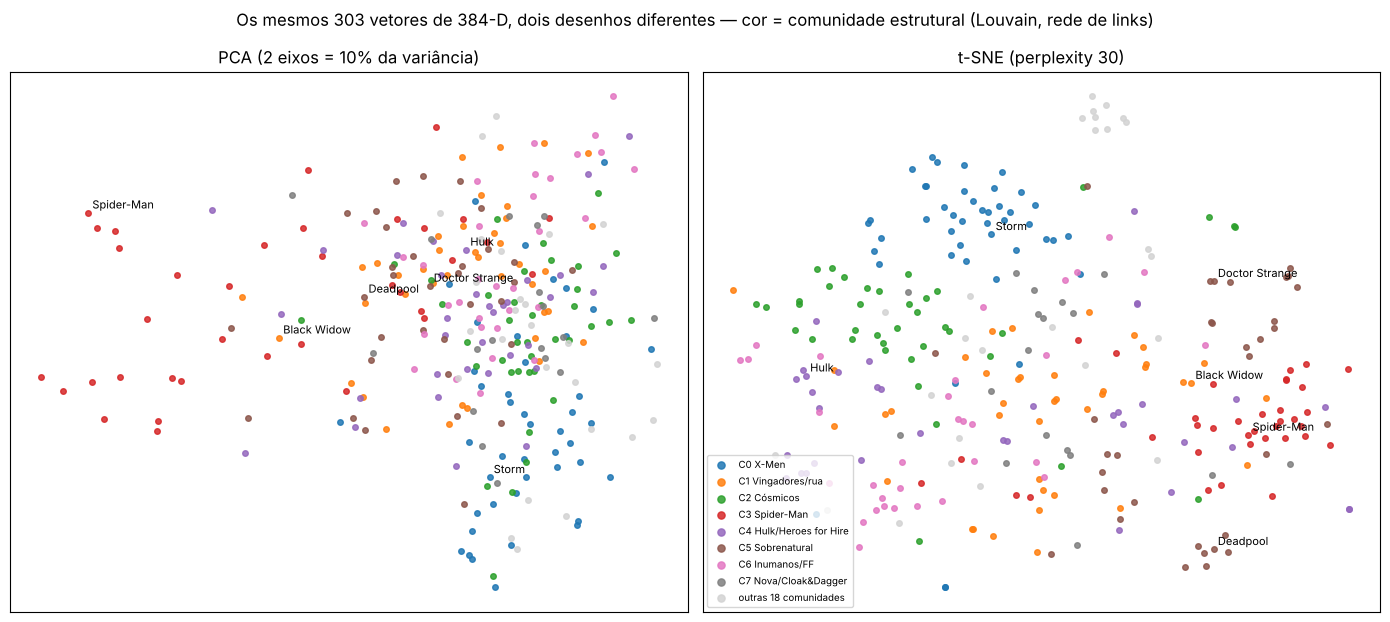

In [ ]:
emb_frozen = emb_pass.copy()
xy_pca = PCA(n_components=2, random_state=42).fit_transform(emb_pass)
xy_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(emb_pass)
assert np.array_equal(emb_frozen, emb_pass)        # as projeções não tocaram nos embeddings
np.save("data/xy_pca.npy", xy_pca); np.save("data/xy_tsne.npy", xy_tsne)

comm_col = np.array([comm_of[n] if comm_of[n] < 8 else 8 for n in IDS])
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.3))
for ax, xy, ttl in [(axes[0], xy_pca, f"PCA (2 eixos = {pca2.explained_variance_ratio_.sum():.0%} da variância)"),
                    (axes[1], xy_tsne, "t-SNE (perplexity 30)")]:
    for k in range(9):
        m = comm_col == k
        ax.scatter(xy[m, 0], xy[m, 1], s=16, color=cmap(k) if k < 8 else "lightgray",
                   label=(f"C{k} {LAB[k]}" if k < 8 else "outras 18 comunidades"), alpha=0.85)
    for nm in ["Doctor Strange", "Deadpool", "Black Widow (Natasha Romanova)", "Storm (Marvel Comics)", "Spider-Man", "Hulk"]:
        i = idx_of[by_name[nm]]; ax.annotate(nm.split(" (")[0], xy[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(fontsize=7, loc="lower left", markerscale=1.3)
fig.suptitle("Os mesmos 303 vetores de 384-D, dois desenhos diferentes — cor = comunidade estrutural (Louvain, rede de links)")
plt.tight_layout(); plt.savefig("figs/7.2_pca_vs_tsne_by_community.png", dpi=150); plt.show()

### 7.2.4 — O atlas interativo (hover = nome, clique = 5 vizinhos por cosseno no espaço original)

Escrevo um HTML autónomo com o Plotly (`figs/7.2_corpus_atlas.html`): os pontos vêm de `xy_pca`/`xy_tsne`
(pré-calculados), mas a lista do clique vem da matriz de cossenos **384-D**, nunca das distâncias no mapa. Ao
lado mostro também os 5 pontos mais próximos **no desenho**, para se ver a diferença (7.2.5). Há dois menus:
projeção (PCA / t-SNE) e cor (comunidade; no 7.4 junto LDA e BERTopic) — mudar a cor **não** recalcula as
coordenadas, só troca a cor de cada ponto (7.2.6).

In [ ]:
def atlas_html(path, colorings, title="Marvel corpus atlas"):
    """colorings: dict nome -> (lista de rótulos por página, dict rótulo -> legenda)"""
    S = emb_pass @ emb_pass.T
    data = []
    for i, pid in enumerate(IDS):
        s = S[i].copy(); s[i] = -9
        top = np.argsort(-s)[:5]
        data.append(dict(n=name[pid], c=comm_of[pid],
                         nn=[[name[IDS[j]], round(float(S[i, j]), 3), bool((pid, IDS[j]) in linked)] for j in top],
                         lead=re.sub(r"\s+", " ", marvel_pages[pid][:220])))
    payload = dict(pts=data, xy={"PCA": xy_pca.round(4).tolist(), "t-SNE": xy_tsne.round(4).tolist()},
                   col={k: [str(x) for x in v[0]] for k, v in colorings.items()},
                   leg={k: {str(a): b for a, b in v[1].items()} for k, v in colorings.items()})
    html = """<!doctype html><html><head><meta charset="utf-8"><title>%TITLE%</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>body{font-family:system-ui,sans-serif;margin:12px;color:#222} #wrap{display:flex;gap:16px;flex-wrap:wrap}
#plot{width:760px;height:640px} #side{width:430px;font-size:13px} .nn{margin:2px 0} .tag{color:#888;font-size:11px}
select{margin-right:12px} h3{margin:6px 0} .muted{color:#666}</style></head><body>
<h2>%TITLE%</h2><div class="muted">303 Marvel pages · all-MiniLM-L6-v2 · page vector = mean of ≤180-word passages.
Hover a dot for the name, click it for its 5 nearest pages by <b>cosine in the original 384-D space</b>.</div>
<p>Projection <select id="proj"><option>t-SNE</option><option>PCA</option></select>
Color <select id="color"></select> Search <input id="q" placeholder="e.g. Storm" size="18"></p>
<div id="wrap"><div id="plot"></div><div id="side"><h3 id="who">Click a dot</h3><div id="lead" class="muted"></div>
<h4>5 nearest by cosine (384-D)</h4><div id="hi"></div><h4>5 nearest dots on this 2-D map</h4><div id="lo"></div></div></div>
<script>
const D = %DATA%;
const sel = document.getElementById('color'); Object.keys(D.col).forEach(k=>{const o=document.createElement('option');o.text=k;sel.add(o)});
let cur = null;
function traces(){ const P=document.getElementById('proj').value, C=sel.value, xy=D.xy[P], lab=D.col[C];
  const groups=[...new Set(lab)]; groups.sort((a,b)=>(a==='-1'||a==='other')?1:(b==='-1'||b==='other')?-1:a.localeCompare(b,undefined,{numeric:true}));
  return groups.map(g=>{const idx=lab.map((l,i)=>l===g?i:-1).filter(i=>i>=0);
    return {x:idx.map(i=>xy[i][0]), y:idx.map(i=>xy[i][1]), customdata:idx, text:idx.map(i=>D.pts[i].n), mode:'markers', type:'scattergl',
      name:(D.leg[C][g]||g).slice(0,48), hovertemplate:'%{text}<extra></extra>', marker:{size:7, opacity:0.85, color:(g==='-1'||g==='other')?'#c8c8c8':undefined}}});}
function draw(){ Plotly.react('plot', traces(), {margin:{l:10,r:10,t:10,b:10}, xaxis:{visible:false}, yaxis:{visible:false},
  legend:{font:{size:10}}, hovermode:'closest'}); }
function show(i){ cur=i; const p=D.pts[i], xy=D.xy[document.getElementById('proj').value];
  document.getElementById('who').textContent=p.n; document.getElementById('lead').textContent=p.lead+'…';
  document.getElementById('hi').innerHTML=p.nn.map(r=>`<div class="nn">${r[1].toFixed(3)} · ${r[0]} ${r[2]?'<span class=tag>(linked)</span>':''}</div>`).join('');
  const d=xy.map((q,j)=>[j,(q[0]-xy[i][0])**2+(q[1]-xy[i][1])**2]).filter(r=>r[0]!==i).sort((a,b)=>a[1]-b[1]).slice(0,5);
  const hiNames=new Set(p.nn.map(r=>r[0]));
  document.getElementById('lo').innerHTML=d.map(r=>`<div class="nn">${D.pts[r[0]].n} ${hiNames.has(D.pts[r[0]].n)?'<span class=tag>(also cosine top-5)</span>':'<span class=tag style="color:#c33">(not in cosine top-5)</span>'}</div>`).join('');}
draw(); document.getElementById('plot').on('plotly_click', e=>show(e.points[0].customdata));
document.getElementById('proj').onchange=()=>{draw(); if(cur!==null) show(cur); document.getElementById('plot').on('plotly_click', e=>show(e.points[0].customdata));};
sel.onchange=()=>{draw(); document.getElementById('plot').on('plotly_click', e=>show(e.points[0].customdata));};
document.getElementById('q').onchange=e=>{const q=e.target.value.toLowerCase(); const i=D.pts.findIndex(p=>p.n.toLowerCase().includes(q)); if(i>=0) show(i);};
</script></body></html>"""
    html = html.replace("%TITLE%", title).replace("%DATA%", json.dumps(payload))
    open(path, "w", encoding="utf-8").write(html)
    return len(html)

comm_lab = [comm_of[n] if comm_of[n] < 8 else "other" for n in IDS]
COLORINGS = {"network community (Louvain)": (comm_lab, {**{k: f"C{k} {LAB[k]}" for k in range(8)}, "other": "18 small communities"})}
size = atlas_html("figs/7.2_corpus_atlas.html", COLORINGS)
print(f"figs/7.2_corpus_atlas.html: {size / 1e3:.0f} kB — abre no browser")

figs/7.2_corpus_atlas.html: 170 kB — abre no browser


### 7.2.5 — Vizinhos no mapa vs vizinhos por cosseno

Para cada página: dos 5 vizinhos por cosseno (384-D), quantos são também os 5 pontos mais próximos no desenho?

In [ ]:
def nn_2d(xy, i, k=5):
    d = ((xy - xy[i]) ** 2).sum(1); d[i] = np.inf
    return list(np.argsort(d)[:k])
for lbl, xy in [("PCA", xy_pca), ("t-SNE", xy_tsne)]:
    ov = np.array([len(set(nn(i)) & set(nn_2d(xy, i))) for i in range(len(IDS))])
    print(f"{lbl:5s}: em média {ov.mean():.2f} dos 5 coincidem | páginas com 0 coincidências: {(ov == 0).sum()}")
print()
for nm in ["Storm (Marvel Comics)", "Doctor Strange", "Hulk"]:
    i = idx_of[by_name[nm]]
    print(f"■ {nm}\n   cosseno 384-D: " + ", ".join(name[IDS[j]] for j in nn(i)) +
          "\n   t-SNE 2-D    : " + ", ".join(name[IDS[j]] for j in nn_2d(xy_tsne, i)) +
          "\n   PCA 2-D      : " + ", ".join(name[IDS[j]] for j in nn_2d(xy_pca, i)))

PCA  : em média 0.48 dos 5 coincidem | páginas com 0 coincidências: 208
t-SNE: em média 2.32 dos 5 coincidem | páginas com 0 coincidências: 11

■ Storm (Marvel Comics)
   cosseno 384-D: Emma Frost, Jean Grey, Surge (Marvel Comics), Jubilee (character), Cyclops (Marvel Comics)
   t-SNE 2-D    : Jubilee (character), Rachel Summers, Jean Grey, Ruby Summers, Northstar (character)
   PCA 2-D      : Powerhouse (Marvel Comics), Thena, Anole (character), Phyla-Vell, Jubilee (character)
■ Doctor Strange
   cosseno 384-D: Doctor Druid, Jericho Drumm, Alice Nugent, Miracleman (character), Captain Universe
   t-SNE 2-D    : Doctor Druid, Jericho Drumm, Ulysses Bloodstone, Elsa Bloodstone, Red Raven (Dania)
   PCA 2-D      : Black Panther (character), Captain Universe, Blue Marvel, Doctor Nemesis, Iron Man (Ultimate Marvel character)
■ Hulk
   cosseno 384-D: Devil Hulk, Hulk 2099, She-Hulk, Hulkling, Abomination (character)
   t-SNE 2-D    : Hulk 2099, Devil Hulk, Abomination (character), She-Hulk,

In [ ]:
# o caso enganador: pares que o t-SNE desenha colados mas que estão longe no espaço original
D_tsne = np.sqrt(((xy_tsne[:, None, :] - xy_tsne[None, :, :]) ** 2).sum(-1))
iu = np.triu_indices(len(IDS), 1)
close = np.argsort(D_tsne[iu])[:300]                                   # os 300 pares mais colados no desenho
worst = sorted(close, key=lambda o: S_emb[iu][o])[:5]
print("pares entre os 300 mais próximos do t-SNE, com o cosseno 384-D mais baixo:")
for o in worst:
    i, j = iu[0][o], iu[1][o]
    rank_j = int((S_emb[i] > S_emb[i, j]).sum())                       # posição de j na lista de i (0 = ele próprio)
    print(f"  {name[IDS[i]]:28s} × {name[IDS[j]]:28s} dist. t-SNE {D_tsne[i, j]:.2f} | cos {S_emb[i, j]:.3f} | j é o {rank_j}.º vizinho de i")
print(f"\n(referência: cosseno mediano entre dois pares quaisquer = {np.median(S_emb[iu]):.3f}; mediana do 5.º vizinho = "
      f"{np.median([S_emb[i, nn(i)[-1]] for i in range(len(IDS))]):.3f})")
bf, wz = idx_of[by_name["Black Fox (Robert Paine)"]], idx_of[by_name["Whizzer (Robert Frank)"]]
for i in (bf, wz):
    print(f"\n{name[IDS[i]]}: vizinhos 384-D → " + ", ".join(f"{name[IDS[j]]} {S_emb[i, j]:.2f}" for j in nn(i)))
    print("   " + re.sub(r"\s+", " ", marvel_pages[IDS[i]][:200]))

pares entre os 300 mais próximos do t-SNE, com o cosseno 384-D mais baixo:
  Black Fox (Robert Paine)     × Whizzer (Robert Frank)       dist. t-SNE 1.47 | cos 0.412 | j é o 124.º vizinho de i
  Bug (Marvel Comics)          × Captain Ultra                dist. t-SNE 1.56 | cos 0.424 | j é o 103.º vizinho de i
  Hyperion (character)         × Illuminator (Marvel Comics)  dist. t-SNE 1.60 | cos 0.480 | j é o 63.º vizinho de i
  Dogpool                      × Hit-Monkey                   dist. t-SNE 1.59 | cos 0.488 | j é o 6.º vizinho de i
  Sentry (Robert Reynolds)     × Shuri (character)            dist. t-SNE 1.60 | cos 0.491 | j é o 29.º vizinho de i

(referência: cosseno mediano entre dois pares quaisquer = 0.398; mediana do 5.º vizinho = 0.581)

Black Fox (Robert Paine): vizinhos 384-D → Black Marvel 0.66, Black Widow (Natasha Romanova) 0.54, Black Panther (character) 0.54, Black Knight (Marvel Comics) 0.54, Black Bolt 0.53
   Black Fox (Dr. Robert William Paine) is a fictional sup

**O que se vê.**

- **PCA:** em média só **≈0.5 dos 5** vizinhos coincidem e ~200 páginas não têm nenhum vizinho certo no
  desenho — dois eixos lineares guardam 10% da variância, por isso o PCA é uma vista global grosseira. Ex.: no
  PCA o Hulk aparece ao lado de The Witness, Gauntlet e Paladin; os vizinhos reais são Devil Hulk, Hulk 2099,
  She-Hulk, Hulkling e Abomination.
- **t-SNE:** muito melhor localmente (≈2.3 dos 5), porque é exatamente isso que otimiza — manter as vizinhanças.
  Mas ainda engana: a Storm aparece entre Rachel Summers, Ruby Summers e Northstar, e a Emma Frost (a vizinha nº1
  por cosseno) não está entre os 5 pontos mais próximos.
- **O caso enganador.** **Black Fox (Robert Paine)** e **Whizzer (Robert Frank)** estão desenhados colados no
  t-SNE (distância 1.47, entre os pares mais próximos do mapa), mas o cosseno entre eles é **0.41** — abaixo do
  5.º vizinho típico (0.58) e quase no cosseno mediano de dois pares quaisquer (0.40): o Whizzer é só o
  **124.º** vizinho do Black Fox. O que aconteceu: os dois têm vizinhos fracos e "puxados" pelo mesmo ponto — o
  **Black Marvel** é o vizinho nº1 de ambos (0.66 e 0.65; personagens da Golden Age/Timely). O t-SNE só garante
  que os vizinhos de cada ponto ficam perto, **não** que o que está perto é vizinho; para pôr os dois junto do
  Black Marvel, pô-los juntos um do outro. A proximidade visual é um artefacto do desenho; quem decide é o
  cosseno 384-D (e depois ler as páginas: as aberturas acima — o Dr. Robert Paine e um herói velocista da Golden
  Age — não descrevem nada em comum).
- Lição da página: **os vizinhos calculam-se no espaço original**; o mapa só serve para explorar, e distâncias
  entre grupos afastados no t-SNE nem sequer têm interpretação.

### 7.2.6 — As mesmas coordenadas, colorir por comunidade estrutural

A figura do 7.2.3 já está colorida pelas comunidades Louvain (sem recalcular nada: `xy_tsne` é calculado uma
vez e só a cor muda). Quão "arrumadas" estão as comunidades no espaço do texto? Comparo, para cada comunidade
grande, o cosseno médio **dentro** dela com o cosseno médio para fora:

In [ ]:
rows = []
for k in range(8):
    m = np.array([comm_of[n] == k for n in IDS])
    Sin = S_emb[np.ix_(m, m)][np.triu_indices(m.sum(), 1)].mean(); Sout = S_emb[np.ix_(m, ~m)].mean()
    same_nn = np.mean([np.mean([comm_of[IDS[j]] == k for j in nn(i)]) for i in np.where(m)[0]])
    rows.append(dict(comunidade=f"C{k} {LAB[k]}", páginas=m.sum(), cos_dentro=round(Sin, 3), cos_fora=round(Sout, 3),
                     vizinhos_na_mesma_comunidade=f"{same_nn:.0%}", base=f"{m.mean():.0%}"))
print(pd.DataFrame(rows).to_string(index=False))

             comunidade  páginas  cos_dentro  cos_fora vizinhos_na_mesma_comunidade base
               C0 X-Men       44       0.481     0.392                          75%  15%
      C1 Vingadores/rua       40       0.450     0.411                          29%  13%
            C2 Cósmicos       39       0.447     0.395                          63%  13%
          C3 Spider-Man       36       0.517     0.397                          71%  12%
C4 Hulk/Heroes for Hire       35       0.417     0.399                          36%  12%
        C5 Sobrenatural       33       0.423     0.381                          50%  11%
         C6 Inumanos/FF       32       0.436     0.403                          41%  11%
   C7 Nova/Cloak&Dagger       18       0.440     0.411                          24%   6%


**Leitura.** Todas as comunidades estruturais têm cosseno médio interno maior do que externo, e os vizinhos de
texto caem na mesma comunidade muito acima do acaso (coluna `base`). As mais "textuais" são as que têm um
**tema** forte: **X-Men** (75% dos vizinhos de texto na própria comunidade — mutantes), **Spider-Man** (71% — o
universo-aranha e os simbiontes), **Cósmicos** (63% — espaço, deuses, energia) e, a meio, **Sobrenatural**
(50%). No t-SNE formam manchas compactas. As comunidades definidas por *equipas* ou *cruzamentos editoriais* —
**Vingadores/rua** (29%), Nova/Cloak & Dagger (24%), Hulk/Heroes for Hire (36%) — espalham-se pelo mapa: os
links juntam-nas, mas as páginas falam de coisas diferentes. É a frase da página: o encoder mede *about-ness*, a
rede mede *quem se liga a quem* — e coincidem só em parte (2.5 dos 10 vizinhos).

---
## 📘 Exemplos da página — Secção 3 · Different ways to split up the same corpus

**Bloco 1 — BERTopic sobre os mesmos embeddings do atlas**, com o filtro de nomes da semana 6 (`proper`).
A página: "When we ran this, BERTopic found **four topics** and left **110** of the 303 pages as outliers";
depois de `reduce_outliers`, **166, 62, 44 e 31** páginas; um tópico *symbiote* (família Spider-Man), um
*mutants, mutant, team, powers* (X-Men) e dois "montes genéricos" (*character, series, appears, new*);
35 das 44 páginas de uma comunidade da rede caem no tópico dos mutantes.

In [ ]:
from bertopic import BERTopic
from umap import UMAP

embeddings = emb_pass
topic_model = BERTopic(
    embedding_model=model,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                    metric="cosine", random_state=42),      # seeded, so the run repeats
    vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper)),
    min_topic_size=10,
)
topics, probs = topic_model.fit_transform(texts, embeddings=embeddings)
topic_model.get_topic_info()[["Topic", "Count", "Name"]]

,Topic,Count,Name
0,-1,104,-1_character_series_new_appears
1,0,131,0_character_appears_series_new
2,1,40,1_symbiote_character_appears_new
3,2,28,2_new_mutants_mutant_character


In [ ]:
topics = np.array(topics)
bt_new = np.array(topic_model.reduce_outliers(texts, topics, strategy="embeddings", embeddings=embeddings))
print(f"tópicos (sem o -1): {len(set(topics)) - (-1 in topics)} | outliers (-1): {(topics == -1).sum()} de {len(topics)}")
print("depois de reduce_outliers:", dict(sorted(Counter(bt_new.tolist()).items())))
bt_words = {t: [w for w, _ in topic_model.get_topic(t)[:8]] for t in sorted(set(topics)) if t != -1}
for t, ws in bt_words.items():
    print(f"  tópico {t}: " + ", ".join(ws))
ct_bt = pd.crosstab(pd.Series(bt_new, name="BERTopic"), pd.Series([comm_of[n] if comm_of[n] < 8 else 8 for n in IDS], name="comunidade"))
ct_bt.columns = [f"C{c}" if c < 8 else "resto" for c in ct_bt.columns]
print("\nBERTopic (depois de reduce_outliers) × comunidade Louvain:\n", ct_bt.to_string())

tópicos (sem o -1): 3 | outliers (-1): 104 de 303
depois de reduce_outliers: {0: 219, 1: 50, 2: 34}
  tópico 0: character, appears, series, new, later, time, comic, team
  tópico 1: symbiote, character, appears, new, series, comic, version, later
  tópico 2: new, mutants, mutant, character, powers, team, time, later

BERTopic (depois de reduce_outliers) × comunidade Louvain:
           C0  C1  C2  C3  C4  C5  C6  C7  resto
BERTopic                                       
0         12  34  39   8  31  23  32  16     24
1          1   6   0  28   4   9   0   2      0
2         31   0   0   0   0   1   0   0      2


**Comparação com a página.** A minha corrida dá **3 tópicos + 104 outliers** (a página: 4 + 110). Os
embeddings são os mesmos (os números da Secção 2 batem exatamente), por isso a diferença vem do UMAP/HDBSCAN:
o `random_state` fixa a semente, mas o resultado do UMAP também depende da versão da biblioteca (e do
`numba`). É precisamente o ponto da secção — uma partição por densidade num corpus de 303 documentos é
frágil. O que sobrevive é o mesmo: um tópico **symbiote** (família Spider-Man, quase todo dentro de C3), um
tópico **mutants/mutant** (quase todo dentro de C0 X-Men: na minha corrida **31 das 44** páginas da comunidade
X-Men; a página tem 35 das 44) e um **monte genérico** (*character, appears, series, new*) que recebe tudo o
resto. Com os defaults (sem stopwords) os tópicos seriam *the, and, of, to* — verifico:

In [ ]:
tm_default = BERTopic(embedding_model=model, umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42))
t_def, _ = tm_default.fit_transform(texts, embeddings=embeddings)
for t in sorted(set(t_def))[:4]:
    print(f"defaults, tópico {t}: " + ", ".join(w for w, _ in tm_default.get_topic(t)[:8]))

defaults, tópico -1: the, and, of, to, in, his, by, is
defaults, tópico 0: the, and, of, to, in, his, by, he
defaults, tópico 1: the, spider, and, to, in, of, man, her
defaults, tópico 2: the, and, of, to, in, men, her, is


## Exercício 7.3 — Same documents, different groupings (🧠 learn)

> Keep the 303 pages fixed and change only the information used to group them.
>
> 1. In one sentence each, explain what information an LDA topic, an embedding-based text cluster, and a structural network community use to place two Marvel pages together.
> 2. LDA gives a document a mixture over topics, while a clustering algorithm may assign it to one group. Explain why those are different kinds of outputs.
> 3. Suppose an LDA topic and a BERTopic cluster contain many of the same pages. Give one reason that agreement is interesting and one reason it is not proof that either model found the "true" topic.
> 4. Explain why two circles appearing close on an intertopic map is weaker evidence than a similarity calculated in the original representation.

### 7.3.1 — Que informação junta duas páginas

- **Tópico LDA:** duas páginas ficam juntas quando **as mesmas palavras aparecem com frequências parecidas**
  nelas — só contagens (bag of words; baralhar as palavras dá o mesmo resultado).
- **Cluster de embeddings (BERTopic):** duas páginas ficam juntas quando o **encoder pré-treinado** lhes dá
  vetores próximos (o que o modelo "entende" que o texto é sobre, com ordem e contexto), e o UMAP+HDBSCAN as põe
  na mesma zona densa — podem estar juntas sem partilhar vocabulário.
- **Comunidade estrutural:** duas páginas ficam juntas quando **se ligam muito uma à outra e ao mesmo grupo
  de páginas** pelos hyperlinks da Wikipédia (modularidade) — o texto nem é lido.

### 7.3.2 — Mistura vs atribuição

O LDA dá, para cada documento, um vetor $\theta_d$ que **soma 1 sobre os tópicos** — uma resposta graduada
("70% mutantes, 20% crime, 10% espaço"), em que a página pertence a todos os tópicos com pesos diferentes:

$$
\theta_d = (\theta_{d1},\dots,\theta_{dK}),\qquad \sum_{k}\theta_{dk}=1,\ \ \theta_{dk}\ge 0
$$

Um algoritmo de clustering (HDBSCAN no BERTopic) dá **um rótulo** por documento (ou −1 = "não sei") — uma
partição. São objetos diferentes: com a mistura posso dizer que o Doctor Strange é metade sobrenatural e metade
outra coisa; com a partição tenho de escolher uma caixa. Para comparar os dois tenho de **perder informação**
(pegar no tópico de maior peso, $\arg\max_k \theta_{dk}$) — e uma página 0.35/0.35/0.30 vai parar a uma caixa
quase por acaso.

### 7.3.3 — Concordância LDA × BERTopic

- **Porque é interessante:** os dois métodos usam **informação diferente** (contagens de palavras vs vetores
  de um modelo pré-treinado) e **algoritmos diferentes**; se chegam ao mesmo grupo de páginas, esse grupo é
  provavelmente uma regularidade real do corpus e não um artefacto de um método (é como dois instrumentos
  independentes a medirem o mesmo).
- **Porque não é prova de um "tópico verdadeiro":** podem partilhar o mesmo viés — o mesmo pré-processamento
  (a lista de stopwords, o filtro de nomes), o mesmo corpus (que já tem a estrutura editorial da Wikipédia), e
  ambos dependem de escolhas (K, `min_topic_size`, sementes). E o que coincide pode ser algo pouco temático:
  no corpus Marvel, ambos podiam juntar páginas pela **franquia** ou pelo **boilerplate** ("voiced by…, video
  games…"), não por um tema. Não existe um "tópico verdadeiro" fora de uma pergunta; a concordância é
  evidência de robustez, não de verdade.

### 7.3.4 — Porque o mapa intertópico é evidência fraca

O mapa intertópico é **mais uma projeção 2D** (das representações c-TF-IDF dos tópicos), por isso tem o mesmo
problema do atlas: comprimir muitas dimensões em duas distorce distâncias; dois círculos podem aparecer perto
só porque o método teve de os pôr nalgum lado (e o tamanho do círculo é o número de documentos, não
semelhança). Uma semelhança calculada **na representação original** (o cosseno entre os vetores de palavras dos
dois tópicos, ou entre os embeddings dos documentos) é um número sobre os objetos reais; a distância no mapa é
um número sobre o desenho.

## Exercício 7.4 — Compare groupings on Marvel, as code (🔬 tool)

> Use the same documents throughout so the comparison is actually about the representation and grouping method.
>
> 1. Take your LDA model from week 6 and keep both each page's full topic mixture and its highest-weight topic.
> 2. Run BERTopic on the Marvel pages. Record the embedding model and the main settings you changed from the defaults. Inspect representative words and documents before you give a cluster a human-readable label.
> 3. Make one compact view that compares LDA topic, BERTopic topic, and network community for the same pages. A contingency table, heatmap or color toggle on your corpus map is enough.
> 4. Find one place where two groupings agree and one where they disagree. Read the relevant pages and inspect the network links before you explain either case.
> 5. Change one reasonable BERTopic choice, such as the minimum cluster size or embedding model. Which groups survive the change and which do not?

### 7.4.1 — O LDA da semana 6 (o mesmo modelo: filtro de nomes, `min_df=5`, `max_df=0.5`, K = 8, seed 0)

In [ ]:
vec_lda = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper), min_df=5, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
X_lda = vec_lda.fit_transform(texts)
lda = LatentDirichletAllocation(n_components=8, random_state=0, learning_method="batch", max_iter=50)
theta = lda.fit_transform(X_lda)                 # a mistura completa: 303 × 8, cada linha soma 1
lda_top = theta.argmax(1)                         # o tópico de maior peso
v_lda = vec_lda.get_feature_names_out()
phi = lda.components_ / lda.components_.sum(1, keepdims=True)
lda_words = {k: [v_lda[i] for i in phi[k].argsort()[::-1][:8]] for k in range(8)}
for k in range(8):
    print(f"T{k} | {np.mean(theta[:, k]):.0%} do peso | argmax de {(lda_top == k).sum():3d} páginas | " + " ".join(lda_words[k]))
print("\nmisturas guardadas:", theta.shape, "| soma das linhas:", theta.sum(1).min().round(6), "–", theta.sum(1).max().round(6))
print("páginas cujo tópico principal tem < 50% do peso:", (theta.max(1) < 0.5).sum())

T0 | 28% do peso | argmax de  90 páginas | father written voiced issues list best stories film
T1 | 3% do peso | argmax de   7 páginas | brain mother mutants android mission truth mutant create
T2 | 39% do peso | argmax de 141 páginas | mutant mutants energy list members powerful ranked reality
T3 | 4% do peso | argmax de  11 páginas | zombie gun stories adventures art horse army origin
T4 | 2% do peso | argmax de   3 páginas | vampire blood vampires living true undead cure fly
T5 | 13% do peso | argmax de  22 páginas | voiced vol god hand incarnation episode brother playable
T6 | 7% do peso | argmax de  15 páginas | identity hand government costume shield solo major trained
T7 | 6% do peso | argmax de  14 páginas | symbiote suit incarnation voiced costume host playable anti

misturas guardadas: (303, 8) | soma das linhas: 1.0 – 1.0
páginas cujo tópico principal tem < 50% do peso: 81


Os mesmos 8 tópicos da semana 6 (mesmos parâmetros e semente). Etiquetas **minhas**, depois de ver as palavras
e as páginas dominantes (célula abaixo): **T0** boilerplate de média/publicação (*father, written, voiced,
issues, list, best*), **T2** um tópico largo de "mutantes e poderes" (*mutant, mutants, energy, members,
powerful*) que domina 141 páginas, **T7** simbiontes, **T4** vampiros (Morbius), **T3** western/zombies (*gun,
horse, zombie*), **T6** espionagem/militar (*identity, government, shield, trained*), **T5** deuses e versões de
média, **T1** um grupinho de 7 páginas (*brain, android*). 81 páginas têm o tópico principal abaixo de 50% — a
mistura importa.

In [ ]:
for k in range(8):
    tops = theta[:, k].argsort()[::-1][:4]
    print(f"T{k}: " + "; ".join(f"{name[IDS[i]]} {theta[i, k]:.2f}" for i in tops))

T0: Ms. Marvel 1.00; Phil Grayfield 1.00; Bug (Marvel Comics) 0.99; Black Widow (Natasha Romanova) 0.98
T1: Isaiah Bradley 1.00; Fabio Medina 1.00; Junior Juniper 1.00; Crane Mother 0.99
T2: Wolverine (Ultimate Marvel character) 1.00; Radian (Morituri) 1.00; Blackthorn (character) 1.00; Vyking 1.00
T3: Machine Man 1.00; Doctor Druid 1.00; Zombie (comics) 1.00; Solomon Kane (comics) 1.00
T4: Morbius 1.00; Black Jack Tarr 0.44; Spitfire (character) 0.39; Human Fly (character) 0.30
T5: Red Wolf (comics) 1.00; Gargoyle (comics) 1.00; Thin Man (character) 1.00; Killpower 0.99
T6: Bucky (Marvel Comics) 1.00; Silencer (comics) 1.00; Solo (Marvel Comics) 1.00; Hit-Monkey 1.00
T7: Eddie Brock 1.00; Venom (character) 1.00; Thunderbolt (Marvel Comics) 0.99; Emrys Killebrew 0.99


### 7.4.2 — BERTopic: modelo, escolhas, palavras e documentos representativos

**Embedding:** `all-MiniLM-L6-v2`, vetor da página = média das passagens de ≤180 palavras (o mesmo do atlas).
**Mudanças face aos defaults:** (1) `embeddings=` os meus vetores (não deixo o BERTopic truncar as páginas);
(2) UMAP com `random_state=42` (para a corrida se repetir; o default não tem semente); (3) `vectorizer_model`
com stopwords inglesas **+ filtro de nomes** (senão os tópicos são *the, and, of*); (4) `min_topic_size=10`
(default também 10). O resto (HDBSCAN, c-TF-IDF) fica por omissão.

In [ ]:
rep_docs = topic_model.get_representative_docs()
for t, ws in bt_words.items():
    members = [IDS[i] for i in np.where(topics == t)[0]]
    print(f"■ BERTopic {t} ({len(members)} páginas antes de reduce_outliers): " + ", ".join(ws))
    print("   representativos:", [d[:60].replace("\n", " ") for d in rep_docs[t]])
    print("   membros com mais ligações:", ", ".join(name[n] for n in sorted(members, key=lambda n: -deg[n])[:10]))
out_members = [IDS[i] for i in np.where(topics == -1)[0]]
print(f"■ outliers (-1, {len(out_members)} páginas), alguns:", ", ".join(name[n] for n in sorted(out_members, key=lambda n: -deg[n])[:12]))

■ BERTopic 0 (131 páginas antes de reduce_outliers): character, appears, series, new, later, time, comic, team
   representativos: ['Star-Lord (Peter Jason Quill) is a fictional character appea', 'Hercules Panhellenios is a character appearing in American c', 'She-Hulk (Jennifer Susan Walters) is a  character appearing ']
   membros com mais ligações: Hulk, Doctor Strange, She-Hulk, Black Panther (character), Hank Pym, Hercules (Marvel Comics), Iron Fist (character), Adam Warlock, Quasar (character), Blade (character)
■ BERTopic 1 (40 páginas antes de reduce_outliers): symbiote, character, appears, new, series, comic, version, later
   representativos: ['Black Cat is a character appearing in American comic books p', 'Venom, known formally as "the Symbiote", is a character appe', 'Spider-Woman (Jessica Drew) is a character appearing in Amer']
   membros com mais ligações: Spider-Man, Venom (character), Black Cat (Marvel Comics), Cloak and Dagger (characters), Black Widow (Natasha Romano

**Etiquetas (minhas, depois de ler):** tópico **1 = "Spider-Man e Nova Iorque de rua"** — a palavra distintiva é
*symbiote* e o núcleo é a família-aranha (Spider-Man, Venom, Eddie Brock, Black Cat, as Spider-Women, Mayday
Parker), mas também entram Black Widow, Jessica Jones e Cloak and Dagger: heroínas e heróis de rua de Nova
Iorque que aparecem nas mesmas histórias. Tópico **2 = "mutantes / X-Men"** (Wolverine, Jean Grey, Emma Frost,
Storm, Cyclops, Cable…). Tópico **0 = "monte genérico"** — as palavras (*character, appears, series, new*) são
vocabulário editorial da Wikipédia, não um tema; é onde o HDBSCAN põe o que não tem densidade suficiente
(Hulk, Doctor Strange, She-Hulk, Black Panther, os cósmicos…). Os outliers (Deadpool, Scarlet Witch, Luke Cage,
Moon Knight, Ghost Rider…) não formam grupo nenhum a este `min_topic_size`.

### 7.4.3 — Uma vista compacta: LDA × BERTopic × comunidade

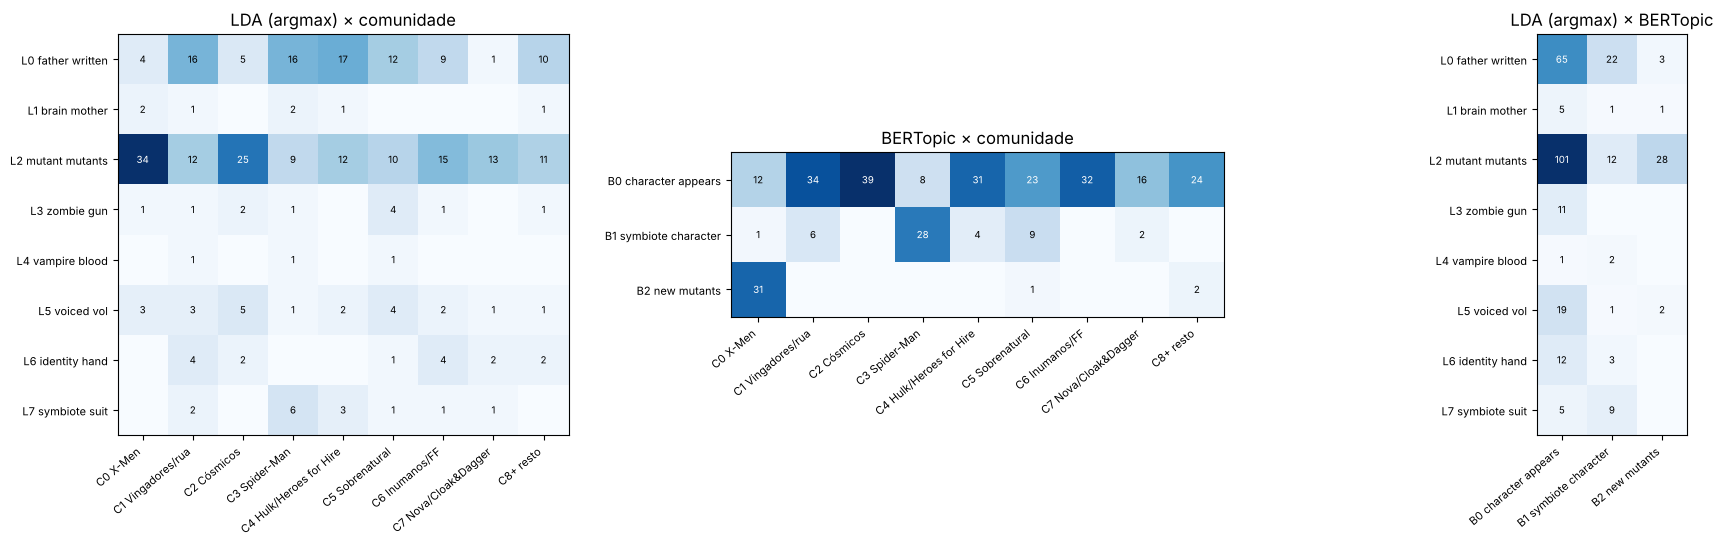

LDA vs comunidade        ARI = 0.035 | NMI = 0.102
BERTopic vs comunidade   ARI = 0.080 | NMI = 0.269
LDA vs BERTopic          ARI = 0.008 | NMI = 0.089
atlas atualizado com 3 colorações


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
lda_lab = {k: f"L{k} " + " ".join(lda_words[k][:2]) for k in range(8)}
bt_lab = {t: f"B{t} " + " ".join(bt_words[t][:2]) if t in bt_words else "B-1 outlier" for t in set(bt_new.tolist()) | {-1}}
comm8 = np.array([comm_of[n] if comm_of[n] < 8 else 8 for n in IDS])
cm_lab = {k: (f"C{k} {LAB[k]}" if k < 8 else "C8+ resto") for k in range(9)}

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (a, b, la, lb, ttl) in zip(axes, [
        (lda_top, comm8, lda_lab, cm_lab, "LDA (argmax) × comunidade"),
        (bt_new, comm8, bt_lab, cm_lab, "BERTopic × comunidade"),
        (lda_top, bt_new, lda_lab, bt_lab, "LDA (argmax) × BERTopic")]):
    ct = pd.crosstab(pd.Series([la[x] for x in a], name="r"), pd.Series([lb[x] for x in b], name="c"))
    im = ax.imshow(ct.values, cmap="Blues")
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index, fontsize=8)
    for (r, c), v in np.ndenumerate(ct.values):
        if v: ax.text(c, r, v, ha="center", va="center", fontsize=7, color="white" if v > ct.values.max() / 2 else "black")
    ax.set_title(ttl)
plt.tight_layout(); plt.savefig("figs/7.4_three_groupings.png", dpi=150); plt.show()

pairs_ = {"LDA vs comunidade": (lda_top, comm8), "BERTopic vs comunidade": (bt_new, comm8), "LDA vs BERTopic": (lda_top, bt_new)}
for k_, (a, b) in pairs_.items():
    print(f"{k_:24s} ARI = {adjusted_rand_score(a, b):.3f} | NMI = {normalized_mutual_info_score(a, b):.3f}")

# junto as duas novas cores ao atlas (as coordenadas são as mesmas)
COLORINGS["LDA topic (argmax, week 6)"] = (lda_top.tolist(), lda_lab)
COLORINGS["BERTopic topic (before reduce_outliers)"] = (topics.tolist(), {**{t: f"B{t} " + ", ".join(bt_words[t][:4]) for t in bt_words}, -1: "outlier (-1)"})
atlas_html("figs/7.2_corpus_atlas.html", COLORINGS); print("atlas atualizado com 3 colorações")

### 7.4.4 — Onde concordam e onde discordam

In [ ]:
k_mut_lda = max(range(8), key=lambda k: phi[k, vec_lda.vocabulary_["mutant"]] if "mutant" in vec_lda.vocabulary_ else 0)
k_mut_bt = [t for t, ws in bt_words.items() if "mutants" in ws or "mutant" in ws][0]
C_X = 0
A = {IDS[i] for i in np.where(lda_top == k_mut_lda)[0]}; B = {IDS[i] for i in np.where(bt_new == k_mut_bt)[0]}; C = set(P_louvain[C_X])
print(f"LDA 'mutant' = T{k_mut_lda} ({len(A)} pág.), BERTopic 'mutants' = {k_mut_bt} ({len(B)} pág.), C0 X-Men ({len(C)} pág.)")
print(f"  |BERTopic ∩ C0| = {len(B & C)} ({len(B & C) / len(B):.0%} do tópico) | |LDA ∩ C0| = {len(A & C)} ({len(A & C) / len(A):.0%}) | |LDA ∩ BERTopic| = {len(A & B)}")
both3 = A & B & C
print(f"  nos três: {len(both3)} →", ", ".join(sorted(name[n] for n in both3))[:400])

# discordância 1: páginas da comunidade X-Men que o BERTopic NÃO põe nos mutantes
xmen_not_bt = sorted(C - B, key=lambda n: -deg[n])
print(f"\nC0 X-Men mas fora do tópico BERTopic 'mutants' ({len(xmen_not_bt)}):", ", ".join(name[n] for n in xmen_not_bt[:14]))
# discordância 2: páginas do tópico BERTopic 'mutants' que não estão na comunidade X-Men
bt_not_xmen = sorted(B - C, key=lambda n: -deg[n])
print(f"BERTopic 'mutants' mas fora de C0 ({len(bt_not_xmen)}):", ", ".join(f"{name[n]} (C{comm_of[n]})" for n in bt_not_xmen))

def links_into(pid, group):
    nb = set(G.neighbors(pid)); return len(nb & group), len(nb)
for nm in ["Scarlet Witch", "Phoenix (Guardians of the Galaxy)", "Wolverine (character)"]:
    if nm not in by_name: continue
    pid = by_name[nm]; i = idx_of[pid]
    inx, tot = links_into(pid, C)
    print(f"\n{nm}: comunidade C{comm_of[pid]} | BERTopic {bt_new[i]} | LDA T{lda_top[i]} (θ = " + ", ".join(f"T{k} {theta[i, k]:.2f}" for k in theta[i].argsort()[::-1][:3]) + ")"
          f" | links para C0: {inx} de {tot} | cos-vizinhos: " + ", ".join(name[IDS[j]] for j in nn(i)))

LDA 'mutant' = T2 (141 pág.), BERTopic 'mutants' = 2 (34 pág.), C0 X-Men (44 pág.)
  |BERTopic ∩ C0| = 31 (91% do tópico) | |LDA ∩ C0| = 34 (24%) | |LDA ∩ BERTopic| = 28
  nos três: 25 → Anole (character), Betsy Braddock, Box (comics), Cable (character), Cyclops (Marvel Comics), Emma Frost, Empath (character), G. W. Bridge, Hellion (character), Jean Grey, Jubilee (character), Korvus, Leech (character), Magician (Marvel Comics), Northstar (character), Oya (comics), Phoenix (Guardians of the Galaxy), Rachel Summers, Rockslide (character), Ruby Summers, Rusty Collins, Shatterstar, Su

C0 X-Men mas fora do tópico BERTopic 'mutants' (13): Scarlet Witch, Doctor Nemesis, Vulcan (Marvel Comics), Gladiator (Kallark), Doom 2099, Puck (Marvel Comics), Guardian (Marvel Comics), Vindicator (comics), Ch'od, Wild Child (character), Golem (Marvel Comics), Blue Bullet, Junior Juniper
BERTopic 'mutants' mas fora de C0 (3): Agent X (Marvel Comics) (C5), Scaredycat (C8), Toxyn (C8)

Scarlet Witch: comunid

**Concordância — o tópico BERTopic dos mutantes e a comunidade X-Men.** Das **34** páginas do tópico
*mutants* (depois de `reduce_outliers`), **31 (91%)** estão na comunidade estrutural C0: o encoder, sem ver um
único link, reencontra a família X-Men (Cyclops, Jean Grey, Emma Frost, Betsy Braddock, Jubilee, Northstar…). Ao
ler as aberturas vê-se porquê: as páginas descrevem-nas **como mutantes**, membros das mesmas equipas e eventos —
e é exatamente por isso que se ligam umas às outras na Wikipédia. Tema, equipa e rede coincidem; 25 páginas estão
nos três grupos (incluindo o tópico LDA T2).

**Discordância 1 — o LDA "mutante" é outra coisa.** O tópico LDA com mais peso em *mutant* (T2) é **enorme**
(141 páginas, só 24% delas na comunidade X-Men): é um tópico genérico de "poderes, energia, membros, ranking" que
por acaso tem *mutant* no topo. Daí o ARI LDA × BERTopic ≈ 0.01: um tópico LDA é uma distribuição sobre palavras
partilhada por muitas páginas em proporções diferentes, não um grupo de páginas — o *argmax* transforma-o numa
caixa larguíssima.

**Discordância 2 — X-Men na rede, não no texto.** 13 páginas da comunidade X-Men ficam fora do tópico *mutants*.
Várias são de **equipas vizinhas** que a rede cola aos X-Men pelos cruzamentos: Alpha Flight (Puck, Guardian,
Vindicator), o império Shi'ar e os Starjammers (Gladiator, Ch'od, Vulcan). As páginas delas falam do Canadá, do
espaço e de impérios alienígenas, não de mutantes; os links vêm de histórias partilhadas. E a **Scarlet Witch**:
a rede põe-na em C0 (9 dos 32 links vão para C0 — a família Magneto/Quicksilver), o LDA dá-lhe 0.76 de T2, mas o
encoder põe-na ao lado de Quicksilver, Speed, Ms. Marvel e Spider-Woman (heroínas/família, Vingadores, MCU) e o
BERTopic deixa-a fora do tópico dos mutantes. Nenhum dos três está errado: a rede diz "pertence a esta família
editorial", o texto diz "esta página é sobre outra coisa".

### 7.4.5 — Mudar uma escolha do BERTopic

Duas mudanças razoáveis, uma de cada vez: `min_topic_size` 10 → **5** e → **15**; e o **embedding** passagens →
**truncado a 256** (o default do `encode`). Para cada tópico original, procuro o tópico da nova corrida com
maior sobreposição (Jaccard dos conjuntos de páginas, sem outliers).

In [ ]:
def run_bt(emb, mts=10):
    tm = BERTopic(embedding_model=model, umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
                  vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper)), min_topic_size=mts)
    t, _ = tm.fit_transform(texts, embeddings=emb)
    return tm, np.array(t)
variants = {"min_topic_size=5": run_bt(emb_pass, 5), "min_topic_size=15": run_bt(emb_pass, 15), "embedding truncado (256)": run_bt(emb_trunc, 10)}
rows = []
for vname, (tm, tt) in variants.items():
    print(f"■ {vname}: {len(set(tt)) - (-1 in tt)} tópicos, {(tt == -1).sum()} outliers")
    for t2 in sorted(set(tt) - {-1}):
        print(f"     {t2:2d} ({(tt == t2).sum():3d}): " + ", ".join(w for w, _ in tm.get_topic(t2)[:6]))
    for t, ws in bt_words.items():
        a = set(np.where(topics == t)[0])
        best = max(((len(a & set(np.where(tt == t2)[0])) / len(a | set(np.where(tt == t2)[0])), t2) for t2 in set(tt) - {-1}), default=(0, None))
        rows.append(dict(variante=vname, tópico_original=f"{t} " + ", ".join(ws[:3]), melhor_match=best[1], jaccard=round(best[0], 2)))
print(pd.DataFrame(rows).pivot(index="tópico_original", columns="variante", values="jaccard").to_string())

■ min_topic_size=5: 14 tópicos, 105 outliers
      0 ( 36): symbiote, character, appears, new, comic, series
      1 ( 33): mutants, mutant, new, team, powers, character
      2 ( 23): original, costume, character, story, new, later
      3 ( 16): appears, character, cosmic, new, voiced, series
      4 ( 16): character, power, series, new, later, appears
      5 ( 11): vampire, blood, vampires, series, character, later
      6 (  9): character, gamma, appears, series, list, heroes
      7 (  9): process, effect, team, death, recipients, generation
      8 (  9): new, team, powers, energy, suit, field
      9 (  8): series, new, story, character, island, appears
     10 (  7): series, character, healing, run, characters, death
     11 (  7): series, martial, character, father, new, issue
     12 (  7): vol, reprints, paperback, trade, gun, spirit
     13 (  7): armor, character, 2020, suit, superhero, new
■ min_topic_size=15: 4 tópicos, 131 outliers
      0 ( 76): character, appears, ne

**O que sobrevive.** Os tópicos com uma palavra distintiva forte reaparecem em todas as variantes: **simbiontes**
(Jaccard 0.85 / 0.98 / 0.74 com `min_topic_size` 5 / 15 / embedding truncado) e **mutantes** (0.85 / 0.88 /
0.57). O **monte genérico** não sobrevive (0.17 / 0.56 / 0.14): com `min_topic_size=5` o HDBSCAN parte-o em 14
tópicos — aparecem grupos que estavam escondidos (vampiros, *gamma* = família Hulk, artes marciais, armaduras, um
tópico de *reprints/paperback* que é boilerplate editorial) —, com 15 fica com 4 tópicos e 131 outliers; com o
embedding truncado (só a introdução de cada página) os grupos mudam porque o encoder vê outro texto (e os
mutantes perdem metade da sobreposição). Conclusão: "o corpus tem N tópicos" é uma frase sobre os parâmetros; o
que vale a pena reportar é o que sobrevive (mutantes, simbiontes) e tratar o resto como frágil.

---
## 📘 Exemplos da página — Secção 4 · Sentiment as a measurement

**O léxico de brincar da página** (`wonderful +2, good +1, bad −1, terrible −2`) — escrito à mão, para o 7.5.

In [ ]:
TOY = {"wonderful": 2, "good": 1, "bad": -1, "terrible": -2}
def toy_score(s):
    toks = re.findall(r"[a-z']+", s.lower())
    hits = [(t, TOY[t]) for t in toks if t in TOY]
    return sum(v for _, v in hits), hits
for s in ["good but terrible", "not good", "The movie was wonderful", "I just love being stuck in traffic"]:
    print(f"{s!r:40s} → {toy_score(s)}")

'good but terrible'                      → (-1, [('good', 1), ('terrible', -2)])
'not good'                               → (1, [('good', 1)])
'The movie was wonderful'                → (2, [('wonderful', 2)])
'I just love being stuck in traffic'     → (0, [])


**Bloco 1 — o classificador pré-treinado da página.** Deve dar POSITIVE 1.000, NEGATIVE 1.000, POSITIVE
0.998, POSITIVE 0.999. (Com o cache, o `pipeline` é a função `sst2` do setup, que devolve sinal × confiança.)

In [ ]:
page_examples = ["The movie was good.",
                 "The movie was not good.",
                 "I just love being stuck in traffic.",
                 "The hero died, but saved everyone in the city."]
if HF_LIVE:
    from transformers import pipeline
    sentiment = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
    print(sentiment(page_examples))
for s, v in zip(page_examples, sst2(page_examples)):
    print(f"{'POSITIVE' if v > 0 else 'NEGATIVE'} {abs(v):.3f}  {s}")
# [{'label': 'POSITIVE', 'score': 1.000}, {'label': 'NEGATIVE', 'score': 1.000},
#  {'label': 'POSITIVE', 'score': 0.998}, {'label': 'POSITIVE', 'score': 0.999}]

POSITIVE 1.000  The movie was good.
NEGATIVE 1.000  The movie was not good.
POSITIVE 0.998  I just love being stuck in traffic.
POSITIVE 0.999  The hero died, but saved everyone in the city.


**"Point it at the Marvel pages themselves"** (máx. 512 word pieces, `truncation=True`): a página diz
**179 de 303 NEGATIVE**, Jubilee NEGATIVE 0.987, Doctor Strange NEGATIVE 0.931, Storm POSITIVE 1.000.

In [ ]:
page_sent = sst2(texts)
print(f"NEGATIVE: {(page_sent < 0).sum()} de {len(texts)}")
for nm in ["Jubilee (character)", "Doctor Strange", "Storm (Marvel Comics)"]:
    v = page_sent[idx_of[by_name[nm]]]
    print(f"  {nm:24s} {'POSITIVE' if v > 0 else 'NEGATIVE'} {abs(v):.3f}")
print(f"confiança mediana: {np.median(np.abs(page_sent)):.3f}; páginas com confiança > 0.99: {(np.abs(page_sent) > 0.99).sum()}")

NEGATIVE: 179 de 303
  Jubilee (character)      NEGATIVE 0.987
  Doctor Strange           NEGATIVE 0.931
  Storm (Marvel Comics)    POSITIVE 1.000
confiança mediana: 0.979; páginas com confiança > 0.99: 99


Bate com a página: **179 NEGATIVE**, Jubilee 0.987, Doctor Strange 0.931, Storm 1.000 — e quase todas com
confiança > 0.9, numa enciclopédia escrita para ser neutra. "Nothing in those numbers tells you what was measured."

## Exercício 7.5 — Sentiment, by hand (🧠 learn)

> Start with transparent measurements before letting a model return a probability.
>
> 1. Using the toy lexicon above, calculate the sentiment score of *good but terrible*. Then explain why a pure lookup system mishandles *not good*.
> 2. In a TF-IDF + logistic-regression classifier, what does a positive coefficient for a feature mean? What does a negative coefficient mean? Explain without using the word "important" by itself.
> 3. A contextual model returns POSITIVE, 0.97. Give two reasons why the confidence score is not the same thing as evidence that sentiment has been measured validly.
> 4. The model above was trained on movie reviews. Name one piece of Marvel or Wikipedia language that might behave differently from movie-review language and explain how you would test it.

### 7.5.1 — *good but terrible* e *not good*

**Passo 1 — procurar cada token no léxico:** *good* → +1, *but* → (não está, 0), *terrible* → −2.

**Passo 2 — somar** (a regra mais simples: soma dos valores das palavras encontradas):

$$
S(\textit{good but terrible}) = (+1) + 0 + (-2) = -1
$$

(Se a regra for a **média** sobre as palavras do léxico: $(+1-2)/2=-0.5$; o sinal é o mesmo.) O resultado é
negativo, o que até coincide com a leitura humana, mas por acaso: o léxico não sabe que o *but* desloca o peso
para a segunda parte — com *terrible but good* daria exatamente o mesmo −1.

***not good*:** *not* não está no léxico (0), *good* → +1, logo $S=+1$ (positivo). Um sistema de consulta
pura soma pesos **palavra a palavra, independentes do contexto**: a negação muda o significado da palavra
**seguinte**, e isso é uma relação entre palavras que uma tabela de palavras soltas não representa. (Os
léxicos práticos, como o VADER, acrescentam regras à mão — "inverte o sinal se houver *not* nas 3 palavras
anteriores" —, que já não é consulta pura.)

### 7.5.2 — O sinal de um coeficiente na regressão logística

O classificador calcula $z = \mathbf w\cdot\mathbf x + b$ e $P(+\mid x)=\sigma(z)$, onde $x_j$ é o peso TF-IDF
da palavra $j$ no texto (J&M eq. 4.3–4.5). Mantendo o resto do texto igual:

$$
\frac{\partial z}{\partial x_j} = w_j \qquad\Rightarrow\qquad \log\frac{P(+\mid x)}{P(-\mid x)} = z \ \text{aumenta } w_j \text{ por unidade de } x_j
$$

- **$w_j > 0$:** quanto mais essa palavra pesa no texto, **maior** o logit e portanto a probabilidade
  prevista de POSITIVE (sobem os *log-odds* de positivo por $w_j$ por unidade de TF-IDF). Nos dados de treino,
  a palavra aparece **mais em textos rotulados positivos**.
- **$w_j < 0$:** a palavra **empurra a previsão para NEGATIVE** — está associada nos dados de treino à classe
  negativa.
- **$|w_j|$** diz o tamanho do empurrão por unidade de TF-IDF (e só é comparável entre palavras porque estão
  na mesma escala). Não é causal e não é "significado": é uma associação aprendida **daquele** conjunto
  rotulado (num corpus de críticas, *Spielberg* pode ter peso positivo).

### 7.5.3 — POSITIVE, 0.97 não é validade

1. **A confiança é sobre o modelo, não sobre o mundo.** 0.97 é a saída do softmax — quão longe do limiar
   está o logit, segundo o próprio modelo. Redes neuronais são frequentemente **mal calibradas** e dão 0.99 a
   respostas erradas (a página: sarcasmo do trânsito POSITIVE **0.998**, a morte do herói POSITIVE **0.999**).
   Confiança alta ≠ acerto.
2. **Validade é sobre o constructo e o domínio.** Mesmo um modelo certinho mede "o que fazia uma crítica de
   cinema do SST-2 ser positiva". Num domínio novo (Wikipédia, tweets, ficção) pode estar a medir outra coisa
   — vocabulário de violência, vilões, tom formal — e dá a mesma confiança alta. Só se sabe comparando com
   rótulos humanos **desse** domínio, testes de stress e leitura de erros (7.6). Um número sem validação diz
   o que o modelo pensa, não o que o texto sente.

### 7.5.4 — Linguagem Marvel/Wikipédia que se pode comportar de outra forma

**Exemplo: vocabulário de violência narrativa e de enredo** — *killed, defeated, destroyed, villain, death,
resurrected, wiped out half of all life*. Numa crítica de cinema, *killed* e *destroyed* aparecem em frases
negativas ("the sequel killed the franchise"); numa página Marvel são **descrição neutra do enredo** ("she
killed the Sentinels to save the children"). E o contrário: *created by Stan Lee and Jack Kirby*, *the series
was cancelled after twelve issues* — linguagem editorial que numa crítica seria avaliativa ("cancelled" = mau).

**Como testar:** (1) escrever pares mínimos que mudam **só** o papel narrativo — *The villain was defeated* vs
*The hero was defeated* (para um leitor da história, o primeiro é bom e o segundo é mau; um modelo de críticas
provavelmente não distingue); frases de enredo violento com desfecho positivo; frases editoriais neutras;
(2) rotular à mão uma amostra pequena de frases Marvel e medir a concordância do modelo com essas etiquetas;
(3) ver se as páginas de vilões saem mais negativas só porque o enredo tem mais *death/kill* (comparar com o
número dessas palavras). Faço o teste (1) já a seguir, e (2)–(3) no 7.6.6.

In [ ]:
PROBES = ["The villain was defeated.",
          "The hero was defeated.",
          "Thanos wiped out half of all life in the universe.",
          "Wolverine killed the soldiers to protect the mutant children.",
          "She sacrificed herself to save the Avengers.",
          "Venom bit off the criminal's head.",
          "He was resurrected by the Phoenix Force.",
          "The character was created by Stan Lee and Jack Kirby.",
          "She has the power to manipulate dark matter.",
          "Magneto believes mutants are superior to humans.",
          "The series was cancelled after twelve issues.",
          "He is a master of the mystic arts."]
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
probe_df = pd.DataFrame(dict(frase=PROBES, toy=[toy_score(s)[0] for s in PROBES],
                             VADER=[vader.polarity_scores(s)["compound"] for s in PROBES], SST2=sst2(PROBES).round(3)))
print(probe_df.to_string(index=False))

                                                        frase  toy   VADER   SST2
                                    The villain was defeated.    0 -0.7717 -0.993
                                       The hero was defeated.    0  0.1280 -0.999
           Thanos wiped out half of all life in the universe.    0  0.0000 -0.999
Wolverine killed the soldiers to protect the mutant children.    0 -0.4404  0.844
                 She sacrificed herself to save the Avengers.    0  0.4939 -0.993
                           Venom bit off the criminal's head.    0  0.0000 -0.990
                     He was resurrected by the Phoenix Force.    0  0.0000  0.900
        The character was created by Stan Lee and Jack Kirby.    0  0.2500  0.998
                 She has the power to manipulate dark matter.    0  0.0258  0.999
             Magneto believes mutants are superior to humans.    0  0.5423  0.993
                The series was cancelled after twelve issues.    0 -0.2500 -1.000
                

## Exercício 7.6 — Validate a sentiment instrument (🔬 tool + 🚀 builder)

> Here the model is a measurement instrument. Do not scale it up until you know something about its errors.
>
> 1. Choose a manageable labeled sentiment dataset and create a held-out test set. Keep the same test examples for every method you compare.
> 2. Compare a lexicon baseline, a TF-IDF + logistic-regression classifier, and one pretrained contextual sentiment model. Record the dataset, split, exact pretrained model and preprocessing choices.
> 3. Before looking at one overall accuracy number, read a random set of examples yourself. Make a small error table from patterns you actually see, such as negation, sarcasm, mixed sentiment, domain language or ambiguous wording.
> 4. Create at least three small stress tests by changing one sentence in a controlled way, for example adding *not*, swapping one sentiment word, or turning a literal sentence into sarcasm. Record how all three systems react.
> 5. Pick a narrative text you know well, such as a short story, a fan-fiction chapter or a long Wikipedia plot summary, and score it sentence by sentence with the lexicon and the contextual model. Plot both arcs with a moving average and find the three sentences where the two instruments disagree most. Read them, decide which instrument you side with, and say what that tells you about what each one measures.
> 6. Only after that, run the systems on a small sample of Marvel pages. State what you think a page-level sentiment score represents there and one reason you would be cautious about comparing that score across network communities.

### 7.6.1 — Dados e divisão

**Dataset:** `twitter_samples` do NLTK (Go, Bhayani & Huang 2009 / NLTK): **5 000 tweets positivos + 5 000
negativos**, em inglês. Escolho-o porque (i) é pequeno e rotulado, (ii) **não** é crítica de cinema — o
DistilBERT foi afinado no SST-2 (críticas), por isso isto é um teste fora do domínio de treino, que é o caso
que nos interessa, e (iii) o NLTK publica-o no GitHub (descarrega-se sem conta).

**Atenção ao rótulo:** os tweets foram rotulados **pelo emoticon** (`:)` → positivo, `:(` → negativo) —
supervisão distante, como no DeepMoji. Se deixasse os emoticons no texto, o problema era trivial para um léxico
que os conhece (o VADER conhece). **Pré-processamento:** removo os emoticons do rótulo de todos os textos
(regex abaixo) **antes** de qualquer método; mais nada (sem lowercasing para o VADER e o DistilBERT, que tratam
disso; o TF-IDF faz lowercasing).

**Divisão:** teste = **cada 10.º tweet** de cada ficheiro (índice % 10 == 0) → **500 + 500 = 1 000** tweets
de teste, fixos para os três métodos; treino (só para a regressão logística) = os outros **9 000**.

In [ ]:
def fetch_nltk(corpus):
    path = f"data/{corpus}.zip"
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/{corpus}.zip", path)
    return zipfile.ZipFile(path)
tz = fetch_nltk("twitter_samples")
read_tw = lambda f: [json.loads(l)["text"] for l in tz.read(f"twitter_samples/{f}").decode("utf-8").split("\n") if l.strip()]
pos_all, neg_all = read_tw("positive_tweets.json"), read_tw("negative_tweets.json")
EMOTICON = re.compile(r"(?::\s?-?\s?[()D]|=\))")
clean = lambda t: EMOTICON.sub("", t)
tw = pd.DataFrame(dict(raw=pos_all + neg_all, y=[1] * len(pos_all) + [0] * len(neg_all),
                       i=list(range(len(pos_all))) + list(range(len(neg_all)))))
tw["text"] = tw.raw.map(clean)
tw["split"] = np.where(tw.i % 10 == 0, "test", "train")
test, train = tw[tw.split == "test"].reset_index(drop=True), tw[tw.split == "train"].reset_index(drop=True)
print(f"{len(tw):,} tweets | treino {len(train):,} | teste {len(test):,} ({test.y.sum()} pos / {(1 - test.y).sum()} neg)")
print("emoticons de rótulo que sobram no teste:", test.text.str.contains(r":\)|:\(").sum())
print("exemplo:", repr(test.raw[3]), "→", repr(test.text[3]))

10,000 tweets | treino 9,000 | teste 1,000 (500 pos / 500 neg)
emoticons de rótulo que sobram no teste: 0
exemplo: 'MY kik - hatessuce32429 #kik #kikme #lgbt #tinder #nsfw #akua #cumshot :) http://t.co/TnHJD36yzf' → 'MY kik - hatessuce32429 #kik #kikme #lgbt #tinder #nsfw #akua #cumshot  http://t.co/TnHJD36yzf'


### 7.6.2 — Três instrumentos, o mesmo teste

| | instrumento | escolhas |
|---|---|---|
| léxico | **VADER** (`vaderSentiment` 3.3.2; léxico de ~7 500 entradas para redes sociais + regras de negação, intensificadores, maiúsculas, *but*) | `compound` ≥ 0 → positivo (sem classe neutra, para comparar com os outros) |
| supervisionado | **TF-IDF + regressão logística** (scikit-learn) | `TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)`, `LogisticRegression(C=4, max_iter=2000)`; treinado nos 9 000 tweets de treino |
| contextual pré-treinado | **`distilbert-base-uncased-finetuned-sst-2-english`** | sem afinar nos tweets; `truncation=True` |

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

test["vader"] = [vader.polarity_scores(t)["compound"] for t in test.text]
tfv = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr, Xte = tfv.fit_transform(train.text), tfv.transform(test.text)
lr = LogisticRegression(C=4, max_iter=2000).fit(Xtr, train.y)
test["lr"] = lr.predict_proba(Xte)[:, 1] * 2 - 1                    # em [−1, 1], como os outros
test["sst2"] = sst2(test.text.tolist())
pred = {"VADER (léxico)": (test.vader >= 0).astype(int), "TF-IDF + LR": (test.lr >= 0).astype(int), "DistilBERT SST-2": (test.sst2 > 0).astype(int)}
res = pd.DataFrame({k: dict(accuracy=accuracy_score(test.y, p), F1_pos=f1_score(test.y, p), F1_neg=f1_score(1 - test.y, 1 - p),
                            prev_positivo=p.mean()) for k, p in pred.items()}).T.round(3)
print(res.to_string())
print("\n(VADER com compound exatamente 0 — nenhuma palavra do léxico:", (test.vader == 0).sum(), "tweets)")
coef = pd.Series(lr.coef_[0], index=tfv.get_feature_names_out())
print("\nmaiores coeficientes +:", ", ".join(f"{w} {c:.1f}" for w, c in coef.nlargest(12).items()))
print("maiores coeficientes −:", ", ".join(f"{w} {c:.1f}" for w, c in coef.nsmallest(12).items()))

                  accuracy  F1_pos  F1_neg  prev_positivo
VADER (léxico)       0.616   0.704   0.455          0.796
TF-IDF + LR          0.799   0.797   0.801          0.489
DistilBERT SST-2     0.672   0.639   0.700          0.408

(VADER com compound exatamente 0 — nenhuma palavra do léxico: 309 tweets)

maiores coeficientes +: thanks 7.2, happy 5.4, great 4.8, you 4.1, nice 4.1, thank you 3.9, goodnight 3.8, glad 3.7, ff 3.6, your 3.6, welcome 3.6, cool 3.5
maiores coeficientes −: miss -7.5, sad -6.7, sorry -5.6, want -4.9, why -4.5, feel -3.8, lost -3.8, missing -3.6, wish -3.5, isn -3.5, unfortunately -3.5, aw -3.4


### 7.6.3 — Ler antes de contar: 30 tweets de teste ao acaso, as três previsões

In [ ]:
rng = np.random.default_rng(11)
sample = test.iloc[rng.choice(len(test), 30, replace=False)].copy()
sample["V"] = np.where(sample.vader >= 0, "+", "−"); sample["L"] = np.where(sample.lr >= 0, "+", "−"); sample["B"] = np.where(sample.sst2 > 0, "+", "−")
sample["gold"] = np.where(sample.y == 1, "+", "−")
with pd.option_context("display.max_colwidth", 110):
    print(sample[["gold", "V", "L", "B", "text"]].to_string())

    gold  V  L  B                                                                                                                                           text
129    +  +  +  −                                                                                                   "Who's the mom?" The girl that gave birth  😂
441    +  +  +  +                                                                      @Carol1MY @AmberContact @fieldfarefoods good stuff . Love a bit of salmon
936    −  +  −  +                                                                                                      @michaelsutthako morning , i miss you  :*
28     +  +  +  +                    @AR1961 ha! That does not surprise me in the least! Okay but will see doc this afternoon. Yorkshire is splendid though!  xx
127    +  +  −  +                                  @eugenemcsorley  Enjoy your short - but hilly - cycle. Last day in England on this trip.  #scotlandismassive 
137    +  +  +  −                 

**Tabela de erros** (padrões que vi ao ler os 30 tweets acima e os erros de cada sistema; contagens nos 30):

| padrão (visto nos 30) | exemplos (índice) | VADER erra | LR erra | SST2 erra |
|---|---|---|---|---|
| **afeto com palavras "tristes"** — *miss you*, *\*hugs\**, *aw babe*: rotulado negativo pelo `:(`, mas o texto é carinhoso | 936, 587, 854, 911 | 3 | 0 | 3 |
| **spam / anúncios com hashtags** — o rótulo veio de um emoticon colado ao acaso | 137, 144, 991 | 1 | 1 | 3 |
| **sem palavras de sentimento** — informação neutra, o sentimento estava *só* no emoticon removido | 124, 127, 534, 575, 615, 695, 775 | 4 | 3 | 1 |
| **ironia / sarcasmo** — *London is veeeeerry wet today - this is more like summer as I know it!* | 744 | 1 | 1 | 0 |
| **calão, emoji, outra língua** — *lmao … ugly*, *Grattis* (sueco), uma piada só com emoji | 992, 393, 129 | 1 | 1 | 2 |
| **palavra negativa que o léxico lê ao contrário** — *my heart is hurt* (o *heart* puxa para cima) | 660 | 1 | 0 | 0 |
| **total de erros nos 30** | | **11** | **6** | **9** |

O que a leitura mostra e a accuracy esconde: (1) **o rótulo é ruído em parte dos tweets** — se o único sinal era
o `:(` que eu removi, nenhum instrumento pode acertar, e alguns "erros" (o *miss you* carinhoso, o spam) são do
rótulo, não do modelo; (2) o **VADER erra sobretudo por omissão**: 309 dos 1 000 tweets não têm nenhuma palavra do
léxico, o `compound = 0` cai no lado positivo e por isso prevê positivo 80% das vezes; (3) a **LR** aprendeu o
vocabulário deste domínio (*miss*, *sad*, *sorry*, *thanks*, *ff*), daí ganhar (0.80); (4) o **DistilBERT**
lê bem frases completas, mas tweets curtos, spam e calão estão longe das críticas de cinema do SST-2 (0.67).

### 7.6.4 — Testes de stress (uma mudança controlada de cada vez)

In [ ]:
STRESS = [("negação", "The food was good.", "The food was not good."),
          ("negação", "The movie was terrible.", "The movie was not terrible."),
          ("negação", "I liked the ending.", "I never liked the ending."),
          ("troca de palavra", "The service was excellent.", "The service was awful."),
          ("troca de palavra", "What a wonderful surprise.", "What a horrible surprise."),
          ("sarcasmo", "I love sitting in the sun on a quiet afternoon.", "I just love being stuck in traffic for two hours."),
          ("sarcasmo", "The new update works perfectly.", "Oh great, the new update deleted all my files. Perfect."),
          ("misto", "The acting was brilliant and the plot was clever.", "The acting was brilliant but the plot was a mess."),
          ("misto", "The plot was a mess and the acting was wooden.", "The plot was a mess but the acting was brilliant.")]
flat = [s for _, a, b in STRESS for s in (a, b)]
v_ = [vader.polarity_scores(s)["compound"] for s in flat]
l_ = lr.predict_proba(tfv.transform(flat))[:, 1] * 2 - 1
b_ = sst2(flat)
rows = []
for k, (kind, a, b) in enumerate(STRESS):
    for j, s in enumerate((a, b)):
        rows.append(dict(teste=kind, versão="base" if j == 0 else "mudada", frase=s,
                         VADER=round(v_[2 * k + j], 2), LR=round(l_[2 * k + j], 2), SST2=round(b_[2 * k + j], 3)))
st = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 60):
    print(st.to_string(index=False))
flip = lambda col: [np.sign(st[col][2 * k]) != np.sign(st[col][2 * k + 1]) for k in range(len(STRESS))]
print("\no sinal mudou entre base e mudada?")
print(pd.DataFrame({c: flip(c) for c in ["VADER", "LR", "SST2"]}, index=[f"{k} {s[0]}" for k, s in enumerate(STRESS)]).to_string())

           teste versão                                                   frase  VADER    LR   SST2
         negação   base                                      The food was good.   0.44  0.43  1.000
         negação mudada                                  The food was not good.  -0.34 -0.81 -1.000
         negação   base                                 The movie was terrible.  -0.48 -0.77 -1.000
         negação mudada                             The movie was not terrible.   0.37 -0.89  0.984
         negação   base                                     I liked the ending.   0.42 -0.26  1.000
         negação mudada                               I never liked the ending.  -0.33 -0.52 -0.998
troca de palavra   base                              The service was excellent.   0.57 -0.06  1.000
troca de palavra mudada                                  The service was awful.  -0.46 -0.82 -1.000
troca de palavra   base                              What a wonderful surprise.   0.70  0.53  1.000


**O que os testes de stress mostram** (o sinal mudou? — 9 pares):

- **VADER: 7/9.** Apanha as três negações e as duas trocas de palavra (as regras de *not*/*never* e o *but*
  funcionam) e os dois "mistos" (o *but* desloca o peso para a segunda metade). **Falha os dois sarcasmos**:
  *I just love being stuck in traffic* = +0.49 e *Oh great … deleted all my files. Perfect.* = **+0.83** — mais
  positivo do que a frase literal. É *lookup* + regras: *love*, *great*, *perfect* somam.
- **TF-IDF + LR: 3/9.** O pior, e não por acaso: foi treinado em tweets. *excellent* quase não existe lá (a frase
  base *The service was excellent* sai −0.06), *not terrible* fica −0.89 (só vê *terrible* e *not*, ambos
  "negativos" nos tweets) e o sarcasmo sobe para +0.73 com *great* e *perfect*. Um classificador supervisionado
  mede as associações **do seu conjunto de treino**.
- **DistilBERT SST-2: 8/9.** Lida com negação, contraste e até com os dois sarcasmos (−0.972 e −0.995). Falha
  *What a horrible surprise.* (+0.895 — a construção *What a … surprise* domina). Mas atenção à fragilidade: a
  frase da página *I just love being stuck in traffic.* dá **+0.998** (POSITIVE), e a minha versão com *for two
  hours* dá **−0.972** — três palavras mudam o veredicto com confiança quase total nos dois casos. A confiança
  não diz nada sobre estabilidade.

### 7.6.5 — Um texto narrativo, frase a frase: *Alice's Adventures in Wonderland*

Conheço bem a história e está no `gutenberg` do NLTK (domínio público). Divido-o nos capítulos (regex `CHAPTER <romano>.`) e cada capítulo
em frases (a mesma regex da página para as passagens), guardo as frases com ≥ 3 palavras, e dou-lhes dois
números: **VADER `compound`** (léxico) e **DistilBERT SST-2** (sinal × confiança). Arco = média móvel de
40 frases.

11 capítulos, 923 frases; concordância de sinal VADER vs SST2: 48% (só frases com VADER ≠ 0: 66%)
VADER = 0 (nenhuma palavra do léxico): 27% das frases | SST2 NEGATIVE: 64%
correlação de Pearson entre os dois: 0.35


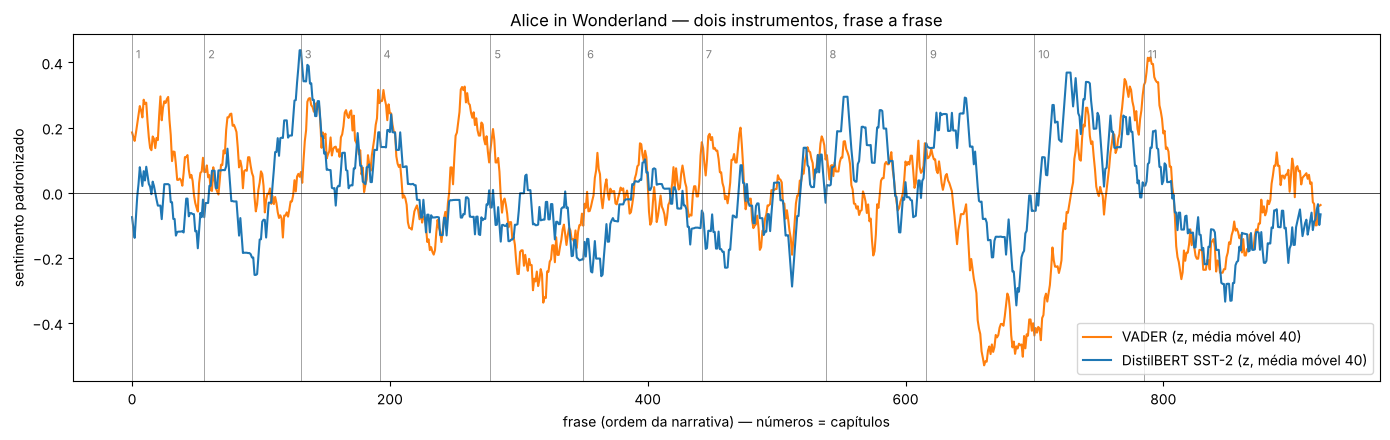

média por capítulo:
 ch       1     2     3     4     5     6     7     8     9     10    11
vader  0.08  0.09  0.13  0.10 -0.05  0.06  0.05  0.05 -0.04  0.04  0.03
sst2  -0.36 -0.18 -0.18 -0.29 -0.32 -0.33 -0.32 -0.25 -0.21 -0.09 -0.37


In [ ]:
gz = fetch_nltk("gutenberg")
raw_alice = gz.read("gutenberg/carroll-alice.txt").decode("utf-8")
chapters = re.split(r"\bCHAPTER [IVXL]+\.", raw_alice)[1:]
al_s, al_ch = [], []
for ci, c in enumerate(chapters):
    t = re.sub(r"\s+", " ", c).strip()
    for s in re.split(r"(?<=[.!?])\s+", t):
        if len(s.split()) >= 3:
            al_s.append(s); al_ch.append(ci + 1)
alice = pd.DataFrame(dict(s=al_s, ch=al_ch))
alice["vader"] = [vader.polarity_scores(s)["compound"] for s in alice.s]
alice["sst2"] = sst2(alice.s.tolist())
print(f"{len(chapters)} capítulos, {len(alice)} frases; concordância de sinal VADER vs SST2: "
      f"{(np.sign(alice.vader) == np.sign(alice.sst2)).mean():.0%} (só frases com VADER ≠ 0: "
      f"{(np.sign(alice.vader[alice.vader != 0]) == np.sign(alice.sst2[alice.vader != 0])).mean():.0%})")
print(f"VADER = 0 (nenhuma palavra do léxico): {(alice.vader == 0).mean():.0%} das frases | SST2 NEGATIVE: {(alice.sst2 < 0).mean():.0%}")
print(f"correlação de Pearson entre os dois: {np.corrcoef(alice.vader, alice.sst2)[0, 1]:.2f}")

W = 40
z = lambda x: (x - x.mean()) / x.std()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(z(alice.vader).rolling(W, center=True, min_periods=10).mean().values, label="VADER (z, média móvel 40)", color="C1")
ax.plot(z(alice.sst2).rolling(W, center=True, min_periods=10).mean().values, label="DistilBERT SST-2 (z, média móvel 40)", color="C0")
starts = alice.groupby("ch").apply(lambda d: d.index[0])
for ch, i0 in starts.items():
    ax.axvline(i0, color="gray", lw=0.5); ax.text(i0 + 3, ax.get_ylim()[1] * 0.85, f"{ch}", fontsize=8, color="gray")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("frase (ordem da narrativa) — números = capítulos"); ax.set_ylabel("sentimento padronizado")
ax.set_title("Alice in Wonderland — dois instrumentos, frase a frase"); ax.legend()
plt.tight_layout(); plt.savefig("figs/7.6_alice_arcs.png", dpi=150); plt.show()
print("média por capítulo:\n", alice.groupby("ch")[["vader", "sst2"]].mean().round(2).T.to_string())

In [ ]:
alice["gap"] = (alice.vader - alice.sst2).abs() * (np.sign(alice.vader) != np.sign(alice.sst2))
for _, r in alice.nlargest(3, "gap").iterrows():
    print(f"[cap. {r.ch}] VADER {r.vader:+.2f} | SST2 {r.sst2:+.3f}\n   {r.s}\n")

[cap. 5] VADER +0.97 | SST2 -0.991
   Alice folded her hands, and began:-- 'You are old, Father William,' the young man said, 'And your hair has become very white; And yet you incessantly stand on your head-- Do you think, at your age, it is right?' 'In my youth,' Father William replied to his son, 'I feared it might injure the brain; But, now that I'm perfectly sure I have none, Why, I do it again and again.' 'You are old,' said the youth, 'as I mentioned before, And have grown most uncommonly fat; Yet you turned a back-somersault in at the door-- Pray, what is the reason of that?' 'In my youth,' said the sage, as he shook his grey locks, 'I kept all my limbs very supple By the use of this ointment--one shilling the box-- Allow me to sell you a couple?' 'You are old,' said the youth, 'and your jaws are too weak For anything tougher than suet; Yet you finished the goose, with the bones and the beak-- Pray how did you manage to do it?' 'In my youth,' said his father, 'I took to the law,

**Dois instrumentos, dois arcos.** O sinal só coincide em **48%** das frases (66% quando o VADER encontra pelo
menos uma palavra; 27% das frases não têm nenhuma) e a correlação é **0.35**. Os **níveis** nem se comparam: o
VADER dá médias ligeiramente positivas a todos os capítulos, o DistilBERT dá médias negativas a todos (64% das
frases de uma comédia infantil saem NEGATIVE) — por isso padronizo e olho só para a **forma**. Mesmo aí, os
vales não coincidem: o VADER desce nos capítulos 5 (a Lagarta) e 9 (a Tartaruga Fingida); o DistilBERT tem os
pontos mais baixos nos capítulos 1 e 11 (o julgamento) e o mais alto no 10 (a Quadrilha das Lagostas).

**As três discordâncias maiores, lidas:**

1. **[cap. 5] o poema *You are old, Father William*** (VADER +0.97, SST2 −0.99). Primeiro, uma falha da minha
   divisão em frases: o poema não tem `.!?` dentro dos versos, por isso entra inteiro como "uma frase" — também
   é medição. O VADER soma palavras soltas (*right, sure, supple, strength, clever*); o DistilBERT lê *old*, *fat*,
   *too weak*, *don't give yourself airs* como uma crítica negativa. O poema é cómico e trocista: **fico mais
   perto do VADER no sinal, mas por acaso** — nenhum dos dois "percebe" a piada.
2. **[cap. 4] *… the great question is, what? The great question certainly was, what?*** (VADER +0.95, SST2 −0.99).
   O VADER conta *great* duas vezes como elogio, mas aqui *great* quer dizer "grande" — o léxico não distingue
   sentidos (o problema do *bank* da Secção 1, outra vez). A Alice está pequena, perdida e com fome: **fico com o
   DistilBERT** (o sinal, não os 0.99 de confiança).
3. **[cap. 4] o cachorro gigante** (VADER +0.94, SST2 −0.99). *delight*, *play*, *game* puxam o VADER para
   cima; a cena é a Alice com medo de ser *trampled under its feet*. Misto, mas o medo domina: **DistilBERT**.

**O que isto diz sobre cada instrumento:** o VADER mede a **densidade de palavras com valência**, cego ao
sentido da palavra e à situação; o DistilBERT mede **"isto soa a uma crítica negativa ou positiva?"** — e prosa
narrativa cheia de perguntas, hesitações e perigo cai para o lado negativo. Nenhum mede diretamente "como o
leitor se sente nesta parte da história"; os dois arcos são duas operacionalizações diferentes, e onde
discordam é onde se aprende o que cada um está a contar.

### 7.6.6 — Só agora: páginas Marvel

Os três instrumentos numa amostra de 40 páginas (sorteadas, seed 3) e, para o DistilBERT, nas 303 (já
calculado na Secção 4). Para o VADER uso a **média do `compound` por frase** (o `compound` de uma página
inteira satura em ±1); a LR é a treinada nos tweets; o DistilBERT lê os primeiros 512 tokens.

In [ ]:
import spacy
nlp = spacy.load("en_core_web_sm")
rng = np.random.default_rng(3)
samp = sorted(rng.choice(len(IDS), 40, replace=False))
def page_vader(t):
    ss = [s for s in re.split(r"(?<=[.!?])\s+", re.sub(r"\s+", " ", t)) if len(s.split()) >= 3]
    return np.mean([vader.polarity_scores(s)["compound"] for s in ss])
mv = pd.DataFrame(dict(página=[name[IDS[i]] for i in samp], comunidade=[comm_of[IDS[i]] for i in samp],
                       VADER_frases=[page_vader(texts[i]) for i in samp],
                       LR_tweets=lr.predict_proba(tfv.transform([texts[i] for i in samp]))[:, 1] * 2 - 1,
                       SST2_512=page_sent[samp]))
print(mv.round(3).sort_values("SST2_512").to_string(index=False))
print("\ncorrelações de Spearman entre os instrumentos (40 páginas):\n", mv[["VADER_frases", "LR_tweets", "SST2_512"]].corr("spearman").round(2).to_string())

                      página  comunidade  VADER_frases  LR_tweets  SST2_512
        Rom the Space Knight           7         0.007     -0.323    -1.000
      Justice (New Universe)           2         0.117      0.242    -0.998
                    Deathlok           7         0.073      0.513    -0.997
             She-Hulk (Lyra)           4         0.085      0.787    -0.997
       Ronin (Marvel Comics)           1         0.037      0.442    -0.996
                Super Rabbit          24         0.286      0.413    -0.995
            Captain Universe           2        -0.000      0.459    -0.994
     Black Rider (character)           1         0.148      0.015    -0.992
        Spitfire (character)           4         0.068      0.271    -0.992
                    Frog-Man           4         0.023      0.739    -0.991
     Captain Marvel (Khn'nr)           2         0.202      0.326    -0.991
  Powerhouse (Marvel Comics)           7         0.009      0.770    -0.989
            

In [ ]:
VIOL = re.compile(r"\b(kill\w*|death|dead|die[ds]?|murder\w*|destroy\w*|villain\w*|battle\w*|war)\b", re.I)
allp = pd.DataFrame(dict(pid=IDS, comunidade=[comm_of[n] for n in IDS], SST2=page_sent,
                         viol_per_1k=[1000 * len(VIOL.findall(t)) / len(t.split()) for t in texts],
                         viol_first512=[1000 * len(VIOL.findall(" ".join(t.split()[:380]))) / 380 for t in texts]))
print(f"Spearman(SST2 da página, palavras de violência por 1000 nos primeiros ~512 tokens) = "
      f"{allp[['SST2', 'viol_first512']].corr('spearman').iloc[0, 1]:.2f}")
by_c = allp[allp.comunidade < 8].groupby("comunidade").agg(páginas=("pid", "size"), frac_NEG=("SST2", lambda x: (x < 0).mean()),
                                                         viol_por_1k=("viol_per_1k", "mean"))
by_c.index = [f"C{k} {LAB[k]}" for k in by_c.index]
print(by_c.round(2).to_string())

Spearman(SST2 da página, palavras de violência por 1000 nos primeiros ~512 tokens) = -0.05
                         páginas  frac_NEG  viol_por_1k
C0 X-Men                      44      0.52         8.94
C1 Vingadores/rua             40      0.60         9.54
C2 Cósmicos                   39      0.72         8.49
C3 Spider-Man                 36      0.67         7.64
C4 Hulk/Heroes for Hire       35      0.51         9.86
C5 Sobrenatural               33      0.58        10.34
C6 Inumanos/FF                32      0.44         9.23
C7 Nova/Cloak&Dagger          18      0.67        11.61


**O que um score de página representa aqui.** Nas 40 páginas os três instrumentos **quase não concordam**
(Spearman −0.14, −0.08, 0.16): o VADER-por-frase fica perto de 0 (prosa enciclopédica neutra), a LR dos tweets
dá quase tudo positivo (vocabulário de tweets), e o DistilBERT é **bimodal** — 28 páginas abaixo de −0.5, 12
acima de +0.6, quase nada no meio. Para o DistilBERT, o número de uma página é: *"os primeiros ~512 tokens desta
biografia da Wikipédia parecem uma crítica de cinema negativa ou positiva, e com que confiança o modelo acha
isso"*. Não é o sentimento da personagem, nem a sua moral, nem o tom da página inteira — e nem sequer é um
detetor de violência: a correlação com palavras de violência nos mesmos ~512 tokens é **−0.05**.

**Porque teria cuidado a comparar comunidades.** A fração NEGATIVE vai de 0.44 (Inumanos/FF) a 0.72
(Cósmicos), o que parece um resultado. Mas (1) com 18–44 páginas por comunidade o erro-padrão de uma proporção
é ≈ 0.07–0.12, por isso a maior parte das diferenças cabe no ruído; (2) as comunidades diferem em coisas que o
modelo lê sem serem "sentimento" — a época das personagens (secções de *Publication history* de séries
canceladas), o comprimento das páginas e o que aparece nos primeiros 512 tokens, o estilo de quem edita cada
canto da Wikipédia; e (3) **não validei o instrumento neste domínio** — os testes da Secção 4 mostraram frases
editoriais neutras a sair com confiança 0.99+ de um lado ou do outro. Antes de comparar comunidades precisaria de
rótulos humanos numa amostra de frases Marvel de cada comunidade.

---
## 📘 Exemplos da página — Secção 5 · Entities turn prose into structured data

**Bloco 1 — BIO tags do spaCy** (`en_core_web_sm`, o pipeline da semana 5). A página: o modelo pequeno
**nunca** vê *Iron Man* como entidade e arquiva *Black Widow* como **ORG**.

In [ ]:
import spacy
nlp = spacy.load("en_core_web_sm")
doc = nlp("Iron Man (Tony Stark) met Black Widow in New York.")

print([(t.text, t.ent_iob_, t.ent_type_) for t in doc])
# [('Iron', 'O', ''), ('Man', 'O', ''), ('(', 'O', ''),
#  ('Tony', 'B', 'PERSON'), ('Stark', 'I', 'PERSON'), (')', 'O', ''),
#  ('met', 'O', ''), ('Black', 'B', 'ORG'), ('Widow', 'I', 'ORG'),
#  ('in', 'O', ''), ('New', 'B', 'GPE'), ('York', 'I', 'GPE'), ('.', 'O', '')]

print([(e.text, e.label_) for e in doc.ents])
# [('Tony Stark', 'PERSON'), ('Black Widow', 'ORG'), ('New York', 'GPE')]

[('Iron', 'O', ''), ('Man', 'O', ''), ('(', 'O', ''), ('Tony', 'B', 'PERSON'), ('Stark', 'I', 'PERSON'), (')', 'O', ''), ('met', 'O', ''), ('Black', 'B', 'ORG'), ('Widow', 'I', 'ORG'), ('in', 'O', ''), ('New', 'B', 'GPE'), ('York', 'I', 'GPE'), ('.', 'O', '')]
[('Tony Stark', 'PERSON'), ('Black Widow', 'ORG'), ('New York', 'GPE')]


**Bloco 2 — uma página inteira → rede de co-menções** (unidade = frase, só PERSON). A página: **445 frases,
635 spans PERSON (179 distintos), 146 nós e 293 arestas**; top 4 = (Mary Jane, Peter) 15, (Peter Parker,
Spider-Man) 14, (Peter, Spider-Man) 9, (Ditko, Lee) 8.

In [ ]:
page = nlp(marvel_pages["Spider-Man"])
pairs = Counter()
for sentence in page.sents:
    people = sorted({e.text for e in sentence.ents if e.label_ == "PERSON"})
    for i in range(len(people)):
        for j in range(i + 1, len(people)):
            pairs[(people[i], people[j])] += 1

G_sm = nx.Graph()
for (a, b), weight in pairs.items():
    G_sm.add_edge(a, b, weight=weight)
print(pairs.most_common(4))
# [(('Mary Jane', 'Peter'), 15), (('Peter Parker', 'Spider-Man'), 14),
#  (('Peter', 'Spider-Man'), 9), (('Ditko', 'Lee'), 8)]
spans_sm = [e.text for e in page.ents if e.label_ == "PERSON"]
print(f"{len(list(page.sents))} frases | {len(spans_sm)} spans PERSON, {len(set(spans_sm))} distintos | rede: {G_sm.number_of_nodes()} nós, {G_sm.number_of_edges()} arestas")

[(('Mary Jane', 'Peter'), 15), (('Peter Parker', 'Spider-Man'), 14), (('Peter', 'Spider-Man'), 9), (('Ditko', 'Lee'), 8)]
445 frases | 635 spans PERSON, 179 distintos | rede: 146 nós, 293 arestas


Igual à página. E as duas leituras que a página pede: *Peter*, *Peter Parker* e *Spider-Man* são **três nós
para uma personagem** (a 2.ª e 3.ª arestas mais fortes ligam um homem a si próprio), e *Ditko–Lee* são os
**criadores**, não personagens da história.

## Exercício 7.7 — BIO tags, entities, and edges, by hand (🧠 learn)

> Go from prose to a network on paper before a tagger does it for thousands of sentences.
>
> 1. Write BIO tags for *Iron Man (Tony Stark) met Black Widow in New York.* Choose sensible entity classes and state one annotation decision another scheme could reasonably make differently.
> 2. Explain the difference between entity extraction and entity resolution using *Iron Man*, *Tony Stark* and *Stark*.
> 3. Take two short sentences containing three named characters and draw the co-occurrence network you would get from sentence-level edges. Then combine the same sentences into one paragraph and draw the paragraph-level network.
> 4. Give one example where a co-occurrence edge would suggest a relationship that the underlying text does not actually support.
> 5. Explain why changing the unit of co-occurrence is a modeling decision rather than a plotting decision.
> 6. 🧠 Rewrite the AI-drafted report above in three honest sentences: what was actually measured, what would have to be checked before believing it, and what the entity count really counts.

O relatório (da página): *"We scored every Marvel page with a DistilBERT sentiment classifier that reports 96%
accuracy, so the measurements are reliable. Villain pages are significantly more negative than hero pages
(−0.42 against +0.11). The NER model found 1,847 distinct characters, and the co-occurrence network built from
them shows clear community structure."*

### 7.7.1 — BIO tags

Classes: **PER** (pessoa/personagem), **LOC** (lugar). Uma etiqueta por token; B = começa um span, I = continua,
O = fora:

| token | Iron | Man | ( | Tony | Stark | ) | met | Black | Widow | in | New | York | . |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BIO | B-PER | I-PER | O | B-PER | I-PER | O | O | B-PER | I-PER | O | B-LOC | I-LOC | O |

Três entidades PER (*Iron Man*, *Tony Stark*, *Black Widow*) e uma LOC (*New York*); com $n$ tipos há
$2n+1$ etiquetas (aqui 5). **Decisões que outro esquema faria diferente:** (a) *New York* como **GPE**
(entidade geopolítica, OntoNotes/spaCy) em vez de LOC; (b) *Iron Man* como **alcunha/codinome** — um esquema
pode dar-lhe uma classe própria (ALIAS/CHARACTER) ou nem a marcar, porque é um título de herói e não um nome
próprio de pessoa; (c) os parênteses podiam ser incluídos num único span *Iron Man (Tony Stark)*. Nenhuma está
"errada"; o que importa é declarar a escolha, porque muda as contagens.

### 7.7.2 — Extração vs resolução

- **Extração (NER):** encontrar os **spans** e o tipo — *"Iron Man"* PER, *"Tony Stark"* PER, *"Stark"* PER.
  Responde a "onde há nomes neste texto?". O resultado são **três menções** com três strings diferentes.
- **Resolução (entity resolution / coreferência):** decidir que as três menções **referem a mesma entidade**
  (a personagem Tony Stark/Iron Man) e juntá-las num só nó. É outra decisão, que pede conhecimento externo
  (Iron Man é o codinome do Tony Stark) e contexto: *Stark* sozinho pode ser o Howard Stark (o pai) ou a
  Stark Industries (uma ORG); e "Iron Man" pode ser o James Rhodes noutra fase. Sem resolução, contar
  entidades = contar **strings**.

### 7.7.3 — Frase vs parágrafo

Frases: **S1** *Wolverine fought Sabretooth in the forest.* **S2** *Later, Storm found Wolverine.*

- **Unidade = frase.** S1 → {Wolverine, Sabretooth}: aresta W–Sb (peso 1). S2 → {Storm, Wolverine}: aresta St–W
  (peso 1). Rede: **Sabretooth — Wolverine — Storm** (um caminho, 2 arestas; Storm e Sabretooth não se ligam).
- **Unidade = parágrafo** (S1 + S2 juntas): {Wolverine, Sabretooth, Storm} co-ocorrem todos → **triângulo**:
  W–Sb, W–St **e St–Sb** (3 arestas). A aresta Storm–Sabretooth aparece só por estarem no mesmo parágrafo.

```
 frase:       Sabretooth ── Wolverine ── Storm          parágrafo:   Sabretooth ── Wolverine
                                                                            ╲          ╱
                                                                              Storm
```

Nº de pares numa unidade com $m$ entidades: $\binom{m}{2}$ — unidades maiores criam arestas quadraticamente.

### 7.7.4 — Uma aresta que o texto não sustenta

*"Unlike Spider-Man, Daredevil has no superhuman strength."* — co-menção na mesma frase → aresta
Spider-Man–Daredevil, mas o texto **compara** as duas personagens; não diz que se conheceram, lutaram ou
trabalharam juntas. Outros casos clássicos no corpus: *"Created by Stan Lee and Jack Kirby"* (aresta Lee–Kirby
entre criadores, que nem são personagens), *"voiced by X and Y"* em secções de média (atores), ou listas
("members include A, B, C, D…", que geram $\binom{m}{2}$ arestas entre personagens que talvez nunca se
encontrem). Co-menção é uma *proxy* de relação, não uma interação.

### 7.7.5 — Mudar a unidade é uma decisão de modelação

A unidade define **o que a aresta significa** antes de qualquer desenho: frase ≈ "mencionados na mesma
afirmação" (relações mais diretas, rede esparsa); parágrafo ≈ "no mesmo episódio/tema" (mais arestas, mais
triângulos, mais ruído); página ≈ "na mesma biografia" (quase uma rede de links). Muda o **número de arestas**
(∝ $\binom{m}{2}$), os **graus**, o **clustering**, as **comunidades** e as conclusões ("X é central"). Um
*plotting decision* (cores, layout) não muda nenhum número; a unidade muda os dados que entram em todas as
medidas da primeira metade do curso. Por isso tem de ser escolhida pela pergunta e reportada (como Fields et
al. fazem com a "dated diary entry").

### 7.7.6 — O relatório reescrito, em três frases honestas

**As três falhas:** (1) **uma accuracy de outro domínio apresentada como validação** — os 96% são do SST-2
(críticas de cinema), não de páginas da Wikipédia escritas para serem neutras; (2) **um score sem dizer o que
mede** — −0.42 vs +0.11 de quê (sinal × confiança dos primeiros 512 tokens?), com que teste é "significant", e
pode ser só vocabulário de enredo (*death, killed*) e não sentimento; (3) **uma contagem de entidades que saltou
a resolução** — 1,847 são strings PERSON distintas (Peter / Peter Parker / Spider-Man contam 3; criadores e
atores também contam; super-heróis classificados como ORG ficam de fora), não personagens.

> We applied an off-the-shelf DistilBERT classifier fine-tuned on movie reviews (where it reports 96% accuracy)
> to the first 512 tokens of every Marvel page and averaged its signed confidence: villain pages averaged −0.42
> and hero pages +0.11, a difference we have not tested statistically and that may reflect plot vocabulary
> such as *death* and *killed* rather than any sentiment in this deliberately neutral prose.
> Before believing it we would need sentiment labels for a sample of Wikipedia sentences to check the model's
> accuracy in this domain, stress tests on plot language, and a comparison with a lexicon on the same pages.
> The NER model returned 1,847 distinct PERSON strings — aliases of the same character, real-world creators and
> actors included, superhero names it tagged as ORG left out — so it counts name strings, not characters, and
> the "community structure" of a network built from them must be compared with a null model and checked after
> alias resolution.

## Exercício 7.8 — Tag, check, resolve, connect (🔬 tool + 🚀 builder)

> Now use a pretrained NER model as a measurement instrument and carry its output all the way into a network.
>
> 1. Hand-label a manageable random sample of Marvel text before you run the model. Keep those labels as a small reference set.
> 2. Run a pretrained NER model and compare its spans with your reference labels. Report at least span-level precision and recall, then inspect the mistakes and describe recurring errors.
> 3. Make a short alias-resolution table for names you can justify merging. Keep the original model output so the resolution decisions remain inspectable.
> 4. Build an entity co-occurrence network using at least two units, for example sentence and paragraph. Compare node counts, edge counts, degree distributions, communities and several concrete edges.
> 5. Find one edge that looks convincing and one that becomes questionable when you read the underlying text. Explain what created each one.
> 6. Combine methods from the course in one small analysis. Ask a question where the entity network becomes more useful when paired with topic modeling or sentiment, and state what each method contributes to the answer.

### 7.8.1 — Amostra rotulada à mão (antes de correr o modelo)

**Amostra:** frases de parágrafos com ≥ 25 palavras (tira títulos e listas), cortadas pela regex de frases, com
10–35 palavras → 24 316 frases; sorteio 25 com `seed=2026`. **Esquema de rótulos (meu):** **PER** = qualquer
pessoa ou personagem, incluindo codinomes (*Black Panther*, *Scarlet Spider*, *The Silencer*) e entidades
tratadas como personagens (*Phoenix Force*); **ORG** = equipas, organizações, empresas (*X-Men*, *Web Warriors*,
*Marvel Comics*); **LOC** = lugares, incluindo GPE e lugares ficcionais (*Houston*, *Earth-616*, *Sanctum
Santorum*); **MISC** = obras, eventos, artefactos, nacionalidades (*Avengers Assemble*, *Kree-Skrull War*,
*Fistigons*, *British*). Datas e números não contam. Escrevi as etiquetas abaixo lendo cada frase **sem** ver o
output do spaCy.

In [ ]:
pool = []
for pid in IDS:
    for para in marvel_pages[pid].split("\n"):
        if len(para.split()) < 25:
            continue
        for s in re.split(r"(?<=[.!?])\s+", para.strip()):
            if 10 <= len(s.split()) <= 35:
                pool.append((pid, s))
rng = np.random.default_rng(2026)
ner_sample = [pool[i] for i in sorted(rng.choice(len(pool), 25, replace=False))]
print(f"{len(pool):,} frases elegíveis; amostra de {len(ner_sample)}")

GOLD = [  # (span, tipo) por frase, na ordem da amostra
    [("Anya", "PER"), ("Arachne", "PER"), ("Rachel", "PER")],
    [("Merlin", "PER"), ("Sanctum Santorum", "LOC")],
    [("Black Panther", "PER")],
    [("Captain Midlands", "PER"), ("British", "MISC"), ("Super-Soldier", "MISC"), ("Sid Ridley", "PER")],
    [("Gert", "PER"), ("Chase", "PER")],
    [("Fistigons", "MISC")],
    [("The Silencer", "PER"), ("Peter", "PER")],
    [("Rangers", "ORG"), ("Kaine", "PER"), ("Scarlet Spider", "PER"), ("Houston", "LOC")],
    [("Guardsmen", "ORG"), ("Avengers Assemble", "MISC"), ("Roger Craig Smith", "PER"), ("Civil War, Part 3: The Drums of War", "MISC"),
     ("David Kaye", "PER"), ("Prison Break", "MISC"), ("Trevor Devall", "PER"), ("Fred Tatasciore", "PER"), ("Vibranium Curtain", "MISC")],
    [("Hank Pym", "PER"), ("Kree-Skrull War", "MISC"), ("Ant-Man", "PER")],
    [("Hank Pym", "PER"), ("Marvel's Avengers", "MISC"), ("Danny Jacobs", "PER")],
    [("Jean Grey", "PER")],
    [("England", "LOC"), ("Earth-616", "LOC"), ("Outlaw", "PER")],
    [("Puppet Master", "PER"), ("Paladin", "PER"), ("Misty", "PER")],
    [("Phoenix Force", "PER"), ("American", "MISC"), ("Marvel Comics", "ORG")],
    [],
    [("Sabra", "PER"), ("X-Men", "ORG"), ("Charles Xavier", "PER")],
    [("Ruby Scarab", "MISC"), ("Elementals", "ORG")],
    [("Doctor Doom", "PER"), ("Desturi", "ORG"), ("Wakandan", "MISC"), ("Doomwar", "MISC")],
    [("Spider-UK", "PER"), ("Inheritor Cloning Engine", "MISC"), ("Master Weaver", "PER"), ("Web Warriors", "ORG")],
    [("Nick Fury", "PER"), ("Jared", "PER")],
    [("Heralds", "ORG"), ("Starbrand", "PER")],
    [("Sphinx", "PER"), ("Speedball", "PER")],
    [("War Machine", "PER"), ("U.S.", "LOC")],
    [],
]
assert len(GOLD) == len(ner_sample)
for k, ((pid, s), g) in enumerate(zip(ner_sample, GOLD)):
    for span, _ in g:
        assert span in s, (k, span)
    print(f"{k:2d} [{name[pid][:22]:22s}] {s}\n     gold: " + "; ".join(f"{a}/{b}" for a, b in g))
print("\nspans de referência:", sum(map(len, GOLD)), dict(Counter(t for g in GOLD for _, t in g)))

24,316 frases elegíveis; amostra de 25
 0 [Anya Corazon          ] Soon after, Anya quits her job, and is confronted by Arachne who is enraged and demands to know Rachel's whereabouts.
     gold: Anya/PER; Arachne/PER; Rachel/PER
 1 [Black Cat (Marvel Comi] Everything at work in this book was already great, but adding in a crazed Merlin and a trip to the Sanctum Santorum make it even better.
     gold: Merlin/PER; Sanctum Santorum/LOC
 2 [Black Panther (charact] The herb gives him superhuman strength and speed, and he inherits the title of Black Panther.
     gold: Black Panther/PER
 3 [Captain Midlands      ] Captain Midlands has no superhuman powers, although as a result of the 1940s British Super-Soldier program Sid Ridley was transformed into a "perfect" specimen of human development and conditioning.
     gold: Captain Midlands/PER; British/MISC; Super-Soldier/MISC; Sid Ridley/PER
 4 [Chase Stein           ] Gert's relationship with Chase softened her somewhat, though she did not 

### 7.8.2 — O spaCy contra a referência

Mapeio as classes do OntoNotes para as minhas: PERSON → PER; ORG → ORG; GPE/LOC/FAC → LOC; NORP, WORK_OF_ART,
EVENT, PRODUCT, LAW → MISC; DATE/CARDINAL/ORDINAL/TIME/… ignoradas. **Span-level** = um acerto só se o
texto do span **e** o tipo forem exatamente iguais (a medida da J&M §18.6: a entidade é a unidade, não a palavra).
Reporto também a versão "só fronteiras" (texto igual, tipo qualquer).

In [ ]:
MAP = {"PERSON": "PER", "ORG": "ORG", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC",
       "NORP": "MISC", "WORK_OF_ART": "MISC", "EVENT": "MISC", "PRODUCT": "MISC", "LAW": "MISC", "LANGUAGE": "MISC"}
def spans_gold(k):
    s = ner_sample[k][1]; out = []
    for span, typ in GOLD[k]:
        st = s.find(span); out.append((st, st + len(span), typ))
    return set(out)
pred_spans = []
for k, (pid, s) in enumerate(ner_sample):
    d = nlp(s)
    pred_spans.append({(e.start_char, e.end_char, MAP[e.label_]) for e in d.ents if e.label_ in MAP})
def prf(match):
    tp = fp = fn = 0
    for k in range(len(ner_sample)):
        g, p = spans_gold(k), pred_spans[k]
        if not match: g, p = {(a, b) for a, b, _ in g}, {(a, b) for a, b, _ in p}
        tp += len(g & p); fp += len(p - g); fn += len(g - p)
    P, R = tp / (tp + fp), tp / (tp + fn)
    return tp, fp, fn, P, R, 2 * P * R / (P + R)
for lbl, m in [("span + tipo", True), ("só fronteiras", False)]:
    tp, fp, fn, P, R, F = prf(m)
    print(f"{lbl:14s}: TP {tp:2d} FP {fp:2d} FN {fn:2d} | precision {P:.2f} | recall {R:.2f} | F1 {F:.2f}")
rows = []
for typ in ["PER", "ORG", "LOC", "MISC"]:
    tp = sum(len({x for x in spans_gold(k) if x[2] == typ} & pred_spans[k]) for k in range(len(ner_sample)))
    ng = sum(sum(1 for x in spans_gold(k) if x[2] == typ) for k in range(len(ner_sample)))
    npred = sum(sum(1 for x in pred_spans[k] if x[2] == typ) for k in range(len(ner_sample)))
    rows.append(dict(tipo=typ, referência=ng, previstos=npred, certos=tp, precision=round(tp / max(npred, 1), 2), recall=round(tp / max(ng, 1), 2)))
print(pd.DataFrame(rows).to_string(index=False))

span + tipo   : TP 31 FP 32 FN 34 | precision 0.49 | recall 0.48 | F1 0.48
só fronteiras : TP 50 FP 13 FN 15 | precision 0.79 | recall 0.77 | F1 0.78
tipo  referência  previstos  certos  precision  recall
 PER          38         26      21       0.81    0.55
 ORG           8         19       4       0.21    0.50
 LOC           5          9       3       0.33    0.60
MISC          14          9       3       0.33    0.21


In [ ]:
print("ERROS, frase a frase (✗ falhou | + a mais):")
for k, (pid, s) in enumerate(ner_sample):
    g, p = spans_gold(k), pred_spans[k]
    raw = [(e.text, e.label_) for e in nlp(s).ents]
    miss = [f"{s[a:b]}/{t}" for a, b, t in sorted(g - p)]; extra = [f"{s[a:b]}/{t}" for a, b, t in sorted(p - g)]
    if miss or extra:
        print(f"{k:2d} ✗ {miss}  + {extra}   | spaCy: {raw}")

ERROS, frase a frase (✗ falhou | + a mais):
 1 ✗ ['Merlin/PER', 'Sanctum Santorum/LOC']  + ['Merlin/MISC', 'Sanctum Santorum/ORG']   | spaCy: [('Merlin', 'NORP'), ('Sanctum Santorum', 'ORG')]
 2 ✗ ['Black Panther/PER']  + ['Black Panther/LOC']   | spaCy: [('Black Panther', 'FAC')]
 3 ✗ ['Captain Midlands/PER', 'British/MISC', 'Super-Soldier/MISC']  + ['Midlands/PER', 'British Super-Soldier/ORG']   | spaCy: [('Midlands', 'PERSON'), ('1940s', 'DATE'), ('British Super-Soldier', 'ORG'), ('Sid Ridley', 'PERSON')]
 4 ✗ ['Chase/PER']  + ['Chase/ORG']   | spaCy: [('Gert', 'PERSON'), ('Chase', 'ORG')]
 5 ✗ ['Fistigons/MISC']  + ['Fistigons/ORG']   | spaCy: [('Fistigons', 'ORG')]
 6 ✗ ['The Silencer/PER']  + ['Silencer/PER']   | spaCy: [('Silencer', 'PERSON'), ('Peter', 'PERSON')]
 7 ✗ ['Scarlet Spider/PER']  + ['Scarlet Spider/ORG']   | spaCy: [('Rangers', 'ORG'), ('Kaine', 'PERSON'), ('Scarlet Spider', 'ORG'), ('Houston', 'GPE')]
 8 ✗ ['Guardsmen/ORG', 'Avengers Assemble/MISC', 'Civil War, Par

**Erros recorrentes** (lendo a lista acima):

1. **Codinomes de heróis como ORG/LOC/NORP** — *Scarlet Spider* ORG, *Chase* ORG, *Outlaw* ORG, *Puppet Master*
   ORG, *Master Weaver* ORG, *Paladin* NORP, *Black Panther* FAC (!). É o problema que a página mostra com a Black
   Widow: nomes de super-heróis são raros no texto de notícias com que o modelo foi treinado e parecem nomes de
   empresas/grupos. Por isso a **precision de ORG é 0.21** (19 ORG previstos, 4 certos) e o **recall de PER 0.55**.
2. **Fronteiras** — *Midlands* em vez de *Captain Midlands*, *Silencer* em vez de *The Silencer*, *the X-Men* /
   *the Kree-Skrull War* com o artigo, *Doom* em vez de *Doctor Doom*, *Civil War* + *The Drums of War* partido em
   dois. Por isso a diferença enorme entre "span + tipo" (F1 0.48) e "só fronteiras" (0.78): muitos erros são de
   **tipo**, alguns de **fronteira** — e na avaliação por entidade uma fronteira errada conta como FP + FN.
3. **Lugares e objetos ficcionais** — *Earth-616* NORP, *Sanctum Santorum* ORG, *B.C.* como GPE, *Fistigons* ORG.
4. **Nomes reais e de média funcionam bem** — atores (*Roger Craig Smith*, *Danny Jacobs*), *Hank Pym*, *Charles
   Xavier*, *Nick Fury* — o domínio do treino (OntoNotes: notícias) está presente.

Leitura para a rede: com um recall de PER de ~0.55, cerca de metade das menções de personagens **não entram**
na rede, e as que entram como ORG desaparecem se só usarmos PERSON — daí a decisão (declarada) de também resolver
spans ORG cujo texto é o nome exato de uma personagem.

### 7.8.3 — Tabela de aliases (resolução) e o corpus inteiro

Corro o spaCy nas 303 páginas (com o `senter` em vez do parser, para ser rápido) e guardo **o output original**
(cada span com página, parágrafo, frase, texto e tipo). A resolução é uma camada **por cima**, numa tabela que
se pode ler e contestar:

1. **Aliases que consigo justificar** (identidade secreta ↔ codinome, nomes curtos frequentes) → um nome canónico;
2. um span PERSON **ou ORG** cujo texto é exatamente o nome de uma das 303 personagens (sem o parêntese) é
   resolvido para essa personagem — decisão declarada: o spaCy põe muitos codinomes em ORG (*Black Widow*);
3. o que não se resolve fica como está (nó "string").

In [ ]:
import time
t0 = time.time()
nlp_fast = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"]); nlp_fast.enable_pipe("senter")
ner_rows = []
para_texts = [(pid, pi, para) for pid in IDS for pi, para in enumerate(marvel_pages[pid].split("\n")) if para.strip()]
for (pid, pi, para), d in zip(para_texts, nlp_fast.pipe((p for _, _, p in para_texts), batch_size=64)):
    for si, sent in enumerate(d.sents):
        for e in sent.ents:
            if e.label_ in ("PERSON", "ORG"):
                ner_rows.append((pid, pi, si, e.text, e.label_))
ner = pd.DataFrame(ner_rows, columns=["page", "para", "sent", "text", "label"])
ner.to_csv("data/ner_spacy_person_org.csv", index=False)
print(f"{time.time() - t0:.0f} s | {len(para_texts):,} parágrafos | spans PERSON: {(ner.label == 'PERSON').sum():,} "
      f"({ner[ner.label == 'PERSON'].text.nunique():,} strings distintas) | ORG: {(ner.label == 'ORG').sum():,}")
print("PERSON mais frequentes:", ", ".join(f"{t} {c}" for t, c in ner[ner.label == "PERSON"].text.value_counts().head(15).items()))

73 s | 15,793 parágrafos | spans PERSON: 33,641 (7,862 strings distintas) | ORG: 24,934
PERSON mais frequentes: Spider-Man 503, Peter 344, Jean 301, Betsy 284, Wanda 275, Ghost Rider 213, Jean Grey 212, Shang-Chi 204, Wolverine 197, Marvel 171, Peter Parker 171, Moon Knight 165, Emma Frost 161, Doom 157, Jubilee 151


In [ ]:
GENERIC = {"character", "characters", "Marvel Comics", "comics", "Marvel", "Inhuman"}   # parênteses que só desambiguam
canon_of_title = {}
for n in IDS:                                           # 1.º os nomes sem parênteses ("Spider-Man", "Hulk")
    if "(" not in name[n]: canon_of_title[name[n]] = name[n]
for n in IDS:                                           # depois "X (character)" etc., sem nunca sobrepor
    m_ = re.match(r"^(.*?)\s*\((.*)\)$", name[n])
    if m_ and m_.group(2) in GENERIC and m_.group(1) not in canon_of_title:
        canon_of_title[m_.group(1)] = name[n]
VARIANT = {"Marvel Mangaverse", "Ultimate Marvel character", "X-Men film series", "Guardians of the Galaxy", "android", "Lyra"}
for n in IDS:                                           # 3.º parênteses com identidade/equipa: "Black Widow (Natasha Romanova)" ← "Black Widow"
    m_ = re.match(r"^(.*?)\s*\((.*)\)$", name[n])
    if m_ and m_.group(2) not in VARIANT and m_.group(1) not in canon_of_title:
        canon_of_title[m_.group(1)] = name[n]
# versões alternativas ("Spider-Man (Marvel Mangaverse)", "Jean Grey (X-Men film series)", "Iron Man (Ultimate Marvel character)")
# só são resolvidas pelo nome completo -- uma menção de "Spider-Man" é o Spider-Man principal, não o do Mangaverse
for n in IDS:
    canon_of_title.setdefault(name[n], name[n])
ALIAS = {  # alias -> personagem (nome do ficheiro de nós); só casos que consigo justificar pelo texto/cânone
    "Peter Parker": "Spider-Man", "Peter": "Spider-Man", "Spidey": "Spider-Man",
    "Tony Stark": "Iron Man", "Stark": "Iron Man",
    "Logan": "Wolverine (character)", "Wolverine": "Wolverine (character)", "James Howlett": "Wolverine (character)",
    "Bruce Banner": "Hulk", "Banner": "Hulk",
    "Steve Rogers": "Captain America", "Natasha Romanoff": "Black Widow (Natasha Romanova)", "Natasha": "Black Widow (Natasha Romanova)",
    "Jean": "Jean Grey", "Ororo Munroe": "Storm (Marvel Comics)", "Storm": "Storm (Marvel Comics)",
    "Scott Summers": "Cyclops (Marvel Comics)", "Cyclops": "Cyclops (Marvel Comics)",
    "Wanda Maximoff": "Scarlet Witch", "Wanda": "Scarlet Witch",
    "Stephen Strange": "Doctor Strange", "Strange": "Doctor Strange",
    "Eddie Brock": "Eddie Brock", "Brock": "Eddie Brock", "Venom": "Venom (character)",
    "Wade Wilson": "Deadpool", "Matt Murdock": "Daredevil", "T'Challa": "Black Panther (character)",
    "Carol Danvers": "Captain Marvel (Carol Danvers)", "Jessica Drew": "Spider-Woman (Jessica Drew)",
    "Hank Pym": "Hank Pym", "Pym": "Hank Pym", "Emma": "Emma Frost", "Johnny Blaze": "Ghost Rider (Johnny Blaze)",
}
ALIAS = {a: c for a, c in ALIAS.items() if c in by_name}          # só aliases para personagens que existem no corpus
def resolve(text, label):
    t = re.sub(r"'s$", "", text.strip())
    if t in ALIAS: return ALIAS[t], "alias"
    if t in canon_of_title: return canon_of_title[t], "nome exato"
    return (t if label == "PERSON" else None), "não resolvido"
res_ = ner.apply(lambda r: resolve(r.text, r.label), axis=1)
ner["node"], ner["how"] = [a for a, _ in res_], [b for _, b in res_]
ner_used = ner.dropna(subset=["node"])
print(f"alias table: {len(ALIAS)} entradas | spans usados: {len(ner_used):,} (ORG só quando é nome exato de personagem)")
print(ner_used.how.value_counts().to_string())
print("exemplos de merges:", ner_used[ner_used.how == "alias"].groupby("node").text.agg(lambda x: sorted(set(x))).head(10).to_dict())
print(f"strings PERSON distintas: {ner[ner.label == 'PERSON'].text.nunique():,} → nós depois da resolução: {ner_used.node.nunique():,} "
      f"(dos quais personagens do corpus: {ner_used.node.isin(set(name.values())).sum() and ner_used[ner_used.node.isin(set(name.values()))].node.nunique()})")

alias table: 29 entradas | spans usados: 38,789 (ORG só quando é nome exato de personagem)
how
não resolvido    26396
nome exato        9180
alias             3213
exemplos de merges: {'Black Panther (character)': ["T'Challa"], 'Black Widow (Natasha Romanova)': ['Natasha', 'Natasha Romanoff', "Natasha Romanoff's"], 'Cyclops (Marvel Comics)': ['Cyclops', 'Scott Summers'], 'Deadpool': ['Wade Wilson', "Wade Wilson's"], 'Doctor Strange': ['Stephen Strange', 'Strange'], 'Eddie Brock': ['Brock', "Brock's", 'Eddie Brock', "Eddie Brock's"], 'Emma Frost': ['Emma'], 'Ghost Rider (Johnny Blaze)': ['Johnny Blaze', "Johnny Blaze's"], 'Hank Pym': ['Hank Pym', "Hank Pym's", 'Pym'], 'Hulk': ['Banner', 'Bruce Banner', "Bruce Banner's"]}
strings PERSON distintas: 7,862 → nós depois da resolução: 7,606 (dos quais personagens do corpus: 251)


### 7.8.4 — Duas unidades: frase e parágrafo

Rede **resolvida e restrita às 303 personagens** (para se poder comparar com a rede de links), arestas com
peso = nº de unidades em que co-ocorrem. Também mostro a rede "crua" (strings PERSON sem resolução).

                              rede  nós  arestas  grau_médio  grau_máx  clustering  comunidades     Q arestas_que_são_links
    frase (resolvida, personagens)  189      476         5.0        61       0.298           16 0.546                   70%
parágrafo (resolvida, personagens)  214      826         7.7        84       0.367           13 0.492                   61%
      frase (crua, strings PERSON) 6144    14629         4.8       280       0.431          378 0.722                     —


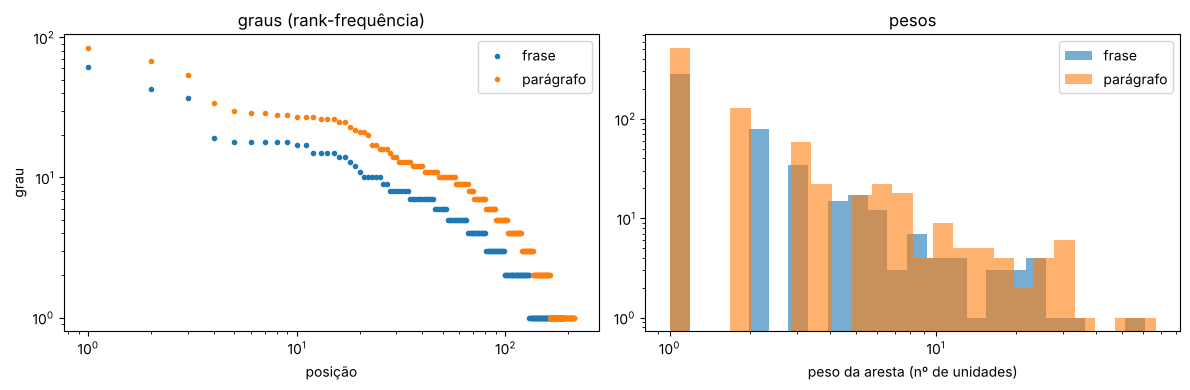

arestas que só existem ao nível do parágrafo: 350 de 826
arestas mais fortes (frase): Cyclops (Marvel Comics)–Jean Grey 60, Spider-Man–Eddie Brock 35, Black Panther (character)–Storm (Marvel Comics) 29, Emma Frost–Jean Grey 23, Spider-Man–Morbius 23, Spider-Man–Spider-Woman 22, Spider-Woman–Spider-Woman (Jessica Drew) 22, Cyclops (Marvel Comics)–Wolverine (character) 21
arestas mais fortes que só existem no parágrafo: Nomad (Marvel Comics)–Bucky (Marvel Comics) 6, She-Hulk–Spider-Man 5, Jessica Jones–Spider-Woman (Jessica Drew) 5, Hulk–Adam Warlock 4, Hawkeye (comics)–Spider-Man 4, Misty Knight–Jessica Jones 4, Moondragon–Genis-Vell 3, Spider-Man–Jean Grey 3
grau de Spider-Man: frase 61 | parágrafo 84 | links 106
grau de Wolverine (character): frase 37 | parágrafo 54 | links 63
grau de Hulk: frase 43 | parágrafo 68 | links 65


In [ ]:
chars = set(name.values())
def cooc(df, unit, keep=None):
    Gc = nx.Graph()
    for _, grp in df.groupby(unit):
        ns_ = sorted(set(grp.node) if keep is None else set(grp.node) & keep)
        for a_ in range(len(ns_)):
            for b_ in range(a_ + 1, len(ns_)):
                u, v = ns_[a_], ns_[b_]
                Gc.add_edge(u, v, weight=Gc[u][v]["weight"] + 1 if Gc.has_edge(u, v) else 1)
    return Gc
U_SENT, U_PARA = ["page", "para", "sent"], ["page", "para"]
nets = {"frase (resolvida, personagens)": cooc(ner_used, U_SENT, chars), "parágrafo (resolvida, personagens)": cooc(ner_used, U_PARA, chars),
        "frase (crua, strings PERSON)": cooc(ner[ner.label == "PERSON"].assign(node=lambda d: d.text), U_SENT)}
G_links = nx.Graph(); G_links.add_edges_from((name[a], name[b]) for a, b in edges[["source", "target"]].values if a != b)
rows = []
for lbl, Gc in nets.items():
    d_ = np.array([d for _, d in Gc.degree()])
    comms = nxc.louvain_communities(Gc, weight="weight", seed=0) if Gc.number_of_edges() else []
    in_links = sum(G_links.has_edge(u, v) for u, v in Gc.edges()) if "personagens" in lbl else np.nan
    rows.append(dict(rede=lbl, nós=Gc.number_of_nodes(), arestas=Gc.number_of_edges(), grau_médio=round(d_.mean(), 1), grau_máx=d_.max(),
                     clustering=round(nx.average_clustering(Gc), 3), comunidades=len(comms),
                     Q=round(nxc.modularity(Gc, comms, weight="weight"), 3) if comms else np.nan,
                     arestas_que_são_links=(f"{in_links / Gc.number_of_edges():.0%}" if in_links == in_links else "—")))
print(pd.DataFrame(rows).to_string(index=False))

Gs, Gp = nets["frase (resolvida, personagens)"], nets["parágrafo (resolvida, personagens)"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lbl, Gc in [("frase", Gs), ("parágrafo", Gp)]:
    d_ = np.array(sorted([d for _, d in Gc.degree()], reverse=True))
    ax[0].loglog(np.arange(1, len(d_) + 1), d_, ".", label=lbl)
    w_ = np.array([d["weight"] for *_, d in Gc.edges(data=True)])
    ax[1].hist(w_, bins=np.logspace(0, np.log10(w_.max() + 1), 25), alpha=0.6, label=lbl)
ax[0].set_xlabel("posição"); ax[0].set_ylabel("grau"); ax[0].set_title("graus (rank-frequência)"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("peso da aresta (nº de unidades)"); ax[1].set_title("pesos"); ax[1].legend()
plt.tight_layout(); plt.savefig("figs/7.8_sentence_vs_paragraph.png", dpi=150); plt.show()

only_p = [(u, v, d["weight"]) for u, v, d in Gp.edges(data=True) if not Gs.has_edge(u, v)]
print(f"arestas que só existem ao nível do parágrafo: {len(only_p):,} de {Gp.number_of_edges():,}")
print("arestas mais fortes (frase):", ", ".join(f"{u}–{v} {d['weight']}" for u, v, d in sorted(Gs.edges(data=True), key=lambda x: -x[2]["weight"])[:8]))
print("arestas mais fortes que só existem no parágrafo:", ", ".join(f"{u}–{v} {w}" for u, v, w in sorted(only_p, key=lambda x: -x[2])[:8]))
for nm in ["Spider-Man", "Wolverine (character)", "Hulk"]:
    if nm in Gs:
        print(f"grau de {nm}: frase {Gs.degree(nm)} | parágrafo {Gp.degree(nm)} | links {G_links.degree(nm) if nm in G_links else 0}")

**Comparação.** (Rede resolvida = só nós que são uma das 303 personagens.)

- **Nós e arestas:** frase → **189 nós, 476 arestas**; parágrafo → **214 nós, 826 arestas** (+74%). 350 das 826
  arestas do parágrafo não existem ao nível da frase. O grau médio passa de 5.0 para 7.7, o clustering de 0.30
  para 0.37 (unidades maiores fecham triângulos), a modularidade desce (0.55 → 0.49) e o Louvain encontra menos
  comunidades (16 → 13): o parágrafo "cola" grupos.
- **Graus:** o Spider-Man passa de 61 para 84 vizinhos, o Hulk de 43 para 68 — na rede de links têm 106 e 65.
- **Concordância com a rede de links:** 70% das arestas de frase também são links da Wikipédia; no parágrafo,
  61%. As arestas extra do parágrafo são, em média, menos "reais".
- **A rede crua** (strings PERSON, sem resolução): **6,144 nós, 14,629 arestas** — dominada por variantes do mesmo
  nome, criadores e atores; 378 "comunidades". É a rede do relatório do 7.7.6.
- **Arestas concretas:** as mais fortes ao nível da frase são relações reais (Cyclops–Jean Grey 60, casados;
  Spider-Man–Eddie Brock 35, o Venom; Black Panther–Storm 29, casados; Emma Frost–Jean Grey 23, rivais).
  Mas também há **duplicados que a resolução não apanhou**: *Spider-Woman – Spider-Woman (Jessica Drew)* (22) são
  duas páginas para a mesma heroína (a página genérica do título e a da Jessica Drew), por isso a mesma menção
  aparece duas vezes. As que só existem no parágrafo (Nomad–Bucky 6, She-Hulk–Spider-Man 5, Hawkeye–Spider-Man
  4) são mais fracas e mais suspeitas — ver a seguir.

### 7.8.5 — Uma aresta convincente e uma questionável (ler o texto)

In [ ]:
def evidence(u, v, unit=U_SENT, k=3):
    a = ner_used[ner_used.node == u].set_index(unit).index; b = ner_used[ner_used.node == v].set_index(unit).index
    common = sorted(set(a) & set(b))[:k]; out = []
    for key_ in common:
        pid, pi = key_[0], key_[1]
        para = marvel_pages[pid].split("\n")[pi]
        if len(key_) == 3:
            sents = [s.text for s in nlp_fast(para).sents]; txt = sents[key_[2]] if key_[2] < len(sents) else para
        else:
            txt = para[:400]
        out.append(f"   [{name[pid]}] {txt.strip()[:300]}")
    return out
G_raw = nets["frase (crua, strings PERSON)"]
for u, v in [("Cyclops (Marvel Comics)", "Jean Grey"), ("Eddie Brock", "Spider-Man")]:
    print(f"■ {u} – {v}: frase {Gs[u][v]['weight'] if Gs.has_edge(u, v) else 0} | parágrafo {Gp[u][v]['weight'] if Gp.has_edge(u, v) else 0} | link na Wikipédia: {G_links.has_edge(u, v)}")
    print("\n".join(evidence(u, v)))
print(f"\n■ (rede crua) Lee – Kirby: {G_raw['Lee']['Kirby']['weight'] if G_raw.has_edge('Lee', 'Kirby') else 0} frases | "
      f"Stan Lee – Jack Kirby: {G_raw['Jack Kirby']['Stan Lee']['weight'] if G_raw.has_edge('Jack Kirby', 'Stan Lee') else 0} frases | "
      f"Ditko – Lee: {G_raw['Ditko']['Lee']['weight'] if G_raw.has_edge('Ditko', 'Lee') else 0}")
# a aresta questionável: a mais forte que existe só ao nível do parágrafo e não é link
q = [(u, v, w) for u, v, w in sorted(only_p, key=lambda x: -x[2]) if not G_links.has_edge(u, v)][0]
print(f"\n■ {q[0]} – {q[1]}: só no parágrafo, peso {q[2]}, sem link")
print("\n".join(evidence(q[0], q[1], U_PARA, 2)))

■ Cyclops (Marvel Comics) – Jean Grey: frase 60 | parágrafo 66 | link na Wikipédia: True
   [Betsy Braddock] After regaining her full personality from Kwannon, Betsy offered a belated apology to Jean Grey, admitting that the flirtation was due to the presence of Kwannon's lingering personality traits in her mind, but that she did in fact find Cyclops attractive.
   [Cable (character)] Nathan Summers is the son of the X-Men member Cyclops (Scott Summers) and his first wife Madelyne Pryor (Jean Grey's clone), as well as the "half"-brother of Rachel Summers from the "Days of Future Past" timeline and Nate Grey from the timeline of the "Age of Apocalypse" storyline, the genetic templ
   [Cable (character)] Since making his home in the modern era, he has worked alongside the X-Men (including Cyclops and Jean Grey) and reformed the New Mutants group into the original X-Force.
■ Eddie Brock – Spider-Man: frase 35 | parágrafo 49 | link na Wikipédia: True
   [She-Venom (Patricia Robertson)] Sti

**Convincente — Cyclops – Jean Grey** (60 frases, link na Wikipédia): as frases dizem explicitamente a relação
— *"Nathan Summers is the son of … Cyclops (Scott Summers) and his first wife Madelyne Pryor (Jean Grey's
clone)"*, *"worked alongside the X-Men (including Cyclops and Jean Grey)"*. A co-menção aqui **é** a relação
(marido e mulher, equipa). O que a criou: muitas páginas diferentes (Cable, Betsy Braddock, Phoenix…) a contar a
mesma história. (Spider-Man – Eddie Brock é igualmente convincente: as frases são sobre o Eddie como Venom, o
inimigo do Spider-Man.)

**Questionável — Hawkeye – Spider-Man** (só ao nível do parágrafo, peso 4, sem link): os parágrafos que a criam
são, p. ex., um parágrafo da página da **Black Widow** que fala do Hawkeye como aliado dela nos anos 60 e menciona
o Spider-Man noutra frase, e um parágrafo de **receção crítica** da Scarlet Witch ("one of the most important
characters…") que cita várias personagens. Ninguém interage com ninguém: a aresta foi criada pela **unidade**
(parágrafo) e por parágrafos de lista/crítica. Outro exemplo de aresta sem relação, na rede crua: **Stan Lee –
Jack Kirby** (47 frases) e **Ditko – Lee** (11) — os criadores, que nem são personagens.

### 7.8.6 — Juntar métodos: a rede de co-menções + sentimento

**Pergunta:** *nas frases em que duas personagens são mencionadas juntas, o tom distingue aliados de
inimigos?* A rede dá **quem** aparece com quem (e quanto); o sentimento (VADER, transparente, frase a frase)
dá **o tom das frases que criaram a aresta**. Testo em pares que conheço (aliado vs inimigo) e depois olho para
as arestas mais fortes ordenadas pelo tom.

In [ ]:
sent_text = {}
sent_index = ner_used.groupby(U_SENT).node.apply(lambda x: sorted(set(x) & chars))
need = {k_ for k_, ns_ in sent_index.items() if len(ns_) >= 2}
for (pid, pi, para), d in zip(para_texts, nlp_fast.pipe((p for _, _, p in para_texts), batch_size=64)):
    for si, s in enumerate(d.sents):
        if (pid, pi, si) in need:
            sent_text[(pid, pi, si)] = s.text
pair_tone = defaultdict(list)
for k_, ns_ in sent_index.items():
    if k_ in sent_text:
        c = vader.polarity_scores(sent_text[k_])["compound"]
        for a_ in range(len(ns_)):
            for b_ in range(a_ + 1, len(ns_)):
                pair_tone[(ns_[a_], ns_[b_])].append(c)
tone = pd.DataFrame([dict(par=f"{a} – {b}", n=len(v), tom_médio=np.mean(v), frac_neg=np.mean(np.array(v) < -0.05)) for (a, b), v in pair_tone.items() if len(v) >= 6])
KNOWN = {"aliado": [("Cyclops (Marvel Comics)", "Jean Grey"), ("Jessica Jones", "Luke Cage"), ("Iron Fist (character)", "Luke Cage"), ("Jean Grey", "Storm (Marvel Comics)")],
         "inimigo": [("Spider-Man", "Venom (character)"), ("Eddie Brock", "Spider-Man"), ("Abomination (character)", "Hulk"), ("Black Cat (Marvel Comics)", "Spider-Man")]}
for kind, prs in KNOWN.items():
    for a, b in prs:
        v = pair_tone.get(tuple(sorted((a, b))), [])
        if v: print(f"{kind:8s} {a} – {b}: {len(v)} frases, tom médio {np.mean(v):+.2f}, {np.mean(np.array(v) < -0.05):.0%} negativas")
        else: print(f"{kind:8s} {a} – {b}: (sem co-menções resolvidas)")
print(f"\n{len(tone)} pares com ≥ 6 frases. Os 6 mais negativos e os 6 mais positivos:")
with pd.option_context("display.max_colwidth", 60):
    print(tone.sort_values("tom_médio").head(6).round(2).to_string(index=False)); print(tone.sort_values("tom_médio").tail(6).round(2).to_string(index=False))

aliado   Cyclops (Marvel Comics) – Jean Grey: 60 frases, tom médio +0.02, 38% negativas
aliado   Jessica Jones – Luke Cage: 6 frases, tom médio +0.54, 0% negativas
aliado   Iron Fist (character) – Luke Cage: 8 frases, tom médio +0.15, 25% negativas
aliado   Jean Grey – Storm (Marvel Comics): 9 frases, tom médio -0.29, 67% negativas
inimigo  Spider-Man – Venom (character): (sem co-menções resolvidas)
inimigo  Eddie Brock – Spider-Man: 35 frases, tom médio -0.34, 63% negativas
inimigo  Abomination (character) – Hulk: 2 frases, tom médio -0.00, 50% negativas
inimigo  Black Cat (Marvel Comics) – Spider-Man: 11 frases, tom médio -0.12, 55% negativas

44 pares com ≥ 6 frases. Os 6 mais negativos e os 6 mais positivos:
                                      par  n  tom_médio  frac_neg
                       Ghost Rider – Hulk  6      -0.40      0.83
Anole (character) – Northstar (character) 16      -0.40      0.81
                 Spider-Girl – Spider-Man  6      -0.36      0.67
              

**Resposta.** Parcialmente — e a parte "não" é informativa.

- **Onde funciona:** os pares de **inimigos** que conheço têm tom negativo (*Eddie Brock – Spider-Man* −0.34,
  63% de frases negativas; *Black Cat – Spider-Man* −0.12) e alguns pares de **aliados/casais** têm tom
  positivo (*Jessica Jones – Luke Cage* +0.54, 0% negativas; *Black Panther – Storm* +0.20; *Iron Fist – Luke
  Cage* +0.15). Nos extremos da lista: o mais positivo são parcerias e famílias (Captain Marvel–Genis-Vell,
  pai e filho; Mayday Parker–Spider-Girl); o mais negativo inclui confrontos (Ghost Rider–Hulk, Hulk–Wolverine).
- **Onde falha:** *Cyclops – Jean Grey* (o casal mais forte da rede) tem tom ≈ 0 e 38% de frases negativas: as
  frases sobre eles contam mortes, clones e ressurreições (*Phoenix*, *Madelyne Pryor's clone*) — o léxico mede o
  **enredo**, não a relação. *Jean Grey – Storm* (aliadas) sai negativo (−0.29) pela mesma razão. E *Anole –
  Northstar* (−0.40) são colegas de equipa cujas frases falam de ataques anti-mutantes.
- **O que cada método traz:** a **rede** diz quem aparece com quem e quanto (e que a unidade é a frase — ver o
  7.8.4); o **sentimento** dá uma hipótese sobre o *tipo* de aresta (conflito vs cooperação) que a rede sozinha não
  tem. Juntos permitem perguntar "quais as arestas de conflito?", mas, num texto enciclopédico em que até os
  casamentos são contados com mortes, o tom de uma frase é sobre o que **acontece** no enredo — confirma o 7.6.6.
  Um próximo passo melhor: um tópico/léxico de **relação** (*married, ally, enemy, fought, defeated*) em vez de
  sentimento genérico, e ler as frases das arestas antes de as rotular.

---
## 📘 Exemplos da página — Secção 6 · Search by meaning

**Bloco 1 — sparse vs dense**, copiado da página (com `embeddings` = os vetores de página do atlas, média das
passagens de 180 palavras). A página: TF-IDF → Ursa Major 0.07, **Black Widow 0.06**, Red Guardian 0.05,
Yelena Belova 0.05; dense → **Red Guardian 0.61**, U.S. Agent 0.49, Ursa Major 0.47, Quicksilver 0.47.

In [ ]:
query = "a Russian spy who became an Avenger"
embeddings = emb_pass

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(texts)
sparse_ = (X @ tfidf.transform([query]).T).toarray().ravel()

q = model.encode(query, normalize_embeddings=True)
dense = embeddings @ q

for scores in (sparse_, dense):
    top = np.argsort(-scores)[:4]
    print([(names[i], round(float(scores[i]), 2)) for i in top])
# [('Ursa Major (character)', 0.07), ('Black Widow (Natasha Romanova)', 0.06), ('Red Guardian', 0.05), ('Yelena Belova', 0.05)]
# [('Red Guardian', 0.61), ('U.S. Agent', 0.49), ('Ursa Major (character)', 0.47), ('Quicksilver (Marvel Comics)', 0.47)]

[('Ursa_Major_(character)', 0.07), ('Black_Widow_(Natasha_Romanova)', 0.06), ('Red_Guardian', 0.05), ('Yelena_Belova', 0.05)]
[('Red_Guardian', 0.61), ('U.S._Agent', 0.49), ('Ursa_Major_(character)', 0.47), ('Quicksilver_(Marvel_Comics)', 0.47)]


(Os `names` aqui são `node_id`s com *underscores*; a página imprime os nomes legíveis.) **Bloco 2 (texto da
página) — passagens curtas.** Cortar as páginas em passagens de 2–3 frases (**14,976**; é a regra `passages`
com `max_words=60`), pontuar cada passagem e dar a cada página a sua **melhor passagem** → a Black Widow volta
ao **2.º lugar**, atrás do Red Guardian.

In [ ]:
P60 = [passages(t, 60) for t in texts]
owner60 = np.repeat(np.arange(len(texts)), [len(p) for p in P60]); flat60 = [p for ps in P60 for p in ps]
owner180 = np.repeat(np.arange(len(texts)), [len(p) for p in P180]); flat180 = [p for ps in P180 for p in ps]
print(f"passagens de ≤60 palavras: {len(flat60):,} | de ≤180: {len(flat180):,}")
if os.path.exists("data/emb_pass60_flat.npy"):
    E60 = np.load("data/emb_pass60_flat.npy")
else:
    E60 = model.encode(flat60, normalize_embeddings=True, batch_size=64); np.save("data/emb_pass60_flat.npy", E60)
if os.path.exists("data/emb_pass180_flat.npy"):
    E180 = np.load("data/emb_pass180_flat.npy")
else:
    E180 = model.encode(flat180, normalize_embeddings=True, batch_size=64); np.save("data/emb_pass180_flat.npy", E180)

def page_scores_from_passages(qv, E, owner):
    s = E @ qv; best = np.full(len(texts), -1.0); arg = np.zeros(len(texts), int)
    for k, (o, v) in enumerate(zip(owner, s)):
        if v > best[o]: best[o], arg[o] = v, k
    return best, arg
best60, arg60 = page_scores_from_passages(q, E60, owner60)
rank = lambda scores, pid: int((scores > scores[idx_of[pid]]).sum()) + 1
bw = by_name["Black Widow (Natasha Romanova)"]
print("melhor passagem (60):", [(name[IDS[i]], round(best60[i], 2)) for i in np.argsort(-best60)[:4]])
print(f"posição da Black Widow — média da página: {rank(dense, bw)} | melhor passagem de 60: {rank(best60, bw)} | TF-IDF: {rank(sparse_, bw)}")
print("a passagem dela:", flat60[arg60[idx_of[bw]]][:300])

passagens de ≤60 palavras: 14,976 | de ≤180: 4,473


melhor passagem (60): [('Red Guardian', np.float64(0.61)), ('Black Widow (Natasha Romanova)', np.float64(0.57)), ('Spider-Woman (Jessica Drew)', np.float64(0.51)), ('Ronin (Marvel Comics)', np.float64(0.51))]
posição da Black Widow — média da página: 20 | melhor passagem de 60: 2 | TF-IDF: 2
a passagem dela: Natalia Alianovna "Natasha Romanoff" Romanova (Russian: Наталья Альяновна "Наташа Романофф" Романова) is introduced as a spy for the Soviet Union until she defects to the United States. She subsequently joins the intelligence agency S.H.I.E.L.D., partners with Daredevil, and encounters a rival Black


Os números da página saem iguais (TF-IDF Ursa Major 0.07 / Black Widow 0.06; dense Red Guardian 0.61,
U.S. Agent 0.49…; Black Widow **2.ª** com a melhor passagem). A página reporta também, num conjunto maior de
consultas que não publica, o top-3 certo em **33%** (médias de página), **72%** (passagens de 180), **89%**
(passagens de 60) e **67%** (TF-IDF). Não tenho esse conjunto; no 7.10.5 faço o mesmo teste com consultas minhas.

## Exercício 7.9 — Sparse and dense retrieval, by hand (🧠 learn)

> Think about what each representation can see before you build a search interface.
>
> 1. Explain why *automobile repair* and *fixing cars* create vocabulary mismatch for a word-count representation. What information would a dense representation need to place them close anyway?
> 2. Suppose two document vectors are already normalized. Explain why ranking them by cosine similarity to a normalized query is equivalent to ranking them by dot product.
> 3. Write one query where you expect TF-IDF retrieval to work especially well and one where you expect dense retrieval to have an advantage. Explain your prediction before you run either system.
> 4. A RAG system gives a wrong answer. Write one example of a retrieval failure and one example of a generation failure. What would you need to inspect to tell them apart?

### 7.9.1 — *automobile repair* vs *fixing cars*

**Passo 1 — as dimensões.** Num vetor de contagens/TF-IDF cada **tipo de palavra** é uma dimensão:
$q=\{\textit{automobile}, \textit{repair}\}$, $d=\{\textit{fixing}, \textit{cars}\}$ não partilham nenhuma.

**Passo 2 — o produto interno.** Só as dimensões em comum contribuem:

$$
q\cdot d=\sum_t q_t\,d_t = 0 \quad(\text{nenhum } t \text{ com } q_t\neq0 \text{ e } d_t\neq0)\ \Rightarrow\ \cos(q,d)=0
$$

O sistema não sabe que *automobile* ≈ *car* e *repair* ≈ *fix* — para ele são tão diferentes como
*automobile* e *banana* (o problema do *one-hot* da semana 6). (Mesmo *cars* vs *car* falha sem lematização.)

**O que a representação densa precisa:** conhecimento de **sinonímia/paráfrase**, aprendido fora do corpus — a
partir de contextos partilhados (hipótese distribucional: *car* e *automobile* aparecem em contextos
parecidos) e, num sentence encoder, de treino com pares de frases equivalentes (perguntas/respostas,
paráfrases), para que *automobile repair* e *fixing cars* caiam na mesma região do espaço.

### 7.9.2 — Vetores normalizados: cosseno = produto interno

**Passo 1 — a definição:** $\cos(q,d)=\dfrac{q\cdot d}{\lVert q\rVert\,\lVert d\rVert}$.

**Passo 2 — normalizados:** $\lVert q\rVert=\lVert d\rVert=1$, logo

$$
\cos(q,d)=\frac{q\cdot d}{1\cdot 1}=q\cdot d
$$

**Passo 3 — ordenação:** para um $q$ fixo, os dois números são **iguais** documento a documento, por isso a
ordem é a mesma. (Mais geral: mesmo que só $q$ não esteja normalizado, dividir todos os scores pela mesma
constante positiva $\lVert q\rVert$ não muda a ordem — é a invariância à escala do 6.1; o que importa é os
**documentos** terem todos norma 1.) É por isso que a página faz só `embeddings @ q`.

In [ ]:
dense_cos = cosine_similarity(emb_pass, q[None, :]).ravel()
print("cosseno == produto interno (vetores de norma 1)?", np.allclose(dense_cos, emb_pass @ q),
      "| mesma ordem?", (np.argsort(-dense_cos) == np.argsort(-(emb_pass @ q))).all(),
      "| e com q × 7.3?", (np.argsort(-(emb_pass @ (7.3 * q))) == np.argsort(-dense_cos)).all())

cosseno == produto interno (vetores de norma 1)? True | mesma ordem? True | e com q × 7.3? True


### 7.9.3 — Duas previsões (escritas antes de correr)

- **TF-IDF ganha:** *"adamantium skeleton and claws"* — palavras raras e literais (*adamantium* aparece em
  ~14 páginas) que estão exatamente nas páginas certas (Wolverine e família); o TF-IDF dá-lhes peso alto. O
  dense pode diluir *adamantium* num "mutante com garras/lutador" genérico.
- **Dense ganha:** *"a sorcerer who protects the world from magical threats"* — paráfrase do Doctor Strange
  sem as palavras da página (a página diz *Sorcerer Supreme*, *mystic arts*, *dimensions*); o TF-IDF vai
  apanhar *world*, *threats*, *protects* (comuns) e qualquer página com *sorcerer*.

(Verifico no 7.10.)

### 7.9.4 — Falha de retrieval vs falha de geração (RAG)

Pergunta: *"Who created Venom?"*

- **Falha de retrieval:** o retriever devolve passagens sobre o **Venom dos filmes** (Tom Hardy, Sony), nenhuma
  com os criadores; o gerador responde "Venom was created by Sony Pictures" — errado, mas **fiel** ao que leu.
  O gerador nunca teve a evidência certa.
- **Falha de geração:** o retriever devolve a passagem certa (*"created by David Michelinie and Todd
  McFarlane"*) e o modelo responde "Stan Lee and Steve Ditko" — alucinou a partir do conhecimento paramétrico
  (o par mais famoso), ignorando o contexto.

**Para os distinguir:** guardar e **ler as passagens recuperadas** (top-k, com scores) ao lado da resposta.
Pergunta-teste: *a resposta certa está nas passagens?* Não → retrieval (medir recall@k com uma passagem-ouro).
Sim, mas a resposta não a usa ou contradiz → geração (medir fidelidade: cada afirmação da resposta é suportada
por uma passagem?). É o ponto da página: avaliar as duas fases separadamente.

## Exercício 7.10 — Search the Marvel corpus (🔬 tool)

> Use queries where you can read the returned pages and judge relevance yourself.
>
> 1. Reuse your week 6 TF-IDF representation for sparse retrieval and the pretrained encoder from exercise 7.2 for dense retrieval.
> 2. Write at least six queries before looking at the rankings. Include some with obvious vocabulary overlap and some paraphrases. Save the top five results from both methods for every query.
> 3. Read the returned pages and make your own relevance judgments. Find at least one query where sparse retrieval is more useful and one where dense retrieval is more useful. Keep a failure from each system too.
> 4. Build a side-by-side search interface where the query, similarity score and returned text are visible rather than showing only character names.
> 5. Change one modeling choice, such as the encoder, chunk size or TF-IDF preprocessing, and rerun two queries. Which conclusions survive?
> 6. If you add an LLM answer on top, keep the retrieved passages visible and report retrieval errors separately from generation errors.

### 7.10.1 — Os dois retrievers

- **Sparse:** o TF-IDF da semana 6 (definições da página: tf = contagem/|d|, idf = ln(N/df), tokenizer por
  omissão do `CountVectorizer`, sem stopwords), a consulta transformada com o **mesmo** vocabulário e idf; cosseno.
  Unidade = página inteira.
- **Dense:** `all-MiniLM-L6-v2` do 7.2; unidade = **passagem de ≤180 palavras**, e cada página é pontuada
  pela sua **melhor passagem** (no 7.10.5 comparo com a média da página e com passagens de 60).

### 7.10.2 — As seis consultas (escritas antes de ver resultados) e a página que eu espero

In [ ]:
QUERIES = [  # (consulta, tipo, páginas que considero relevantes à partida)
    ("adamantium skeleton and claws", "sobreposição", ["Wolverine (character)", "Wolverine (Ultimate Marvel character)"]),
    ("symbiote that bonds with a host", "sobreposição", ["Venom (character)", "Eddie Brock", "Anne Weying"]),
    ("Sorcerer Supreme", "sobreposição", ["Doctor Strange", "Doctor Druid", "Jericho Drumm"]),
    ("a sorcerer who protects the world from magical threats", "paráfrase", ["Doctor Strange", "Doctor Druid", "Jericho Drumm"]),
    ("a teenage girl who can turn into a giant", "paráfrase", ["Ms. Marvel"]),
    ("a mercenary with a healing factor who breaks the fourth wall", "paráfrase", ["Deadpool"]),
    ("the king of an African nation who wears a cat suit", "paráfrase", ["Black Panther (character)"]),
    ("a monster created when a scientist was exposed to gamma radiation", "paráfrase", ["Hulk", "She-Hulk", "Abomination (character)"]),
]
def cv_q(s):
    c = cv_w6.transform([s]).astype(float)                    # a consulta como "mais um documento" da semana 6
    return sparse.csr_matrix(c / max(1.0, c.sum())) @ sparse.diags(idf_t)
def sparse_rank(qs, k=5):
    s = cosine_similarity(X_tfidf, cv_q(qs)).ravel(); top = np.argsort(-s)[:k]
    return [(IDS[i], float(s[i])) for i in top], s
def dense_rank(qs, k=5, E=E180, owner=owner180, flat=flat180):
    qv = model.encode(qs, normalize_embeddings=True); best, arg = page_scores_from_passages(qv, E, owner)
    top = np.argsort(-best)[:k]
    return [(IDS[i], float(best[i]), flat[arg[i]]) for i in top], best
def snippet(pid, qs, width=220):
    """o trecho da página com mais palavras da consulta (para o leitor ver porque o TF-IDF a escolheu)"""
    t = re.sub(r"\s+", " ", marvel_pages[pid]); words = [w for w in re.findall(r"[a-z]+", qs.lower()) if w not in ENGLISH_STOP_WORDS]
    best_i, best_c = 0, -1
    for m_ in re.finditer(r"[^.!?]+[.!?]", t):
        c = sum(w in m_.group().lower() for w in words)
        if c > best_c: best_i, best_c = m_.start(), c
    return t[best_i:best_i + width]
results = {}
for qs, kind, rel in QUERIES:
    sp, _ = sparse_rank(qs); de, _ = dense_rank(qs)
    results[qs] = dict(sparse=sp, dense=de)
json.dump({qs: {"sparse": [(name[p], round(s, 3)) for p, s in r["sparse"]], "dense": [(name[p], round(s, 3)) for p, s, _ in r["dense"]]}
           for qs, r in results.items()}, open("data/7.10_top5.json", "w"), indent=1)
for qs, kind, rel in QUERIES:
    r = results[qs]
    print(f"\n■ {qs!r} ({kind}; espero: {', '.join(rel)})")
    print(f"   {'TF-IDF':44s} | MiniLM, melhor passagem de 180")
    for (p1, s1), (p2, s2, _) in zip(r["sparse"], r["dense"]):
        print(f"   {s1:.3f} {name[p1][:36]:36s}{'✓' if name[p1] in rel else ' '} | {s2:.3f} {name[p2][:36]:36s}{'✓' if name[p2] in rel else ' '}")


■ 'adamantium skeleton and claws' (sobreposição; espero: Wolverine (character), Wolverine (Ultimate Marvel character))
   TF-IDF                                       | MiniLM, melhor passagem de 180
   0.164 Wolverine (character)               ✓ | 0.616 Wolverine (character)               ✓
   0.082 Wolverine (Ultimate Marvel character✓ | 0.453 Solo (Marvel Comics)                 
   0.033 Coldblood                             | 0.396 Wolverine (Ultimate Marvel character✓
   0.033 White Tiger (Heroes for Hire)         | 0.390 Black Cat (Marvel Comics)            
   0.028 Black Cat (Marvel Comics)             | 0.377 Misty Knight                         

■ 'symbiote that bonds with a host' (sobreposição; espero: Venom (character), Eddie Brock, Anne Weying)
   TF-IDF                                       | MiniLM, melhor passagem de 180
   0.352 Mania (character)                     | 0.607 Mania (character)                    
   0.297 Venom (character)                   ✓ | 0.597 

### 7.10.3 — Ler os resultados (o texto devolvido, não só os nomes)

In [ ]:
for qs in ["adamantium skeleton and claws", "a sorcerer who protects the world from magical threats", "a teenage girl who can turn into a giant",
           "the king of an African nation who wears a cat suit"]:
    r = results[qs]
    print(f"\n■ {qs!r}")
    for (p1, s1) in r["sparse"][:3]:
        print(f"   TF-IDF {s1:.3f} {name[p1]}: …{snippet(p1, qs)}…")
    for (p2, s2, pas) in r["dense"][:3]:
        print(f"   dense  {s2:.3f} {name[p2]}: {pas[:220]}…")


■ 'adamantium skeleton and claws'
   TF-IDF 0.164 Wolverine (character): … Due to being subjected through the Weapon X program, Wolverine's entire skeleton, including his claws, has been molecularly infused with the virtually indestructible metal adamantium. While the adamantium in his body pr…
   TF-IDF 0.082 Wolverine (Ultimate Marvel character): … Years later he was experimented on by Weapon X who gave him his adamantium claws by Malcolm Colcord. Weapon X Wolverine was kidnapped by John Wraith, a mutant-hating commando, and head of the Weapon X Project. His memor…
   TF-IDF 0.033 Coldblood: … He has a wetware-grafted computer grafted to his organic brain, a plasti-steel-reinforced skeleton, an artificial heart, synthetic hemoglobin, and artificial right eye. His legs are clearly cybernetic, while his arms ar…
   dense  0.616 Wolverine (character): Wolverine's senses of sight, smell, and hearing are super-humanly acute. He can see with perfect clarity at greater distances than an or

**Juízos de relevância (li os trechos devolvidos):**

| consulta | TF-IDF | dense (passagem 180) | mais útil |
|---|---|---|---|
| *adamantium skeleton and claws* | as duas páginas do Wolverine em 1.º e 2.º, com a frase exata sobre o esqueleto | Wolverine 1.º, mas a passagem é sobre os sentidos; depois Solo ("climbing claws"), Black Cat, Misty Knight | **TF-IDF** — a palavra rara faz o trabalho todo |
| *symbiote that bonds with a host* | Mania, Venom, Eddie Brock, Hybrid, She-Venom — todos simbiontes ✓ | Mania, Eddie Brock, Venom, Hybrid, depois Silk | empate (ambos ótimos; *symbiote* é literal) |
| *a sorcerer who protects the world from magical threats* | Doctor Strange, Jericho Drumm, …, Doctor Druid (a página diz literalmente "protector of the Earth dimension against magical and mystical threats") | Doctor Strange, depois **Moon Knight** (passagem que *menciona* o Sorcerer Supreme), Justice, Straw Man | **TF-IDF** — a minha "paráfrase" afinal partilhava vocabulário com a página |
| *the king of an African nation who wears a cat suit* | Black Panther em 3.º | **Black Panther em 1.º** | **dense** |
| *a monster created when a scientist was exposed to gamma radiation* | Hulk em 2.º | **Hulk em 1.º** | **dense** |
| *a mercenary with a healing factor who breaks the fourth wall* | Agent X, **Deadpool** 2.º | Red Guardian, Hercules, Agent X… Deadpool só em 12.º | **TF-IDF** |
| *a teenage girl who can turn into a giant* | Spider-Girl, Mayday Parker, Thor Girl (apanha *girl*) | Jean Grey, She-Hulk, Emma Frost… (apanha "mulher poderosa") | **nenhum** — a Ms. Marvel (Kamala Khan) fica em 34.º/36.º |

- **Um caso em que o sparse é mais útil:** *a deaf archer who never misses* (Hawkeye 1.º no TF-IDF, 19.º no
  dense) e *adamantium…*: termos raros e literais que estão na página certa.
- **Um caso em que o dense é mais útil:** *the king of an African nation who wears a cat suit* e a do Hulk —
  paráfrases em que as palavras da consulta (*king, cat, suit*) são comuns no corpus e o sentido está no conjunto.
- **Uma falha de cada:** TF-IDF — *a teenage girl…* devolve tudo o que tem *girl* no nome (Spider-Girl, Thor
  Girl); dense — *a sorcerer…* devolve o **Moon Knight** porque uma passagem dele *fala* do Sorcerer Supreme:
  a melhor passagem pode ser sobre outra personagem. E a falha comum (Ms. Marvel): a página é sobre **quatro**
  personagens com o título, a Kamala Khan é uma secção a meio, e nenhuma das palavras da consulta (*teenage,
  giant*) aparece na forma em que a consulta as diz.
- **O que eu tinha previsto no 7.9.3 e falhou:** achei que a consulta do feiticeiro era uma paráfrase sem
  vocabulário em comum; afinal a página diz *magical threats* e o TF-IDF ganhou. Previsões antes de correr são
  úteis precisamente por isto.

### 7.10.4 — A interface lado a lado

No notebook: `search(consulta)` imprime as duas colunas com score e o texto devolvido (corre ao vivo com o
encoder). Fora do notebook: `figs/7.10_search_side_by_side.html` com as consultas acima (e mais algumas), cada
resultado com o score e o trecho/passagem — para se ler porquê.

In [ ]:
def search(qs, k=5):
    sp, _ = sparse_rank(qs, k); de, _ = dense_rank(qs, k)
    rows = [dict(TF_IDF=f"{s1:.3f} {name[p1]}", trecho_TF_IDF=snippet(p1, qs, 120), dense=f"{s2:.3f} {name[p2]}", passagem_dense=pas[:120])
            for (p1, s1), (p2, s2, pas) in zip(sp, de)]
    with pd.option_context("display.max_colwidth", 120):
        print(f"query: {qs!r}"); print(pd.DataFrame(rows).to_string(index=False))
search("a deaf archer who never misses")

def search_html(path, queries, k=5):
    import html as H
    blocks = []
    for qs in queries:
        sp, _ = sparse_rank(qs, k); de, _ = dense_rank(qs, k)
        cell = lambda nm, s, txt: f"<div class='r'><b>{H.escape(nm)}</b> <span class='s'>{s:.3f}</span><div class='t'>{H.escape(txt)}</div></div>"
        left = "".join(cell(name[p], s, "…" + snippet(p, qs) + "…") for p, s in sp)
        right = "".join(cell(name[p], s, pas[:300] + "…") for p, s, pas in de)
        blocks.append(f"<details open><summary>{H.escape(qs)}</summary><div class='g'><div><h4>Sparse · TF-IDF (week 6), whole page</h4>{left}</div>"
                      f"<div><h4>Dense · all-MiniLM-L6-v2, best ≤180-word passage</h4>{right}</div></div></details>")
    page = ("<!doctype html><html><head><meta charset='utf-8'><title>Marvel search, side by side</title><style>"
            "body{font-family:system-ui,sans-serif;margin:16px;max-width:1300px} .g{display:grid;grid-template-columns:1fr 1fr;gap:18px}"
            ".r{border-top:1px solid #ddd;padding:6px 0} .s{color:#06c;font-variant-numeric:tabular-nums} .t{color:#444;font-size:13px}"
            "summary{font-size:18px;font-weight:600;margin:14px 0 4px;cursor:pointer} h4{margin:4px 0;color:#555}</style></head><body>"
            "<h2>Marvel corpus — sparse vs dense retrieval</h2><p>Each result shows its score and the text that was matched (TF-IDF: the "
            "sentence with most query words; dense: the passage that scored highest).</p>" + "".join(blocks) + "</body></html>")
    open(path, "w", encoding="utf-8").write(page); return len(page)
EXTRA = ["a deaf archer who never misses", "a Russian spy who became an Avenger", "the Norse god of thunder", "a vampire hunter who is half vampire"]
print("\nfigs/7.10_search_side_by_side.html:", search_html("figs/7.10_search_side_by_side.html", [q_ for q_, _, _ in QUERIES] + EXTRA) // 1000, "kB")

query: 'a deaf archer who never misses'
                           TF_IDF                                                                                                            trecho_TF_IDF                              dense                                                                                                            passagem_dense
           0.090 Hawkeye (comics)  Other versions Golden Archer At one point, the Golden Archer used the codename of Hawkeye. Marvel 2099 There have been                  0.369 Black Marvel  His medicine man, Running Elk, arranged a series of tests for potential candidates, but over a hundred prospective brave
        0.056 Makkari (character)  Lauren Ridloff portrays a deaf female version of Makkari in the Marvel Cinematic Universe, debuting in Eternals (2021).          0.347 Makkari (character)  Makkari has great mechanical aptitude, and the ability to pilot most land and air vehicles. He has moderate experience a
     0.050 Blue Eagle (c


figs/7.10_search_side_by_side.html: 46 kB


### 7.10.5 — Mudar o tamanho das passagens (página inteira / 180 / 60) e voltar a duas consultas

Duas consultas do 7.10.2 + um teste maior: para as 8 consultas, a posição da primeira página relevante e o
top-3 certo (a métrica da página) com quatro unidades.

In [ ]:
mean_unit = lambda qs: (lambda qv: emb_pass @ qv)(model.encode(qs, normalize_embeddings=True))
units = {"TF-IDF (página)": lambda qs: sparse_rank(qs)[1],
         "dense, média da página": mean_unit,
         "dense, melhor passagem 180": lambda qs: dense_rank(qs)[1],
         "dense, melhor passagem 60": lambda qs: dense_rank(qs, E=E60, owner=owner60, flat=flat60)[1]}
rows = []
for qs, kind, rel in QUERIES:
    row = dict(consulta=qs[:48], tipo=kind)
    for u, f in units.items():
        s = f(qs); r_ = min(int((s > s[idx_of[by_name[p]]]).sum()) + 1 for p in rel if p in by_name)
        row[u] = r_
    rows.append(row)
rk = pd.DataFrame(rows)
print("posição da 1.ª página relevante (1 = topo):\n", rk.to_string(index=False))
print("\ntop-3 certo:", ", ".join(f"{u} {np.mean(rk[u] <= 3):.0%}" for u in units))
for qs in ["a Russian spy who became an Avenger", "a deaf archer who never misses"]:
    tgt = by_name["Black Widow (Natasha Romanova)"] if "spy" in qs else by_name["Hawkeye (comics)"]
    print(f"\n{qs!r} → posição de {name[tgt]}: " + ", ".join(f"{u} {int((f(qs) > f(qs)[idx_of[tgt]]).sum()) + 1}" for u, f in units.items()))

posição da 1.ª página relevante (1 = topo):
                                         consulta         tipo  TF-IDF (página)  dense, média da página  dense, melhor passagem 180  dense, melhor passagem 60
                   adamantium skeleton and claws sobreposição                1                       3                           1                          1
                 symbiote that bonds with a host sobreposição                2                       4                           2                          1
                                Sorcerer Supreme sobreposição                1                       2                           1                          1
a sorcerer who protects the world from magical t    paráfrase                1                       5                           1                          1
        a teenage girl who can turn into a giant    paráfrase               34                      62                          36                         23
a merce


'a Russian spy who became an Avenger' → posição de Black Widow (Natasha Romanova): TF-IDF (página) 1, dense, média da página 20, dense, melhor passagem 180 2, dense, melhor passagem 60 2



'a deaf archer who never misses' → posição de Hawkeye (comics): TF-IDF (página) 1, dense, média da página 4, dense, melhor passagem 180 19, dense, melhor passagem 60 35


**O que sobrevive à mudança da unidade.** (Com 8 consultas é um teste pequeno; comparar com os números da página
com cautela.) A tabela confirma a lição da página: as **médias de página** são o pior retriever (top-3 certo em
38%; a página dá 33%) — numa biografia longa, a média dilui o que a consulta pergunta (o Deadpool cai para **168.º**
com a média, a Black Widow para **20.º**). Cortar em passagens recupera quase tudo (180 palavras: 75%; 60 palavras:
88%, igual ao TF-IDF nestas consultas — a página dá 72% / 89% / 67%). Para as duas consultas repetidas: a da
**Black Widow** sobrevive a qualquer corte (2.º lugar com passagens de 180 ou de 60, 1.º no TF-IDF), mas a do
**Hawkeye** piora com passagens mais pequenas (19.º → 35.º): *deaf* e *archer* estão em passagens diferentes da
página, e só a página inteira (TF-IDF) as junta. Conclusão que sobrevive: "dense > sparse" não é uma propriedade do
método — depende da unidade e da consulta; o tamanho do chunk é parte do retriever.

### 7.10.6 — E se houvesse um LLM por cima?

Não junto um gerador (o notebook corre sem API). Se juntasse, guardaria por consulta: as **k passagens
recuperadas** (com página, score e texto), o prompt, e a resposta; e avaliava em duas colunas: **retrieval**
— a passagem-ouro (a que contém a resposta, rotulada à mão) está no top-k? (recall@k) — e **geração** — dado
que está, a resposta é suportada pelas passagens? (cada afirmação marcada como suportada / não suportada /
contradita). A pergunta do Thor ("the Norse god of thunder") é o caso de teste perfeito: o Thor **não está no
corpus**, por isso qualquer resposta confiante é uma falha de geração por cima de um retrieval que nunca podia
acertar — o sistema devia dizer "não está nos documentos".

---
## Exercício 7.11 — Trace bias through one NLP analysis (🧠 learn + 🔬 tool · optional)

> Pick one route from this week and trace one plausible distortion from the social process to the final output.
>
> 1. State the social process behind the text and who is likely to be present or absent from the corpus.
> 2. Describe one way the move from the world to the data could distort what you observe.
> 3. Describe one way preprocessing, labels, representation or model choice could preserve or amplify that distortion.
> 4. Propose one check you could actually run on the data or model output.

*(Opcional, não sai no Teste 2.)* **Rota escolhida: o atlas de embeddings (7.2) e os vizinhos "semânticos".**

**1. Processo social.** As páginas são escritas por editores voluntários da Wikipédia (maioritariamente homens,
anglófonos, fãs) sobre personagens que a Marvel publicou — uma indústria cujo elenco histórico é sobretudo
masculino. Estão presentes as personagens com fãs, filmes e séries (páginas longas, muito editadas); quase
ausentes as personagens menores, as de séries canceladas cedo e as criadas fora dos EUA — têm páginas curtas
ou nem entram na categoria. **Mundo como devia ser → mundo como é** (a página: *retrospective injustice and
societal bias*): quem foi publicado, e com que papel, já é desigual.

**2. Mundo → dados.** A categoria *Marvel Comics superheroes* e o "snapshot" congelado decidem as 303
páginas; o comprimento e o tom de cada página refletem a atenção dos editores, não a importância narrativa.
Uma personagem feminina pode ser descrita sobretudo pelas suas relações (*wife of*, *love interest*), porque
é assim que as fontes (as BDs) a apresentam.

**3. Representação → amplificação.** O `all-MiniLM-L6-v2` foi pré-treinado em texto da web onde o género está
associado a papéis; ao fazer a média de todas as passagens, pronomes e palavras de relação contam em todas
elas. Se o espaço do encoder tiver uma direção de "género", os vizinhos de uma heroína serão outras heroínas
**independentemente** de equipa ou poderes — é o que pareceu acontecer com a Black Widow no 7.2.2 (cinco
vizinhas mulheres). Isto pode passar para o BERTopic (clusters por género) e para a busca densa ("a spy" →
devolve mulheres?).

**4. Uma verificação que dá para correr:** atribuir género pelos pronomes da página (*she/her* vs *he/him/his*,
regra simples e declarada) e comparar a **homofilia de género** dos vizinhos de texto com a dos vizinhos na
rede de links e com o acaso. Se os vizinhos do encoder forem muito mais do mesmo género do que os vizinhos na
rede (que reflete a estrutura editorial), o encoder está a acrescentar a associação.

In [ ]:
def pron_gender(t):
    w = re.findall(r"\b(she|her|hers|herself|he|him|his|himself)\b", t.lower())
    f = sum(x in ("she", "her", "hers", "herself") for x in w); m = sum(x in ("he", "him", "his", "himself") for x in w)
    if f + m < 10: return "?"
    return "F" if f / (f + m) > 0.6 else ("M" if m / (f + m) > 0.6 else "?")
gender = {pid: pron_gender(marvel_pages[pid]) for pid in IDS}
print("género pelos pronomes:", Counter(gender.values()))
known = [pid for pid in IDS if gender[pid] in "FM"]
def same_gender_share(neigh):
    vals = [np.mean([gender[n] == gender[p] for n in neigh(p) if gender[n] in "FM"]) for p in known if any(gender[n] in "FM" for n in neigh(p))]
    return np.mean(vals)
emb_nb = lambda p: [IDS[j] for j in nn(idx_of[p])]
link_nb = lambda p: [n for n in G.neighbors(p)]
tfidf_nb = lambda p: [IDS[j] for j in nn(idx_of[p], S_tfidf)]
pF = np.mean([gender[p] == "F" for p in known])
print(f"acaso (sortear vizinhos): {pF ** 2 + (1 - pF) ** 2:.0%}")
for lbl, f in [("vizinhos do encoder (top-5)", emb_nb), ("vizinhos TF-IDF (top-5)", tfidf_nb), ("vizinhos na rede de links", link_nb)]:
    print(f"{lbl:28s}: {same_gender_share(f):.0%} do mesmo género")
for g in "FM":
    sub = [p for p in known if gender[p] == g]
    print(f"  só personagens {g}: encoder {np.mean([np.mean([gender[n] == g for n in emb_nb(p) if gender[n] in 'FM']) for p in sub]):.0%} | "
          f"links {np.nanmean([np.mean([gender[n] == g for n in link_nb(p) if gender[n] in 'FM']) if any(gender[n] in 'FM' for n in link_nb(p)) else np.nan for p in sub]):.0%}")

género pelos pronomes: Counter({'M': 221, 'F': 60, '?': 22})
acaso (sortear vizinhos): 66%
vizinhos do encoder (top-5) : 83% do mesmo género
vizinhos TF-IDF (top-5)     : 71% do mesmo género
vizinhos na rede de links   : 69% do mesmo género
  só personagens F: encoder 68% | links 31%
  só personagens M: encoder 87% | links 80%


**Resultado.** Pelos pronomes, o corpus tem **221 personagens masculinas, 60 femininas** e 22 indefinidas — o
primeiro enviesamento (mundo → dados) já está aqui: 79% dos personagens com género atribuído são homens. Com
esta base, dois vizinhos ao acaso são do mesmo género 66% das vezes. Os vizinhos na **rede de links** ficam
perto do acaso (**69%**), o TF-IDF um pouco acima (71%), mas os vizinhos do **encoder** são do mesmo género
**83%** das vezes. A diferença está quase toda nas mulheres: para uma personagem feminina, **68%** dos vizinhos
de texto são mulheres, contra **31%** dos vizinhos na rede. Ou seja, as heroínas ligam-se sobretudo a homens
(equipas, enredos), mas o encoder junta-as umas às outras — o caso da Black Widow do 7.2.2 é a regra, não a
exceção.

**Cautelas (é uma verificação, não uma prova):** o rótulo vem de pronomes (erra em páginas de equipas ou de
personagens com várias identidades); e parte do efeito é legítimo — páginas de mulheres usam *she/her* e falam
de papéis parecidos, e isso **é** semelhança de texto. Mas é exatamente o ponto do Mhasawade et al.: o
instrumento devolve uma geometria em que o género pesa mais do que a estrutura do universo, e qualquer passo
seguinte (clusters, busca densa "a spy", 7.13) herda-a. Uma verificação seguinte: refazer os vizinhos com os
pronomes trocados por um token neutro e ver quanto da homofilia desaparece.

## Exercício 7.12 — Ship an explorable (🚀 builder · stretch, optional)

> Pick one idea from the week that became clearer when you could see it and build the version you wish had been on this page. Agents encouraged; the explanation still has to be yours.
>
> Some ideas to explore: let a user move between a high-dimensional nearest-neighbor list and a 2D projection; compare LDA, BERTopic and network communities with one color switch; build a sentiment stress-test playground; show BIO tags becoming entity spans and then a network; or build a search box that compares sparse and dense retrieval. The best ones get embedded on the page with credit.

**O meu explorável = `figs/7.2_corpus_atlas.html`** (construído no 7.2.4 e completado no 7.4.3). Junta duas das
ideias sugeridas: (1) clicar num ponto mostra lado a lado os **5 vizinhos por cosseno no espaço 384-D** e os
**5 pontos mais próximos no desenho**, marcando a vermelho os que o desenho inventou — a lição do 7.2.5 fica
visível para qualquer personagem; (2) um único menu de cor alterna **comunidade da rede / tópico LDA / tópico
BERTopic** sobre as mesmas coordenadas (PCA ou t-SNE), que é a comparação do 7.4. O que quero que se perceba
ao usá-lo: o mapa é um desenho, a lista é a medida; e as três maneiras de agrupar concordam nos mutantes e nos
simbiontes e discordam em quase tudo o resto. O complemento é `figs/7.10_search_side_by_side.html` (sparse vs
dense com o texto devolvido visível).

## Exercício 7.13 — Go nuts with your LLM (🚀 builder · every week)

> The standing rules live in week 1, exercise 1.8: one free-form post on your group's site, link in this week's Teams channel by Monday evening, friendly criticism for at least one other group. Winner announced at the start of the next session.
>
> This is the last week of the language block, so use the Marvel text and network to ask one question that genuinely interests you. One good question and one convincing figure beats five methods thrown together. Whatever model you use, keep enough of the underlying text visible that you can check what produced the pattern.
>
> *(+ a lista de "openers" da página.)*

**A minha pergunta (opener 1): quem é semanticamente próximo mas estruturalmente longe?** Pares de páginas com
cosseno alto no encoder e distância grande (ou infinita) na rede de links.

cosseno médio por distância na rede:
         count   mean
hops_c              
1.0      1434  0.525
2.0     13953  0.436
3.0     18810  0.392
4.0      3803  0.360
5.0       257  0.345
6.0         5  0.343
7.0      7491  0.350

dos 1500 pares mais parecidos no texto, 300 estão a ≥3 passos (ou desligados) na rede. Os 10 primeiros:
  0.731  Doom 2099                      × Kristoff Vernard               passos: 3.0
  0.709  Isaiah Bradley                 × William Burnside (character)   passos: 3.0
  0.706  Blue Diamond (character)       × Blue Marvel                    passos: 3.0
  0.691  Hornet (comics)                × Scarlet Spider                 passos: 3.0
  0.689  Captain Universe               × Genis-Vell                     passos: 3.0
  0.676  Iron Lad                       × Iron Man 2020                  passos: 3.0
  0.674  Iron Lad                       × Iron Man (Ultimate Marvel character) passos: 3.0
  0.673  Isaiah Bradley                 × Jeffrey Mace             

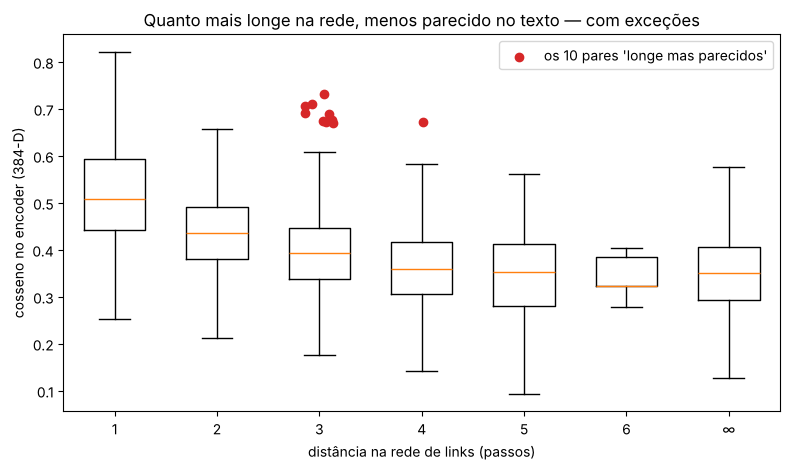

In [ ]:
UG = G.copy()
dist = dict(nx.all_pairs_shortest_path_length(UG))
iu = np.triu_indices(len(IDS), 1)
pp = pd.DataFrame(dict(a=[IDS[i] for i in iu[0]], b=[IDS[j] for j in iu[1]], cos=S_emb[iu]))
pp["hops"] = [dist[a].get(b, np.inf) for a, b in zip(pp.a, pp.b)]
pp["hops_c"] = pp.hops.replace(np.inf, 7)
print("cosseno médio por distância na rede:\n", pp.groupby("hops_c").cos.agg(["count", "mean"]).round(3).to_string())
top = pp.nlargest(1500, "cos")
far = top[top.hops >= 3].sort_values("cos", ascending=False)
print(f"\ndos 1500 pares mais parecidos no texto, {len(far)} estão a ≥3 passos (ou desligados) na rede. Os 10 primeiros:")
for _, r in far.head(10).iterrows():
    print(f"  {r.cos:.3f}  {name[r.a]:30s} × {name[r.b]:30s} passos: {r.hops if np.isfinite(r.hops) else '∞'}")

fig, ax = plt.subplots(figsize=(8, 4.8))
for h in sorted(pp.hops_c.unique()):
    v = pp[pp.hops_c == h].cos
    ax.boxplot(v, positions=[h], widths=0.6, showfliers=False)
ax.scatter(far.head(10).hops_c + np.random.default_rng(0).uniform(-0.15, 0.15, 10), far.head(10).cos, color="C3", zorder=3, label="os 10 pares 'longe mas parecidos'")
ax.set_xticks(sorted(pp.hops_c.unique())); ax.set_xticklabels([str(int(h)) if h < 7 else "∞" for h in sorted(pp.hops_c.unique())])
ax.set_xlabel("distância na rede de links (passos)"); ax.set_ylabel("cosseno no encoder (384-D)")
ax.set_title("Quanto mais longe na rede, menos parecido no texto — com exceções"); ax.legend()
plt.tight_layout(); plt.savefig("figs/7.13_semantic_vs_structural.png", dpi=150); plt.show()

In [ ]:
for _, r in far.head(3).iterrows():
    print(f"■ {name[r.a]} × {name[r.b]} (cos {r.cos:.3f}, passos {r.hops if np.isfinite(r.hops) else '∞'})")
    for pid in (r.a, r.b):
        print(f"   {name[pid]}: {re.sub(chr(10), ' ', marvel_pages[pid][:260])}…")
    print()

■ Doom 2099 × Kristoff Vernard (cos 0.731, passos 3.0)
   Doom 2099: Doom 2099 is an American comic book series published by Marvel Comics, featuring the fictional anti-hero Doom, aka Victor Von Doom. Created by writer John Francis Moore and artist Pat Broderick, the character first appeared in the Doom 2099 #1 (January 1993) a…
   Kristoff Vernard: Kristoff Vernard (formerly known as Kristoff von Doom and Dr. Doom) is a fictional character appearing in American comic books published by Marvel Comics. The adoptive son of Victor von Doom, he has been involved mainly with the Fantastic Four, as an enemy, al…

■ Isaiah Bradley × William Burnside (character) (cos 0.709, passos 3.0)
   Isaiah Bradley: Isaiah Bradley is one of the superheroes to hold the title of Captain America, appearing in American comic books published by Marvel Comics. The character is an early product of the United States' Super Soldier program (codenamed Project: Rebirth) during World…
   William Burnside (character):

**Rascunho do post (para o site do grupo).**

> **Close in meaning, far in the network.** The Wikipedia link network and a sentence encoder agree on a lot:
> pages one link apart have an average MiniLM cosine of 0.53, pages three links apart 0.39, and unconnected
> pages 0.35 (figure). But among the 1,500 most similar page pairs, 300 are three or more links apart. Reading
> the top of that list, they fall into two kinds. **Same role, different eras:** Isaiah Bradley and William
> Burnside are both men who held the Captain America title (the 1940s super-soldier experiment and the 1950s
> "Commie Smasher"); Doom 2099 and Kristoff Vernard are both versions of the Doctor Doom identity (a future Victor von Doom and Doom's adopted heir). Their pages tell
> the same kind of story, but they live in different decades of publishing and almost never link. **Shared
> codename words:** Blue Diamond × Blue Marvel, Iron Lad × Iron Man 2020 — a 1941 Timely hero and a modern
> hero share little but *Blue*. The encoder's "about-ness" is real (the first kind is a finding the
> link network cannot give us), but it also inherits a softer version of the TF-IDF surname trap (the second
> kind). What we checked: every pair above was read in the page openings shown in the notebook. Limitation:
> page vectors are means of 180-word passages, so one long shared section (a legacy, a title) can dominate.

**Crítica amigável (molde para comentar o post de outro grupo):** (1) qual é exatamente a unidade e a
representação (página inteira truncada? passagens? que modelo)? (2) os números de concordância vêm com um termo
de comparação (aleatório, outra representação)? (3) há pelo menos um exemplo lido no texto que explique o
padrão, e um que o contrarie?